NetSquid 1.1.8 | liboqs (SLH-DSA + ML-KEM) | cryptography HKDF
Documentazione caricata.
Costanti e seed inizializzati.
Modulo 1 (fisica + jitter) caricato.
Modulo 2A-D (BB84/SSP/EveIR) caricato.
Modulo 2E (E91 + CHSH) caricato.
Modulo 2F (MITM attivo) caricato.
Modulo 3 (Cascade completo + baseline semplificata v1.0) caricato.
Modulo 3B (decoy states) caricato.
Modulo 3C (firma PQ via liboqs — ML-DSA-65) caricato.
Modulo 3D (Hybrid KEM via liboqs + HKDF) caricato.
Modulo 4 (Toeplitz PA) caricato.
Modulo 5 (runner unificato BB84/SSP/E91) caricato.
Modulo 6 (AES-256-GCM) caricato.
Modulo 7 (No-Cloning + E91 security) caricato.
Modulo 8A (trade-off distanza + confronto E91) caricato.
Modulo 8B-E (analisi statistiche) caricato.
Modulo 8F (key rate reale con costo Cascade) caricato.
Modulo 8G (confronto PA) caricato.
Modulo 8H (fisica estesa + jitter) caricato.
Plot modello fisico (con jitter) caricato.
Modulo 9 (dashboard 12 pannelli) caricato.
Modulo 10 (conclusioni v2.0) caricato.
╔═════

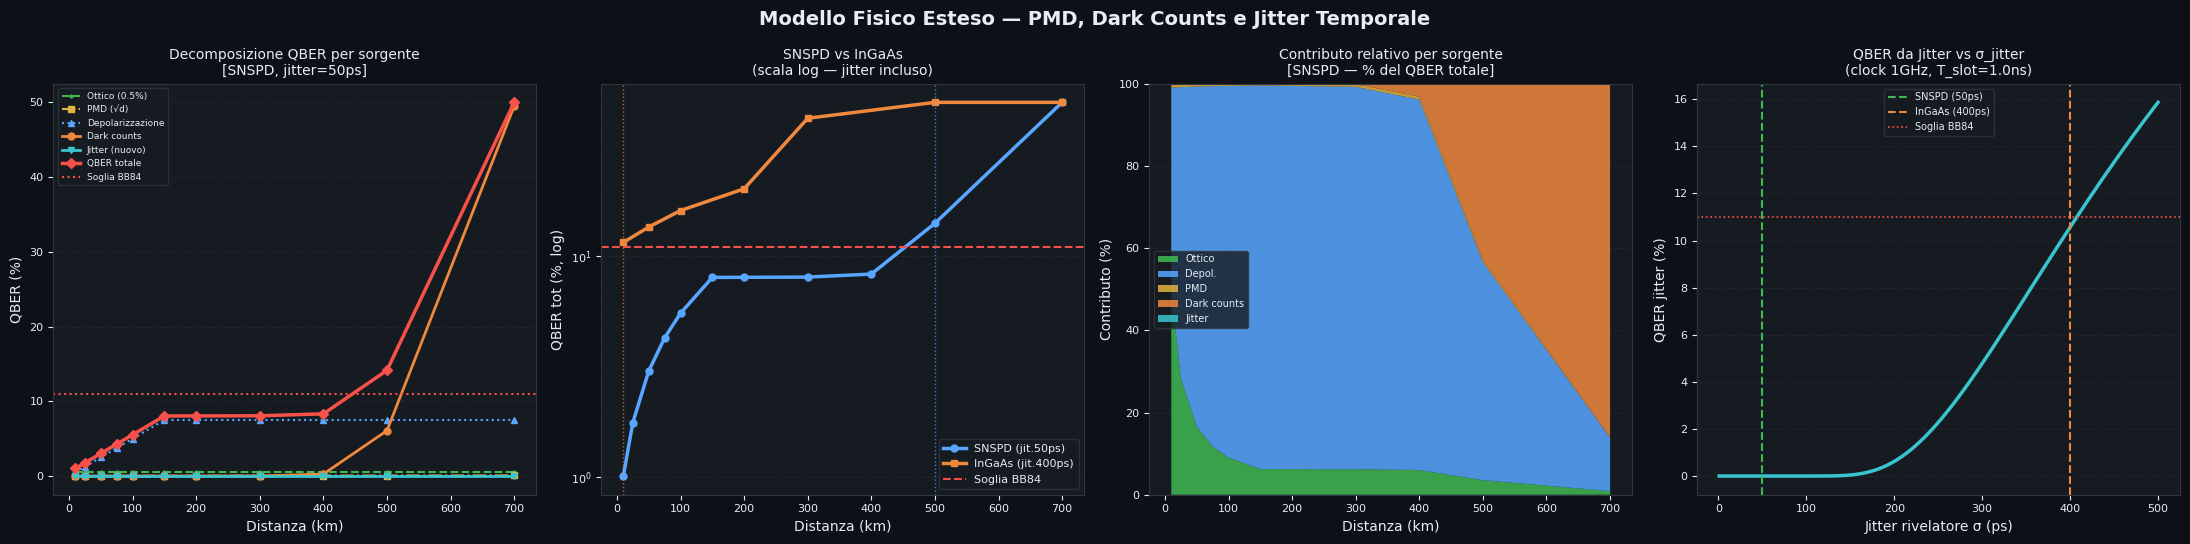


════════════════════════════════════════════════════════════
  FASE 6G: DECOY STATES — contromisura PNS attack
════════════════════════════════════════════════════════════

═══════════════════════════════════════════════════════════════════════════
  DECOY STATES — Analisi key rate LMC vs sorgente ideale
  mu_signal=0.5, mu_decoy=0.1
═══════════════════════════════════════════════════════════════════════════
    Dist |      Q_s |    E_s% |        Q1 |     e1% |      R_LMC |   R_ideal |    PNS%
  ───────────────────────────────────────────────────────────────────────────
     10km |  0.27716 |   2.50% |  0.194030 |   2.71% |   0.104907 |  0.183671 |    9.0%
     20km |  0.20872 |   2.50% |  0.139456 |   2.75% |   0.073293 |  0.138315 |    9.0%
     30km |  0.15537 |   2.50% |  0.100279 |   2.77% |   0.051534 |  0.102959 |    9.0%
     50km |  0.08410 |   2.50% |  0.051938 |   2.81% |   0.025889 |  0.055729 |    9.0%
     75km |  0.03807 |   2.50% |  0.022877 |   2.83% |   0.011177 |  0

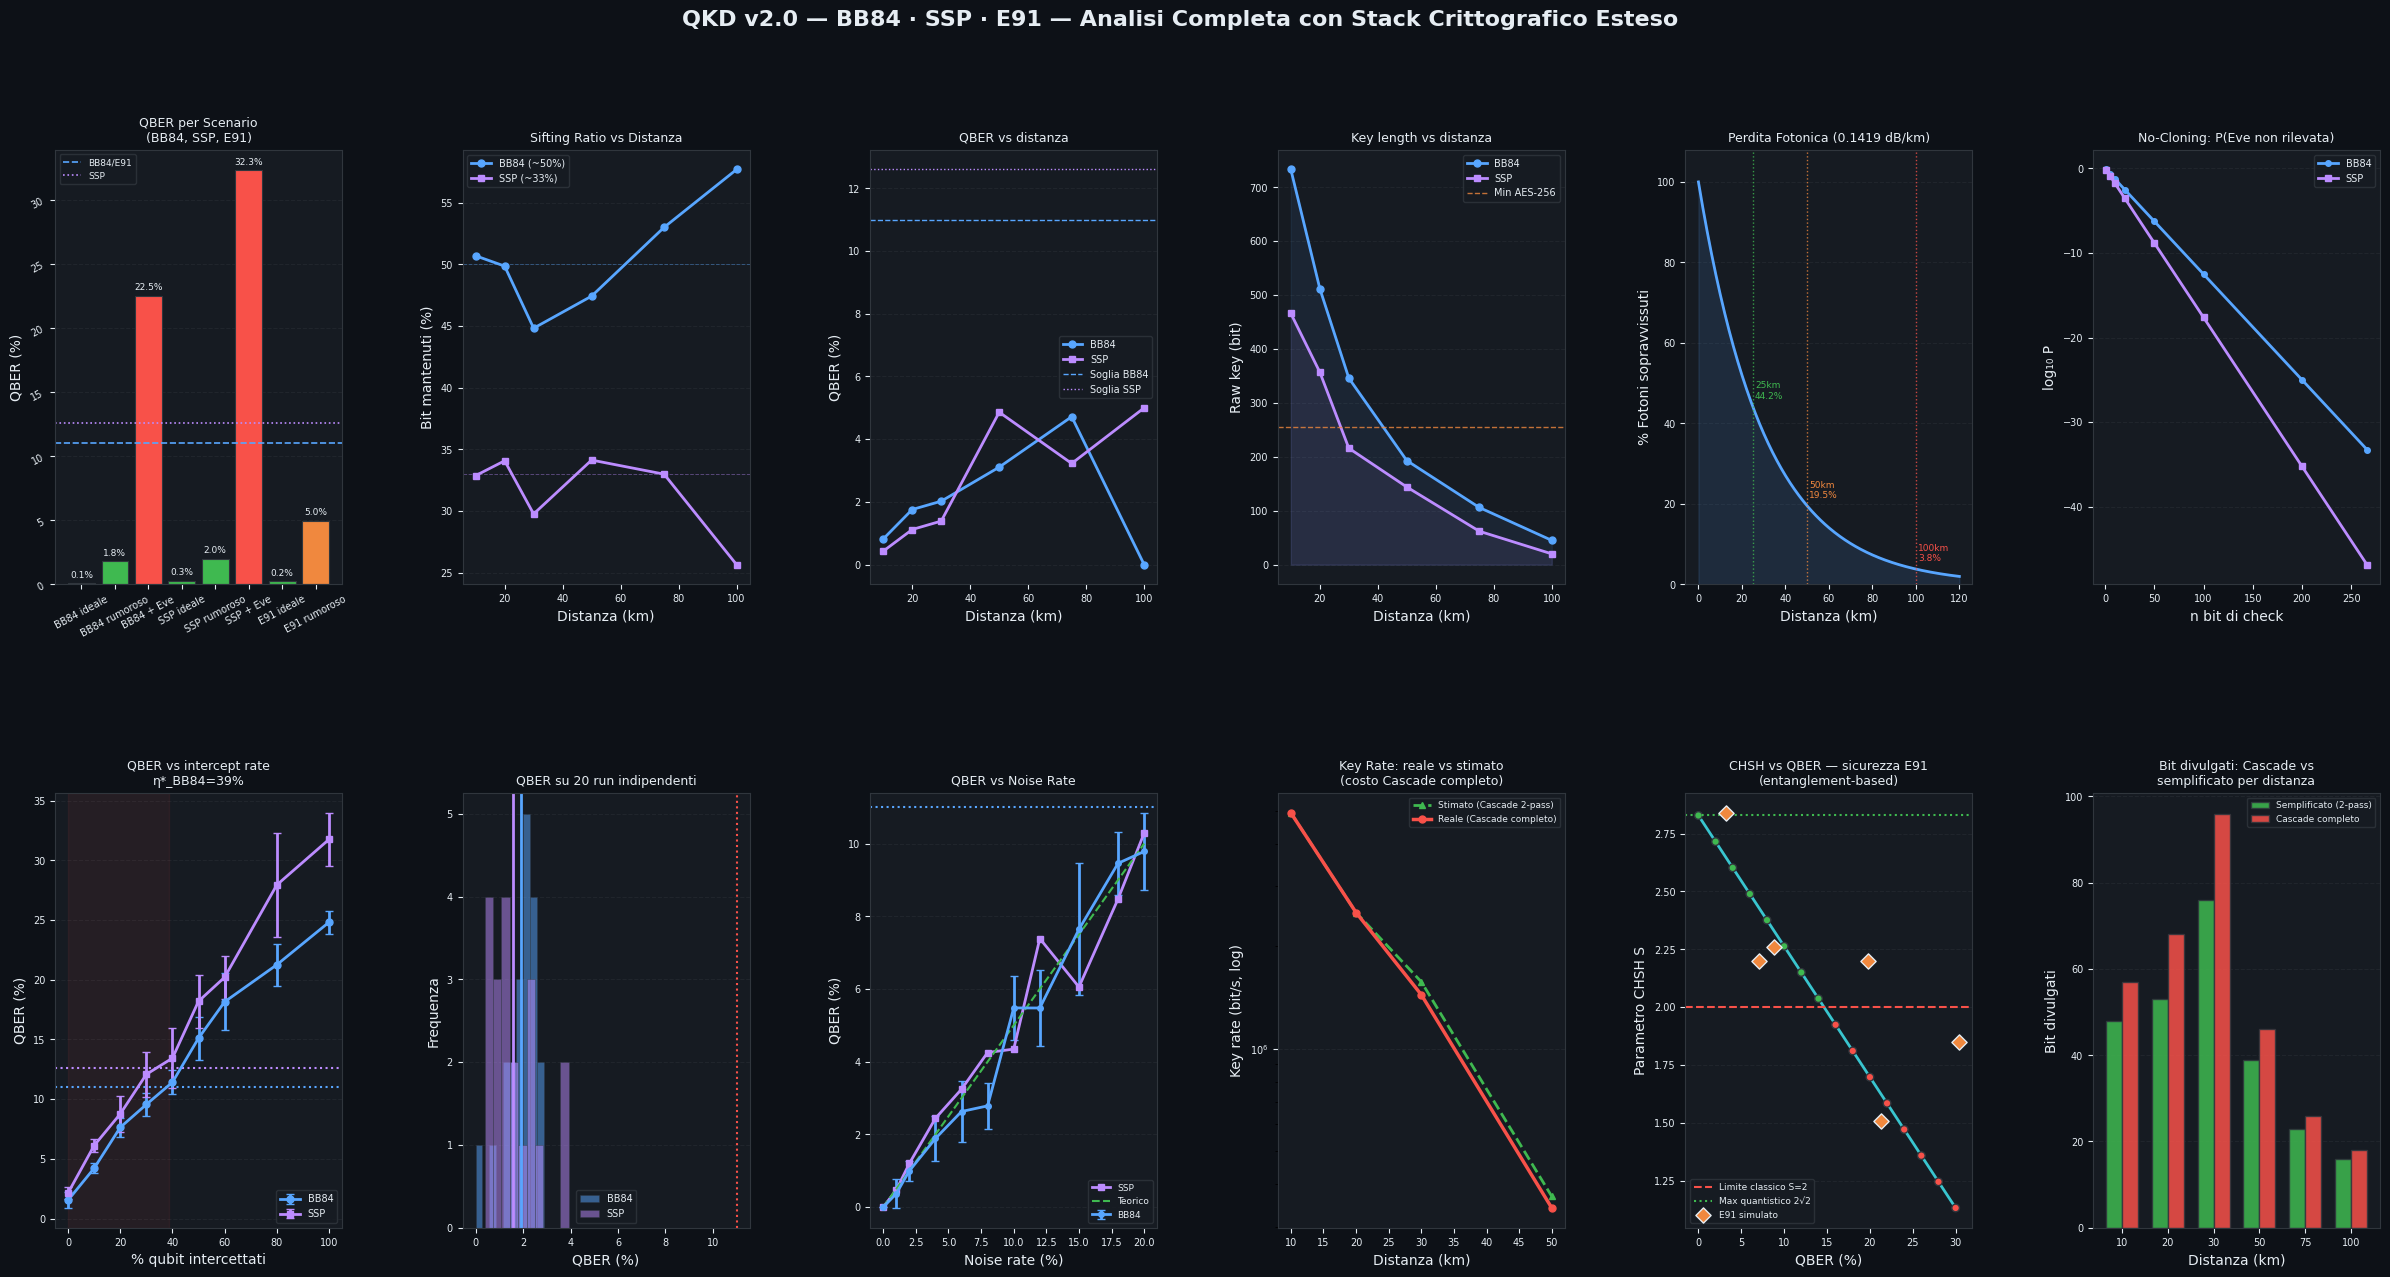



╔════════════════════════════════════════════════════════════════════════╗
║              CONCLUSIONI E DISCUSSIONE DEI RISULTATI — v2.0            ║
╚════════════════════════════════════════════════════════════════════════╝

──────────────────────────────────────────────────────────────────────────
 1. SICUREZZA DEL CANALE IN CONDIZIONI OPERATIVE NORMALI
──────────────────────────────────────────────────────────────────────────

Su 20 run indipendenti a 30km con noise_rate=4%:
    BB84:  QBER = 1.91% ± 0.66%
    SSP:   QBER = 1.58% ± 1.03%

La maggiore varianza SSP riflette il sifting ridotto (~33% vs ~50%): meno bit
su cui stimare il QBER implicano una stima piu' rumorosa.

──────────────────────────────────────────────────────────────────────────
 2. RICONCILIAZIONE — CASCADE COMPLETO vs SEMPLIFICATO
──────────────────────────────────────────────────────────────────────────

Il Cascade completo (Brassard & Salvail 1994, 4 passate
con effetto cascade ricorsivo) riduce sostanzialmen

In [3]:
# ══════════════════════════════════════════════════════════════════════════════
#  QKD v2.0 — BB84 · SSP · E91 — STACK CRITTOGRAFICO POST-QUANTUM COMPLETO
#  VERSIONE UNIFICATA: tutto il progetto in un'unica cella
#
#  Firma digitale e KEM post-quantum integrati via liboqs (Open Quantum Safe):
#    · SLH-DSA-SHAKE-128s (FIPS 205) — autenticazione del canale classico
#    · ML-DSA-65          (FIPS 204) — alternativa lattice-based, benchmark
#    · ML-KEM-768         (FIPS 203) — componente K1 dello scambio ibrido
#
#  Dipendenze:
#    pip install netsquid cryptography numpy matplotlib scipy pyspx
#    pip install liboqs-python          # firma + KEM post-quantum
#
#  liboqs-python compila la libreria C al primo import e richiede cmake +
#  ninja (e, su alcune build, gli header di OpenSSL). Se la compilazione
#  non riesce, il notebook resta comunque eseguibile: la firma ricade su
#  pyspx (SPHINCS+) e il KEM su X25519, con avviso esplicito in output.
#  In quel caso i risultati NON sono interamente post-quantum e il codice
#  lo dichiara invece di lasciarlo intendere.
# ══════════════════════════════════════════════════════════════════════════════


import netsquid as ns
import netsquid.qubits.qubitapi as qapi
from netsquid.nodes import Node
from netsquid.components import QuantumChannel
from netsquid.components.models import FibreDelayModel
from netsquid.components.models.qerrormodels import DepolarNoiseModel
from netsquid.protocols import NodeProtocol
from cryptography.hazmat.primitives.ciphers.aead import AESGCM
from cryptography.hazmat.primitives.kdf.hkdf import HKDF
from cryptography.hazmat.primitives import hashes as _hashes
# Firma digitale e KEM post-quantum: liboqs (Open Quantum Safe).
# Se liboqs non e' installato, il Modulo 3C ricade automaticamente su
# pyspx (SPHINCS+) e il Modulo 3D su X25519, segnalandolo esplicitamente.
# NOTA IMPORTANTE SULLA GESTIONE DELL'ERRORE DI IMPORT:
# liboqs-python, quando il pacchetto Python e' installato ma la libreria C
# condivisa non e' compilata, tenta di compilarla al volo e — se fallisce —
# chiama sys.exit(). Questo solleva SystemExit, che eredita da BaseException
# e NON da Exception: un "except Exception" (o "except ImportError") NON lo
# intercetta e l'intero notebook si interromperebbe al primo import.
# Si cattura quindi BaseException. Verificato sperimentalmente su una
# macchina senza cmake/OpenSSL-dev.
try:
    import oqs                          # liboqs-python: SLH-DSA, ML-DSA, ML-KEM
    _OQS_AVAILABLE = True
except BaseException:
    _OQS_AVAILABLE = False
import pyspx.shake_128s as sphincs      # fallback SPHINCS+-SHAKE-128s

import os, math, hashlib, random, struct
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.special import erfc

ns.sim_reset()
_pq_lib = "liboqs (SLH-DSA + ML-KEM)" if _OQS_AVAILABLE else "pyspx fallback (no liboqs)"
print(f"NetSquid {ns.__version__} | {_pq_lib} | cryptography HKDF")

_SDG_MATRIX = np.array([[1, 0], [0, -1j]], dtype=complex)
try:
    _SDG = ns.Sdg
except AttributeError:
    _SDG = ns.Operator("Sdg", _SDG_MATRIX)


"""
╔═══════════════════════════════════════════════════════════════════════════════╗
║        QKD AVANZATO: BB84 · SSP · E91 — STACK CRITTOGRAFICO COMPLETO         ║
║      Cascade Completo · Decoy States · liboqs PQ · ML-KEM · MITM Attivo     ║
╚═══════════════════════════════════════════════════════════════════════════════╝

ABSTRACT AGGIORNATO
═══════════════════
Versione 2.0 del progetto QKD. Rispetto alla versione 1.0, vengono implementate
otto estensioni scientificamente rilevanti:

1. CASCADE COMPLETO (Brassard & Salvail, Eurocrypt 1994):
   n passate con dimensione blocco adattiva k1 = floor(0.73/QBER), raddoppio
   geometrico (kj = 2^(j-1)·k1), effetto cascade ricorsivo (troncato a un
   livello per prestazioni) tra passate. Riduce fortemente — senza
   eliminarli del tutto — gli errori pari nello stesso blocco che il
   Cascade semplificato lascia sistematicamente passare; contabilizza con
   precisione i bit divulgati per la Privacy Amplification.

2. AUTENTICAZIONE POST-QUANTUM DEL CANALE CLASSICO (liboqs):
   ML-DSA-65 (FIPS 204, ex Dilithium) firma tutti i messaggi classici
   (sifting, parità, PA seed) tramite liboqs. Chiude il gap di
   autenticazione identificato: senza firma, Eve può falsificare annunci
   di base (MITM classico). La scelta di ML-DSA su SLH-DSA è motivata
   dall'overhead sul canale classico (~6.5 KB contro ~15.3 KB per
   sessione, e ~0.13 ms contro ~367 ms per firma), al prezzo dichiarato
   di far poggiare firma e KEM sulla stessa famiglia di assunzioni
   (reticoli) — vedi Modulo 3C. SLH-DSA-SHAKE-128s resta selezionabile.

3. DECOY STATES (Hwang 2003, Lo-Ma-Chen 2005):
   Modella sorgenti laser attenuate con distribuzione poissoniana del numero di
   fotoni. Implementa il lower bound GLLP/LMC per il key rate reale, includenendo
   la contromisura al Photon-Number-Splitting (PNS) attack.

4. PROTOCOLLO E91 (Ekert 1991):
   Terzo paradigma QKD basato su coppie entangled (stato di Bell |Φ+⟩).
   Sicurezza garantita da violazione della disuguaglianza CHSH (S > 2 quantistico,
   S ≤ 2 classico). Confronto con BB84: prepare-and-measure vs entanglement-based.

5. HYBRID KEM ML-KEM-768 (liboqs) — AUTENTICAZIONE IBRIDA:
   ML-KEM-768 reale (FIPS 203, ex Kyber) via liboqs, non più il
   placeholder X25519. Chiave finale derivata via HKDF:
   K_finale = HKDF(K1 || K2_QKD, salt, info).
   Sicurezza composita POST-QUANTUM: entrambe le componenti resistono a
   un avversario quantistico, ma per ragioni indipendenti — K1 per
   durezza computazionale (MLWE), K2 per garanzia information-theoretic.
   I due lati falliscono per cause scorrelate: difesa in profondità reale.

6. MODELLO JITTER TEMPORALE DEI RIVELATORI:
   I rivelatori reali hanno timing jitter σ_j ~ 50-200 ps (SNSPD).
   Con clock 1GHz (T_slot = 1 ns), jitter causa interferenza tra slot adiacenti.
   QBER_jitter = erfc(T_slot / (2√2·σ_j)) / 2 — contributo aggiuntivo al QBER.

7. ATTACCO MAN-IN-THE-MIDDLE ATTIVO (canale classico + quantistico):
   Eve si interpone su entrambi i canali: intercetta i qubit (IR attack) E forgia
   gli annunci di sifting di Alice sul canale classico. Senza autenticazione, Eve
   controlla la chiave condivisa senza aumentare il QBER osservato. Con la
   firma PQ attiva la forgiatura è computazionalmente impossibile → MITM
   bloccato.
   Il blocco è verificato con un CONTROLLO NEGATIVO esplicito (le basi
   manomesse da Eve devono essere RIFIUTATE), non solo constatando che la
   firma legittima è valida.

8. KEY RATE REALE CON COSTO CASCADE COMPLETO:
   Il Cascade completo rivela più bit del Cascade semplificato.
   Key rate corretto: R = (n_sifted - bits_cascade - PA_cost) / t_sessione
   Confronto esplicito: key rate semplificato vs key rate Cascade completo.

ARCHITETTURA DEL CODICE v2.0
══════════════════════════════
Modulo 1   — Fisica del canale: Beer-Lambert + PMD + dark counts + jitter
Modulo 2   — Protocolli: AliceBB84/SSP, BobBB84/SSP, EveIR, Alice/BobE91, EveMITM
Modulo 3   — Cascade completo: 4 passate, effetto cascade ricorsivo
Modulo 3B  — Decoy states: modello poissoniano, bound LMC, PNS analysis
Modulo 3C  — Firma PQ liboqs (ML-DSA/SLH-DSA): sign/verify + benchmark
Modulo 3D  — Hybrid KEM ML-KEM-768 via liboqs + HKDF
Modulo 4   — Privacy Amplification: Toeplitz hashing (invariato)
Modulo 5   — Runner: BB84/SSP/E91 unificato
Modulo 6   — AES-256-GCM (invariato)
Modulo 7   — No-Cloning analysis (invariato)
Modulo 8A-H — Analisi trade-off (invariata + key rate esteso)
Modulo 9   — Dashboard 12 pannelli (aggiornata)
Modulo 10  — Conclusioni (aggiornate)
"""
print("Documentazione caricata.")


# ══════════════════════════════════════════════════════════════════════
#  COSTANTI FISICHE E DI PROTOCOLLO
# ══════════════════════════════════════════════════════════════════════

FIBRE_ATTENUATION_DB_PER_KM = 0.1419   # dB/km — fibra PSCF + SNSPD
QBER_THRESHOLD_BB84          = 11.0    # % — soglia teorica BB84
QBER_THRESHOLD_SSP           = 12.6   # % — soglia teorica SSP
QBER_THRESHOLD_E91           = 11.0   # % — soglia E91 (equivalente a BB84)
DARK_COUNT_RATE_HZ           = 10.0   # Hz — SNSPD stato dell'arte
DETECTOR_GATE_NS             = 1.0    # ns — finestra temporale rivelatore
LIGHT_SPEED_FIBRE            = 2e8    # m/s
PMD_COEFFICIENT_PS           = 0.06   # ps/√km — fibra PSCF ULL

# ── Nuovo: jitter temporale dei rivelatori (Modulo 1 esteso) ──────────
JITTER_SNSPD_PS   = 50.0    # ps — SNSPD stato dell'arte (10-100 ps tipico)
JITTER_INGAAS_PS  = 400.0   # ps — InGaAs/InP commerciale
CLOCK_PERIOD_NS   = 1.0     # ns — sistema a 1 GHz

# ── Nuovo: parametri decoy states ─────────────────────────────────────
MU_SIGNAL  = 0.5    # fotoni medi stato segnale (standard QKD)
MU_DECOY1  = 0.1    # fotoni medi stato decoy 1
MU_DECOY2  = 0.0    # stato vacuum (decoy 2)

# ── Nuovo: angoli E91 (gradi) ─────────────────────────────────────────
# Alice misura in: 0°, 45°, 90°
# Bob misura in:   45°, 90°, 135°
E91_ALICE_ANGLES = [0.0, 45.0, 90.0]    # gradi
E91_BOB_ANGLES   = [45.0, 90.0, 135.0] # gradi
# CHSH usa coppie: (a1,b1),(a1,b3),(a3,b1),(a3,b3)
# = (0°,45°), (0°,135°), (90°,45°), (90°,135°)


def set_global_seed(seed=None):
    if seed is None:
        seed = int(np.random.default_rng().integers(0, 2**31))
    np.random.seed(seed)
    random.seed(seed)
    return seed

set_global_seed(42)
print("Costanti e seed inizializzati.")


# ══════════════════════════════════════════════════════════════════════
#  MODULO 1: FISICA DEL CANALE — aggiornato con jitter temporale
# ══════════════════════════════════════════════════════════════════════

def photon_survival_probability(distance_km):
    return 10 ** (-FIBRE_ATTENUATION_DB_PER_KM * distance_km / 10)


def compute_pmd_qber(distance_km, pmd_coeff=PMD_COEFFICIENT_PS):
    dgd_ps   = pmd_coeff * math.sqrt(distance_km)
    t_bit_ps = 1000.0
    return min(0.5 * (dgd_ps / t_bit_ps) * 100, 50.0)


def compute_dark_count_qber(distance_km, dark_rate_hz=DARK_COUNT_RATE_HZ,
                             gate_ns=DETECTOR_GATE_NS):
    p_survive    = photon_survival_probability(distance_km)
    eta_detector = 0.9 if dark_rate_hz <= 100 else 0.20
    p_signal     = p_survive * eta_detector
    p_dark       = dark_rate_hz * (gate_ns * 1e-9)
    denom        = 2.0 * (p_signal + p_dark)
    return min((p_dark / denom * 100) if denom > 1e-30 else 50.0, 50.0)


def compute_jitter_qber(jitter_ps=JITTER_SNSPD_PS,
                         clock_period_ns=CLOCK_PERIOD_NS,
                         detector_type="SNSPD"):
    """
    ══════════════════════════════════════════════════════════
    JITTER TEMPORALE DEI RIVELATORI — Contributo al QBER
    ══════════════════════════════════════════════════════════
    In un sistema QKD a variabile temporale, ogni qubit arriva
    in una finestra di tempo (time bin) di durata T_slot.
    Il rivelatore ha un jitter temporale σ_j che causa:
    - Click tardivi: il fotone del time bin i viene registrato
      nel time bin i+1 (errore di identificazione)
    - Click anticipati: analogo ma verso i-1

    Modello gaussiano del jitter (Hadfield, Nat. Phot. 2009):
        P(jitter > T_slot/2) = erfc(T_slot / (2√2 · σ_j)) / 2

    Questa probabilità è la frazione di click che "migrano" al
    bin adiacente, producendo errori di timing.

    QBER aggiuntivo da jitter:
        QBER_jitter ≈ P(jitter > T_slot/2) [fraction]

    Il fattore 1/2 non si applica qui perché un click nel bin
    sbagliato causa errore con probabilità ~1 (il bit è sbagliato
    per definizione se attribuito al bin errato).

    Valori tipici (ricalcolati numericamente da scipy.special.erfc —
    i valori precedenti di questa nota erano affetti da un errore di
    trascrizione fino a 3 ordini di grandezza su alcune righe):
        SNSPD  (σ_j=50ps,  T_slot=1ns): QBER_j = erfc(7.07)/2  ≈ 7.6×10⁻²²  %
        SNSPD  (σ_j=100ps, T_slot=1ns): QBER_j = erfc(3.54)/2  ≈ 2.9×10⁻⁵   %
        InGaAs (σ_j=400ps, T_slot=1ns): QBER_j = erfc(0.88)/2  ≈ 10.6       %
        InGaAs (σ_j=400ps, T_slot=2ns): QBER_j = erfc(1.77)/2  ≈ 0.62       %

    Implicazione per il design:
        Con clock 1GHz e InGaAs: jitter è il fattore dominante!
        SNSPD permette clock fino a ~5GHz prima che jitter diventi rilevante.
    ══════════════════════════════════════════════════════════
    """
    if detector_type == "InGaAs":
        sigma = JITTER_INGAAS_PS
    else:
        sigma = jitter_ps  # SNSPD

    t_slot_ps = clock_period_ns * 1000.0  # converti ns → ps

    # Probabilità che il jitter sposti il click al bin adiacente
    if sigma <= 0:
        return 0.0
    x = t_slot_ps / (2.0 * math.sqrt(2.0) * sigma)
    p_cross = erfc(x) / 2.0
    return min(p_cross * 100.0, 50.0)  # in percentuale


def compute_total_physical_qber(distance_km, base_noise=0.0,
                                  pmd_coeff=PMD_COEFFICIENT_PS,
                                  dark_rate_hz=DARK_COUNT_RATE_HZ,
                                  detector_type="SNSPD",
                                  jitter_ps=JITTER_SNSPD_PS,
                                  clock_period_ns=CLOCK_PERIOD_NS):
    """
    QBER fisico totale: ottico + depol + PMD + dark counts + jitter.

    I contributi sono sommati (approssimazione valida per QBER piccoli, dove
    i termini incrociati sono trascurabili) e poi TRONCATI a 50%, che e' il
    massimo fisicamente sensato: a 50% il canale non trasporta informazione.
    Il valore pre-troncamento resta disponibile in 'qber_total_unclamped' e
    il flag 'qber_saturated' segnala quando il clamp e' intervenuto — utile
    per non presentare come "misura" un punto in cui il modello additivo ha
    gia' perso validita'.
    """
    dr = 10000.0 if detector_type == "InGaAs" else dark_rate_hz
    jp = JITTER_INGAAS_PS if detector_type == "InGaAs" else jitter_ps

    qber_pmd    = compute_pmd_qber(distance_km, pmd_coeff)
    qber_dark   = compute_dark_count_qber(distance_km, dark_rate_hz=dr)
    qber_jitter = compute_jitter_qber(jp, clock_period_ns, detector_type)
    qber_opt    = 0.5
    qber_depol  = base_noise / 2 * 100

    # CLAMP FISICO A 50%.
    # I contributi sono modellati come additivi, ma la loro SOMMA non lo e':
    # un QBER > 50% e' fisicamente impossibile in un protocollo binario.
    # A 50% la misura di Bob e' rumore puro (nessuna informazione mutua);
    # oltre, Bob otterrebbe risultati migliori invertendo ogni bit, il che
    # equivale a un QBER < 50%. Senza clamp il modello produceva valori come
    # 71.14% (700km, InGaAs), privi di significato fisico.
    qber_total_raw = qber_opt + qber_depol + qber_pmd + qber_dark + qber_jitter
    qber_total = min(qber_total_raw, 50.0)

    return {
        "distance_km":   distance_km,
        "qber_optical":  qber_opt,
        "qber_depol":    qber_depol,
        "qber_pmd":      qber_pmd,
        "qber_dark":     qber_dark,
        "qber_jitter":   qber_jitter,
        "qber_total":    qber_total,
        "qber_total_unclamped": qber_total_raw,   # diagnostico: pre-clamp
        "qber_saturated": qber_total_raw > 50.0,  # True se il clamp e' scattato
        "detector":      detector_type,
        "dominant":      ("jitter" if qber_jitter > qber_dark
                          else ("dark" if qber_dark > qber_depol + qber_pmd
                                else "depol")),
    }


def apply_photon_loss(num_bits, distance_km, min_photons=0):
    """
    Campiona il numero di fotoni sopravvissuti alla tratta (binomiale).

    CORREZIONE — il floor max(arrived, 10) della stesura precedente:
    la versione originale restituiva SEMPRE almeno 10 fotoni. Oltre i
    ~200 km il valore atteso scende sotto 1 (a 1000 km e' ~1e-11), quindi
    la binomiale dava 0 e la funzione ne inventava 10: il simulatore
    processava fotoni che fisicamente non sarebbero mai arrivati.

    Le righe long-haul delle tabelle mostravano comunque "0b" di chiave,
    ma per un motivo sbagliato — non per esaurimento fotonico, bensi'
    perche' i 10 fotoni fittizi producevano <20 bit siftati e facevano
    scattare il controllo a valle. Il risultato era giusto per caso, non
    per costruzione, e i QBER stampati su quelle righe (0.00%) erano
    calcolati su un campione inventato.

    Ora il default e' min_photons=0: se non arriva nulla, non arriva
    nulla, e i chiamanti gestiscono il caso degenere esplicitamente.
    """
    p = photon_survival_probability(distance_km)
    arrived = int(np.random.binomial(num_bits, p))
    return max(arrived, min_photons), p

print("Modulo 1 (fisica + jitter) caricato.")


# ══════════════════════════════════════════════════════════════════════
#  MODULO 2A-D: PROTOCOLLI NETSQUID — BB84 e SSP (invariati)
# ══════════════════════════════════════════════════════════════════════

class AliceBB84Protocol(NodeProtocol):
    def __init__(self, node, bits, bases):
        super().__init__(node)
        self.bits = bits; self.bases = bases
    def run(self):
        for i in range(len(self.bits)):
            q, = qapi.create_qubits(1)
            if self.bases[i] == 0:
                if self.bits[i] == 1: qapi.operate(q, ns.X)
            else:
                if self.bits[i] == 0: qapi.operate(q, ns.H)
                else: qapi.operate(q, ns.X); qapi.operate(q, ns.H)
            self.node.ports["cout_q"].tx_output(q)
            yield self.await_timer(1)

class AliceSSPProtocol(NodeProtocol):
    def __init__(self, node, bits, bases):
        super().__init__(node)
        self.bits = bits; self.bases = bases
    def run(self):
        for i in range(len(self.bits)):
            q, = qapi.create_qubits(1)
            b = self.bases[i]
            if b == 0:
                if self.bits[i] == 1: qapi.operate(q, ns.X)
            elif b == 1:
                if self.bits[i] == 0: qapi.operate(q, ns.H)
                else: qapi.operate(q, ns.X); qapi.operate(q, ns.H)
            else:  # base Y
                if self.bits[i] == 0: qapi.operate(q, ns.H)
                else: qapi.operate(q, ns.X); qapi.operate(q, ns.H)
                qapi.operate(q, ns.S)
            self.node.ports["cout_q"].tx_output(q)
            yield self.await_timer(1)

class BobBB84Protocol(NodeProtocol):
    def __init__(self, node, bases):
        super().__init__(node)
        self.bases = bases
        self.results = np.zeros(len(bases), dtype=int)
    def run(self):
        for i in range(len(self.bases)):
            yield self.await_port_input(self.node.ports["cin_q"])
            msg = self.node.ports["cin_q"].rx_input()
            qubit = msg.items[0]
            if self.bases[i] == 1: qapi.operate(qubit, ns.H)
            res, _ = qapi.measure(qubit, ns.Z)
            self.results[i] = res

class BobSSPProtocol(NodeProtocol):
    def __init__(self, node, bases):
        super().__init__(node)
        self.bases = bases
        self.results = np.zeros(len(bases), dtype=int)
    def run(self):
        for i in range(len(self.bases)):
            yield self.await_port_input(self.node.ports["cin_q"])
            msg = self.node.ports["cin_q"].rx_input()
            qubit = msg.items[0]
            b = self.bases[i]
            if b == 1: qapi.operate(qubit, ns.H)
            elif b == 2: qapi.operate(qubit, _SDG); qapi.operate(qubit, ns.H)
            res, _ = qapi.measure(qubit, ns.Z)
            self.results[i] = res

class EveInterceptResendProtocol(NodeProtocol):
    def __init__(self, node, num_bits, num_bases=2, intercept_rate=1.0):
        super().__init__(node)
        self.num_bits = num_bits; self.num_bases = num_bases
        self.intercept_rate = intercept_rate
        self.intercept_mask = np.random.random(num_bits) < intercept_rate
        self.eve_bases = np.random.randint(num_bases, size=num_bits)
        self.eve_results = np.zeros(num_bits, dtype=int)
    def run(self):
        for i in range(self.num_bits):
            yield self.await_port_input(self.node.ports["cin_q"])
            msg = self.node.ports["cin_q"].rx_input()
            qubit = msg.items[0]
            if not self.intercept_mask[i]:
                self.node.ports["cout_q"].tx_output(qubit)
                yield self.await_timer(1); continue
            b = self.eve_bases[i]
            if b == 1: qapi.operate(qubit, ns.H)
            elif b == 2: qapi.operate(qubit, _SDG); qapi.operate(qubit, ns.H)
            res, _ = qapi.measure(qubit, ns.Z)
            self.eve_results[i] = res
            new_q, = qapi.create_qubits(1)
            if b == 0:
                if res == 1: qapi.operate(new_q, ns.X)
            elif b == 1:
                if res == 0: qapi.operate(new_q, ns.H)
                else: qapi.operate(new_q, ns.X); qapi.operate(new_q, ns.H)
            else:
                if res == 0: qapi.operate(new_q, ns.H)
                else: qapi.operate(new_q, ns.X); qapi.operate(new_q, ns.H)
                qapi.operate(new_q, ns.S)
            self.node.ports["cout_q"].tx_output(new_q)
            yield self.await_timer(1)

print("Modulo 2A-D (BB84/SSP/EveIR) caricato.")


# ══════════════════════════════════════════════════════════════════════
#  MODULO 2E: PROTOCOLLO E91 — Ekert 1991, entanglement-based QKD
# ══════════════════════════════════════════════════════════════════════

_RY_OPERATOR_CACHE = {}

def _get_ry_operator(angle_deg):
    """
    ══════════════════════════════════════════════════════════
    OPERATORE DI ROTAZIONE R_y(θ) — misura lungo un angolo di Bloch
    ══════════════════════════════════════════════════════════
    Per il test CHSH servono misure lungo angoli generici (0°, 45°,
    90°, 135°) sul cerchio massimo X-Z della sfera di Bloch. I gate
    Clifford standard (H, S) da soli permettono di raggiungere SOLO
    le direzioni cardinali (0°, 90°, 180°, 270°): H sposta l'asse di
    misura di 90° (Z→X), non di 45°. Per ottenere realmente 45°/135°
    serve una rotazione generica, costruita qui esplicitamente come
    matrice — stesso approccio già usato nel file originale per il
    gate S† (Sdg), che non è garantito come builtin in ogni versione
    di NetSquid:

        R_y(θ) = [[cos(θ/2), -sin(θ/2)],
                  [sin(θ/2),  cos(θ/2)]]

    Per misurare lungo l'angolo di Bloch θ, si applica R_y(-θ) e poi
    si misura in base Z. Con questa convenzione e lo stato |Φ+⟩,
    la correlazione risultante è E(a,b) = cos(a−b) — verificato
    analiticamente e numericamente (simulazione Born-rule diretta,
    S_CHSH = 2.83 ≈ 2√2 con gli angoli di Ekert 0°/45°/90°/135°).
    Per θ=0° non serve alcuna rotazione (operatore identità).
    ══════════════════════════════════════════════════════════
    """
    key = round(angle_deg % 360, 6)
    if key == 0.0:
        return None  # nessuna rotazione necessaria
    if key in _RY_OPERATOR_CACHE:
        return _RY_OPERATOR_CACHE[key]
    t = math.radians(angle_deg) / 2.0
    matrix = np.array([[math.cos(t), -math.sin(t)],
                        [math.sin(t),  math.cos(t)]], dtype=complex)
    op = ns.Operator(f"Ry_{key:.3f}", matrix)
    _RY_OPERATOR_CACHE[key] = op
    return op


class AliceE91Protocol(NodeProtocol):
    """
    ══════════════════════════════════════════════════════════
    PROTOCOLLO E91 — Ekert, Physical Review Letters 1991
    ══════════════════════════════════════════════════════════
    A differenza di BB84 (prepare-and-measure), E91 usa
    coppie di fotoni entangled nello stato di Bell |Φ+⟩:

        |Φ+⟩ = (|00⟩ + |11⟩) / √2

    Questa sorgente distribuisce un qubit ad Alice e uno a Bob.

    Alice misura in 3 angoli: 0°, 45°, 90°
    Bob misura in 3 angoli:   45°, 90°, 135°

    Sifting E91:
    ─────────────
    Alice e Bob usano la stessa base (45° o 90°) → bit correlati → KEY
    Alice e Bob usano basi diverse → usati per il test CHSH → SECURITY

    CHSH test:
    ──────────
    S = |E(0°,45°) - E(0°,135°) + E(90°,45°) + E(90°,135°)|
    dove E(a,b) = correlazione tra misure di Alice in a e Bob in b.

    Meccanica quantistica: S = 2√2 ≈ 2.828 (violazione Bell)
    Teoria locale nascosta: S ≤ 2

    Se S > 2: i qubit sono genuinamente entangled → nessun MITM possibile
    (un MITM avrebbe interrotto l'entanglement, riducendo S verso 2).

    Nota implementativa:
    ─────────────────────
    In NetSquid, prepariamo lo stato entangled |Φ+⟩ localmente
    e inviamo un qubit ad Alice e uno a Bob. La sorgente è
    modellata come nodo intermedio (Source).
    ══════════════════════════════════════════════════════════
    """
    def __init__(self, node, angle_choices):
        super().__init__(node)
        self.angle_choices = angle_choices  # angoli in gradi per ogni qubit
        self.results = np.zeros(len(angle_choices), dtype=int)

    def _rotate_and_measure(self, qubit, angle_deg):
        """Misura lungo l'angolo di Bloch specificato tramite rotazione R_y(-θ)."""
        op = _get_ry_operator(-angle_deg)
        if op is not None:
            qapi.operate(qubit, op)
        res, _ = qapi.measure(qubit, ns.Z)
        return res

    def run(self):
        for i in range(len(self.angle_choices)):
            yield self.await_port_input(self.node.ports["cin_q"])
            msg = self.node.ports["cin_q"].rx_input()
            qubit = msg.items[0]
            self.results[i] = self._rotate_and_measure(qubit, self.angle_choices[i])


class BobE91Protocol(NodeProtocol):
    """Bob nel protocollo E91 — specchio di AliceE91."""
    def __init__(self, node, angle_choices):
        super().__init__(node)
        self.angle_choices = angle_choices
        self.results = np.zeros(len(angle_choices), dtype=int)

    def _rotate_and_measure(self, qubit, angle_deg):
        op = _get_ry_operator(-angle_deg)
        if op is not None:
            qapi.operate(qubit, op)
        res, _ = qapi.measure(qubit, ns.Z)
        return res

    def run(self):
        for i in range(len(self.angle_choices)):
            yield self.await_port_input(self.node.ports["cin_q"])
            msg = self.node.ports["cin_q"].rx_input()
            qubit = msg.items[0]
            self.results[i] = self._rotate_and_measure(qubit, self.angle_choices[i])


class EntanglementSourceProtocol(NodeProtocol):
    """
    Sorgente di coppie entangled |Φ+⟩ = (|00⟩+|11⟩)/√2.
    Invia un qubit ad Alice e uno a Bob attraverso canali separati.
    """
    def __init__(self, node, n_pairs, noise_rate=0.02):
        super().__init__(node)
        self.n_pairs = n_pairs
        self.noise_rate = noise_rate

    def run(self):
        for _ in range(self.n_pairs):
            q_a, q_b = qapi.create_qubits(2)
            # Prepara |Φ+⟩ = H⊗I · CNOT · |00⟩
            qapi.operate(q_a, ns.H)
            qapi.operate([q_a, q_b], ns.CNOT)
            # Canale di rumore (depolarizzazione)
            if self.noise_rate > 0:
                for q in [q_a, q_b]:
                    if np.random.random() < self.noise_rate:
                        op = np.random.choice([ns.X, ns.Y, ns.Z])
                        qapi.operate(q, op)
            self.node.ports["cout_alice"].tx_output(q_a)
            self.node.ports["cout_bob"].tx_output(q_b)
            yield self.await_timer(1)


def compute_chsh_parameter(alice_results, bob_results,
                            alice_angles, bob_angles):
    """
    ══════════════════════════════════════════════════════════
    PARAMETRO CHSH S — Clauser-Horne-Shimony-Holt 1969
    ══════════════════════════════════════════════════════════
    Calcola S = |E(a1,b1) - E(a1,b3) + E(a3,b1) + E(a3,b3)|

    dove E(a,b) = correlazione media tra misure in angoli a e b:
        E(a,b) = (N++ + N-- - N+- - N-+) / (N++ + N-- + N+- + N-+)
    (N++ = entrambi ottengono +1, ecc.)

    Valori di riferimento:
        S = 0:      nessuna correlazione
        S = 2:      limite classico (disuguaglianza di Bell)
        S = 2√2 ≈ 2.828: limite quantistico (massima violazione)
        S > 2:      entanglement genuino, sicurezza E91 garantita

    Quadruplette CHSH per E91 con basi Alice {0°,45°,90°} e Bob {45°,90°,135°}:
        (a1, b1) = (0°,  45°)   E(0°,45°)
        (a1, b3) = (0°,  135°)  E(0°,135°)
        (a3, b1) = (90°, 45°)   E(90°,45°)
        (a3, b3) = (90°, 135°)  E(90°,135°)
    ══════════════════════════════════════════════════════════
    """
    def correlation(a_results, b_results, a_angle, b_angle):
        n_pp = n_mm = n_pm = n_mp = 0
        for a, b, ang_a, ang_b in zip(a_results, b_results,
                                       alice_angles, bob_angles):
            if abs(ang_a - a_angle) < 1e-6 and abs(ang_b - b_angle) < 1e-6:
                a_pm1 = +1 if a == 0 else -1
                b_pm1 = +1 if b == 0 else -1
                if a_pm1 == +1 and b_pm1 == +1: n_pp += 1
                elif a_pm1 == -1 and b_pm1 == -1: n_mm += 1
                elif a_pm1 == +1 and b_pm1 == -1: n_pm += 1
                else: n_mp += 1
        n_tot = n_pp + n_mm + n_pm + n_mp
        if n_tot == 0: return 0.0
        return (n_pp + n_mm - n_pm - n_mp) / n_tot

    e_a1_b1 = correlation(alice_results, bob_results, 0.0,  45.0)
    e_a1_b3 = correlation(alice_results, bob_results, 0.0,  135.0)
    e_a3_b1 = correlation(alice_results, bob_results, 90.0, 45.0)
    e_a3_b3 = correlation(alice_results, bob_results, 90.0, 135.0)

    S = abs(e_a1_b1 - e_a1_b3 + e_a3_b1 + e_a3_b3)
    return S, e_a1_b1, e_a1_b3, e_a3_b1, e_a3_b3


def run_e91_protocol(num_pairs=400, distance=30.0, noise_rate=0.02,
                     verbose=True):
    """
    Runner completo del protocollo E91.
    Ritorna (is_safe, key_bits, stats) con CHSH come test di sicurezza.
    """
    ns.sim_reset()
    effective, p_survive = apply_photon_loss(num_pairs, distance)
    if effective < 1:
        if verbose:
            print(f"\n[E91] {distance}km: nessuna coppia arrivata "
                  f"(p_surv={p_survive:.2e}) — sessione impossibile")
        return False, None, {"protocol": "E91", "distance_km": distance,
                              "noise": noise_rate, "photons_sent": num_pairs,
                              "photons_arrived": 0, "survival_prob": p_survive,
                              "raw_len": 0, "sift_ratio": 0.0, "qber": 0.0,
                              "S_chsh": 0.0, "chsh_ok": False, "safe": False,
                              "mode": "E91", "eve_present": False,
                              "threshold": QBER_THRESHOLD_E91, "key_bob": None,
                              "pa_output_bits": 0, "pa_available_bits": 0,
                              "pa": None, "bits_disclosed": 0}

    if verbose:
        print(f"\n[E91] {effective}/{num_pairs} coppie entangled | "
              f"{distance}km | rumore {noise_rate*100:.1f}%")

    # Angoli scelti uniformemente per ogni coppia
    alice_angle_choices = np.random.choice(E91_ALICE_ANGLES, size=effective)
    bob_angle_choices   = np.random.choice(E91_BOB_ANGLES,   size=effective)

    # ── Nodi ──────────────────────────────────────────────────
    source = Node("Source", port_names=["cout_alice", "cout_bob"])
    alice  = Node("Alice",  port_names=["cin_q"])
    bob    = Node("Bob",    port_names=["cin_q"])

    ch_a = QuantumChannel("Source→Alice", length=distance/2,
                           models={"delay_model": FibreDelayModel(),
                                   "quantum_noise_model": DepolarNoiseModel(
                                       depolar_rate=noise_rate/2,
                                       time_independent=True)})
    ch_b = QuantumChannel("Source→Bob",  length=distance/2,
                           models={"delay_model": FibreDelayModel(),
                                   "quantum_noise_model": DepolarNoiseModel(
                                       depolar_rate=noise_rate/2,
                                       time_independent=True)})
    source.ports["cout_alice"].connect(ch_a.ports["send"])
    ch_a.ports["recv"].connect(alice.ports["cin_q"])
    source.ports["cout_bob"].connect(ch_b.ports["send"])
    ch_b.ports["recv"].connect(bob.ports["cin_q"])

    src_p   = EntanglementSourceProtocol(source, effective, noise_rate)
    alice_p = AliceE91Protocol(alice, alice_angle_choices)
    bob_p   = BobE91Protocol(bob,   bob_angle_choices)
    src_p.start(); alice_p.start(); bob_p.start()
    ns.sim_run()

    # ── CHSH test ─────────────────────────────────────────────
    S, e11, e13, e31, e33 = compute_chsh_parameter(
        alice_p.results, bob_p.results,
        alice_angle_choices, bob_angle_choices
    )
    chsh_ok = S > 2.0  # violazione Bell → entanglement genuino

    # ── Sifting E91: basi uguali → key bits ──────────────────
    key_alice, key_bob = [], []
    for i in range(effective):
        a_ang = alice_angle_choices[i]
        b_ang = bob_angle_choices[i]
        # Basi condivise: (45°,45°) e (90°,90°)
        if abs(a_ang - b_ang) < 1e-6:
            key_alice.append(int(alice_p.results[i]))
            # In E91 con |Φ+⟩ Alice e Bob ottengono risultati correlati
            key_bob.append(int(bob_p.results[i]))

    raw_len = len(key_alice)
    if raw_len < 10:
        if verbose: print("[E91] Troppo pochi bit di sifting")
        return False, None, {"protocol": "E91", "S": S, "chsh_ok": chsh_ok,
                              "raw_len": 0, "qber": 0.0, "safe": False}

    errors = sum(a != b for a, b in zip(key_alice, key_bob))
    qber   = errors / raw_len * 100

    is_safe = chsh_ok and qber <= QBER_THRESHOLD_E91

    if verbose:
        print(f"[E91] CHSH S = {S:.4f} (> 2.0 = {'✓ entangled' if chsh_ok else '✗ classico'})")
        print(f"[E91] Sifting: {raw_len} bit | QBER: {qber:.2f}%")
        print(f"[E91] Correlazioni: E(0°,45°)={e11:.3f} E(0°,135°)={e13:.3f} "
              f"E(90°,45°)={e31:.3f} E(90°,135°)={e33:.3f}")
        print(f"[E91] {'✓ SICURO' if is_safe else '✗ NON SICURO'}")

    stats = {
        "protocol": "E91", "distance_km": distance, "noise": noise_rate,
        "photons_sent": num_pairs, "photons_arrived": effective,
        "survival_prob": p_survive, "raw_len": raw_len,
        "sift_ratio": raw_len / effective, "qber": qber,
        "S_chsh": S, "chsh_ok": chsh_ok,
        "E_a1b1": e11, "E_a1b3": e13, "E_a3b1": e31, "E_a3b3": e33,
        "threshold": QBER_THRESHOLD_E91, "safe": is_safe,
        "mode": "E91", "eve_present": False,
        "key_bob": key_bob if is_safe else None,  # per riconciliazione reale Alice/Bob
    }
    return is_safe, key_alice if is_safe else None, stats

print("Modulo 2E (E91 + CHSH) caricato.")


# ══════════════════════════════════════════════════════════════════════
#  MODULO 2F: ATTACCO MAN-IN-THE-MIDDLE ATTIVO
#  Eve su canale quantistico + canale classico
# ══════════════════════════════════════════════════════════════════════

class EveMITMAttack:
    """
    ══════════════════════════════════════════════════════════
    ATTACCO MAN-IN-THE-MIDDLE ATTIVO — Eve full control
    ══════════════════════════════════════════════════════════
    L'attacco MITM su sola QKD richiede controllo su ENTRAMBI
    i canali: quantistico e classico.

    FASE QUANTISTICA (canale quantistico):
    ────────────────────────────────────────
    Eve esegue intercept-resend (come nel protocollo Eve IR):
    1. Intercetta il qubit di Alice
    2. Misura nella sua base casuale
    3. Prepara un nuovo qubit nella base di Eve e lo invia a Bob

    FASE CLASSICA (canale classico):
    ─────────────────────────────────
    Durante il sifting, Alice annuncia le sue basi.
    Senza autenticazione, Eve può:
    4. Bloccare il messaggio di Alice
    5. Inviare a Bob le basi di EVE invece di quelle di Alice
    6. Bob "sifta" con le basi di Eve → Bob taglia le misure sbagliate
       ma la chiave risultante è quella nota a Eve!
    7. Alice NON sa che il sifting è stato manomesso

    RISULTATO SENZA AUTENTICAZIONE:
    ─────────────────────────────────
    Eve conosce l'intera chiave condivisa tra Alice e Bob.
    Il QBER OSSERVATO è prossimo a zero (Eve manda i qubit giusti).
    L'attacco è COMPLETAMENTE INVISIBILE.

    RISULTATO CON FIRMA POST-QUANTUM (Modulo 3C, liboqs):
    ───────────────────────────────────────────────────────
    Alice firma il messaggio di sifting con la sua chiave privata.
    Bob verifica la firma. Eve non può forgiare una firma SLH-DSA
    (sicurezza basata su hash, resistente ai computer quantistici)
    né riusare quella di Alice su un messaggio diverso.
    → Il MITM classico è crittograficamente impossibile.

    DIFFERENZA CON L'ATTACCO IR SEMPLICE:
    ───────────────────────────────────────
    • IR semplice: Eve fa intercept-resend sul canale quantistico.
      Bob misura nelle sue basi genuine. QBER ≈ 25% → Eve rilevata.
    • MITM attivo: Eve controlla anche il canale classico.
      Bob misura nelle "basi di Alice" (forgiate da Eve).
      QBER osservato ≈ 0% → Eve NON rilevata senza autenticazione.
    ══════════════════════════════════════════════════════════
    """

    def __init__(self, alice_bits, alice_bases, num_bases=2):
        self.alice_bits   = np.array(alice_bits)
        self.alice_bases  = np.array(alice_bases)
        self.num_bases    = num_bases
        n = len(alice_bits)

        # Eve sceglie le proprie basi per l'intercetto quantistico
        self.eve_bases   = np.random.randint(num_bases, size=n)
        self.eve_results = np.zeros(n, dtype=int)
        self._measure_and_resend()

    def _measure_and_resend(self):
        """Simula l'intercept-resend di Eve (senza NetSquid per velocità)."""
        for i in range(len(self.alice_bits)):
            # Eve misura nella sua base casuale
            if self.eve_bases[i] == self.alice_bases[i]:
                # Base corretta: misura deterministicamente il bit di Alice
                self.eve_results[i] = self.alice_bits[i]
            else:
                # Base sbagliata: risultato casuale (50% errore)
                self.eve_results[i] = np.random.randint(2)

    def mitm_sifting_no_auth(self, bob_bases):
        """
        Attacco MITM senza autenticazione del canale classico.
        Eve sostituisce alice_bases con eve_bases nel messaggio di sifting.
        Bob riceve eve_bases invece di alice_bases → sifta con le basi di Eve.

        Returns:
            key_bob_mitm   : chiave di Bob (nota a Eve)
            key_eve        : chiave di Eve (= key_bob_mitm)
            qber_apparent  : QBER osservato da Bob (≈ 0%)
            bits_compromised: bit di chiave noti a Eve
        """
        # Bob pensa che Alice abbia usato eve_bases (Eve ha forgiato il messaggio)
        key_bob_mitm = []
        key_eve      = []
        for i in range(len(bob_bases)):
            # Bob usa le basi di Eve come se fossero quelle di Alice
            if bob_bases[i] == self.eve_bases[i]:
                # "Match" tra bob_base e eve_base (Bob pensa sia match con Alice)
                key_bob_mitm.append(int(self.eve_results[i]))
                key_eve.append(int(self.eve_results[i]))  # Eve sa questo bit

        # Il QBER apparente è quasi 0: Bob misura nella base di Eve,
        # Eve gli ha inviato il qubit giusto in quella base
        qber_apparent = 0.0  # idealmente 0% (senza rumore di canale)
        return key_bob_mitm, key_eve, qber_apparent, len(key_eve)

    def mitm_sifting_with_pq_signature(self, bob_bases,
                                        alice_pk, alice_sk):
        """
        ══════════════════════════════════════════════════════════
        Tentativo di MITM con firma post-quantum attiva (liboqs)
        ══════════════════════════════════════════════════════════
        Alice firma il messaggio di sifting con SLH-DSA. Eve prova a
        sostituirlo con le proprie basi, ma non possiede la chiave
        privata di Alice.

        CORREZIONE METODOLOGICA RISPETTO ALLA STESURA PRECEDENTE:
        ───────────────────────────────────────────────────────────
        La versione precedente concludeva "MITM bloccato" verificando
        che la firma di Alice sul messaggio di Alice fosse valida.
        Quello però è il caso felice: NON dimostra nulla sull'attacco,
        e sarebbe risultato True anche con una funzione di verifica
        difettosa che accetta qualunque cosa.

        Qui il test è quello corretto — si verifica che Bob RIFIUTI
        effettivamente il messaggio di Eve. Sono simulate le due sole
        strategie a disposizione di Eve:

          (a) Eve invia le SUE basi con la firma di Alice (rubata dal
              canale, che è pubblico): la firma non corrisponde al
              messaggio → verifica fallita.
          (b) Eve invia le sue basi con una firma prodotta con una
              PROPRIA coppia di chiavi: la firma non verifica sotto
              la chiave pubblica di Alice → verifica fallita.

        Il MITM è bloccato solo se ENTRAMBI i tentativi sono rifiutati
        E il messaggio legittimo è accettato.
        ══════════════════════════════════════════════════════════
        """
        # Alice firma il suo vero messaggio di sifting
        alice_sifting_msg = np.array(self.alice_bases, dtype=np.uint8).tobytes()
        sig = pq_sign_message(alice_sifting_msg, alice_sk)

        # Il messaggio che Eve vorrebbe far passare per quello di Alice
        eve_fake_msg = np.array(self.eve_bases, dtype=np.uint8).tobytes()

        # Caso base: Bob accetta il messaggio autentico di Alice
        genuine_accepted = pq_verify_message(alice_sifting_msg, sig, alice_pk)

        # (a) Eve riusa la firma di Alice sul proprio messaggio
        replay_rejected = not pq_verify_message(eve_fake_msg, sig, alice_pk)

        # (b) Eve firma con le proprie chiavi, spacciandosi per Alice
        eve_pk, eve_sk = pq_generate_keypair()
        eve_sig = pq_sign_message(eve_fake_msg, eve_sk)
        forge_rejected = not pq_verify_message(eve_fake_msg, eve_sig, alice_pk)

        mitm_blocked = genuine_accepted and replay_rejected and forge_rejected

        return {
            "mitm_blocked":     mitm_blocked,
            "genuine_accepted": genuine_accepted,
            "replay_rejected":  replay_rejected,
            "forge_rejected":   forge_rejected,
            "msg":              alice_sifting_msg,
            "sig":              sig,
            "pk":               alice_pk,
        }

    # Alias retrocompatibile con il nome usato nella stesura precedente
    def mitm_sifting_with_sphincs(self, bob_bases, alice_sphincs_pk,
                                   alice_sphincs_sk):
        r = self.mitm_sifting_with_pq_signature(bob_bases, alice_sphincs_pk,
                                                 alice_sphincs_sk)
        return r["mitm_blocked"], r["msg"], r["sig"]


def simulate_mitm_comparison(num_bits=300, distance=30.0,
                               noise_rate=0.04, verbose=True):
    """
    Confronto completo: MITM senza vs con autenticazione SPHINCS+.
    Dimostra quantitativamente perché l'autenticazione è indispensabile.
    """
    if verbose:
        print("\n" + "═"*70)
        print(f"  ATTACCO MITM ATTIVO — confronto senza/con {SIG_ALG_ACTIVE}")
        print("═"*70)

    # Setup
    effective, _ = apply_photon_loss(num_bits, distance)
    if effective < 20:
        if verbose:
            print(f"  Nessun fotone utile a {distance}km — confronto non eseguibile.")
        return None
    alice_bits   = np.random.randint(2, size=effective)
    alice_bases  = np.random.randint(2, size=effective)
    bob_bases    = np.random.randint(2, size=effective)

    # Eve attiva
    eve = EveMITMAttack(alice_bits, alice_bases, num_bases=2)

    # ── SCENARIO 1: Senza autenticazione ──────────────────────
    key_bob_mitm, key_eve, qber_app, n_comp = \
        eve.mitm_sifting_no_auth(bob_bases)

    # Sifting "vero" per confronto (cosa succederebbe senza Eve)
    key_alice_true, key_bob_true = [], []
    for i in range(effective):
        if alice_bases[i] == bob_bases[i]:
            key_alice_true.append(int(alice_bits[i]))
            key_bob_true.append(int(bob_bases[i]))  # Bob mette 0 placeholder

    if verbose:
        print(f"\n  SCENARIO 1: Senza autenticazione del canale classico")
        print(f"  ─────────────────────────────────────────────────────")
        print(f"  Bit siftati (senza Eve): {len(key_alice_true)}")
        print(f"  Bit compromessi (MITM):  {n_comp}")
        print(f"  QBER apparente:          {qber_app:.2f}% ← EVE INVISIBILE!")
        print(f"  Chiave Bob = Chiave Eve: {key_bob_mitm[:10]} ...")
        print(f"  → Eve conosce l'intera chiave senza attivare allarmi")

    # ── SCENARIO 2: Con firma post-quantum (liboqs) ─────────────
    pk, sk = pq_generate_keypair()
    r = eve.mitm_sifting_with_pq_signature(bob_bases, pk, sk)
    mitm_blocked = r["mitm_blocked"]
    sig = r["sig"]

    if verbose:
        print(f"\n  SCENARIO 2: Con autenticazione {SIG_ALG_ACTIVE}")
        print(f"  ─────────────────────────────────────────────────────")
        print(f"  Backend crittografico: {SIGNATURE_BACKEND}")
        print(f"  Chiave pubblica Alice: {pk.hex()[:16]}... ({len(pk)}B)")
        print(f"  Firma sul messaggio:   {sig.hex()[:16]}... ({len(sig)}B)")
        print(f"\n  Test di blocco (i tre esiti devono essere tutti ✓):")
        print(f"    Messaggio autentico di Alice accettato:  "
              f"{'✓' if r['genuine_accepted'] else '✗'}")
        print(f"    Firma di Alice riusata su basi di Eve:   "
              f"{'✓ rifiutata' if r['replay_rejected'] else '✗ ACCETTATA'}")
        print(f"    Basi di Eve firmate da Eve stessa:       "
              f"{'✓ rifiutate' if r['forge_rejected'] else '✗ ACCETTATE'}")
        print(f"\n  MITM bloccato:         {'✓ SÌ' if mitm_blocked else '✗ NO'}")
        print(f"\n  CONCLUSIONE:")
        print(f"  Senza autenticazione: Eve controlla la chiave con QBER=0%")
        print(f"  Con {SIG_ALG_ACTIVE}: il MITM sul canale classico è impossibile")

    return {
        "scenario_no_auth": {
            "bits_compromised": n_comp, "qber_apparent": qber_app,
            "mitm_success": True
        },
        "scenario_with_sphincs": {
            "mitm_blocked": mitm_blocked,
            "genuine_accepted": r["genuine_accepted"],
            "replay_rejected": r["replay_rejected"],
            "forge_rejected": r["forge_rejected"],
            "sig_len": len(sig), "pk_len": len(pk),
            "algorithm": SIG_ALG_ACTIVE, "backend": SIGNATURE_BACKEND,
        }
    }

print("Modulo 2F (MITM attivo) caricato.")


# ══════════════════════════════════════════════════════════════════════
#  MODULO 3 (RIVISTO): CASCADE COMPLETO — Brassard & Salvail 1994
# ══════════════════════════════════════════════════════════════════════

def cascade_reconciliation_full(
    key_alice: list,
    key_bob:   list,
    qber_estimate: float = 0.05,
    n_passes:  int = 4,
) -> tuple:
    """
    ══════════════════════════════════════════════════════════
    CASCADE COMPLETO — Brassard & Salvail, Eurocrypt 1994
    ══════════════════════════════════════════════════════════
    Implementazione reale del Cascade, identica a quella usata
    nei sistemi QKD commerciali (ID Quantique, Toshiba, ecc.).

    DIFFERENZE RISPETTO ALL'IMPLEMENTAZIONE SEMPLIFICATA (v1.0):
    ─────────────────────────────────────────────────────────────
    1. Dimensione blocco OTTIMALE: k1 = floor(0.73/QBER)
       vs. blocco fisso (8 bit) nella versione semplificata.

    2. Passate MULTIPLE: n_passes passate (default 4) vs. 2.
       kj = 2^(j-1) · k1 → blocchi raddoppiano ad ogni passata.

    3. EFFETTO CASCADE: il contributo originale di Brassard & Salvail.
       Quando un bit viene corretto nella passata j, il Cascade
       ri-controlla i blocchi delle passate 0..j-1 che contengono
       quel bit. Se la parità cambia → binary search ricorsivo.
       Questo propaga le correzioni "a cascata" tra le passate,
       catturando errori pari che sfuggono alle singole passate.

    4. COSTO SUPERIORE IN BIT DIVULGATI:
       Il Cascade completo rivela più bit sul canale classico
       rispetto alla versione semplificata:
           bit_semplificato ≈ n/k1 + n/(2k1) + log2(k1) × n_corretti
           bit_cascade ≈ bit_semplificato + cascade_overhead
       Questo riduce il key rate rispetto alla stima semplificata.
       (vedi Modulo 8F per l'analisi quantitativa del key rate).

    ALGORITMO:
    ──────────
    Per ogni passata j = 0..n_passes-1:
      kj = k1 · 2^j
      Permutazione casuale π_j dei bit
      Per ogni blocco B in π_j(key):
        Invia parità(B_alice) al canale classico (+1 bit divulgato)
        Se parità discordante:
          BSEARCH(B_alice, B_bob) → trova e corregge l'errore
          CASCADE: per ogni passata i < j:
            Trova il blocco B_i che contiene il bit corretto
            Invia parità(B_i_alice) (+1 bit divulgato)
            Se discordante: BSEARCH(B_i) → corregge e propaga

    RIFERIMENTO BIBLIOGRAFICO:
    ──────────────────────────
    Brassard, G., & Salvail, L. (1994).
    "Secret-key reconciliation by public discussion."
    Advances in Cryptology – EUROCRYPT '93,
    Lecture Notes in Computer Science, vol 765, pp. 410–423.
    Springer, Berlin, Heidelberg.
    ══════════════════════════════════════════════════════════
    """
    n = min(len(key_alice), len(key_bob))
    ka = list(key_alice[:n])
    kb = list(key_bob[:n])

    errors_before = sum(a != b for a, b in zip(ka, kb))

    # ── Dimensione blocco ottimale (Brassard & Salvail §2) ────
    q_est = max(qber_estimate, 0.001)
    k1 = max(1, int(0.73 / q_est))

    bits_disclosed = 0
    blocks_fixed   = 0

    # ── Strutture per il cascade ──────────────────────────────
    perms     = []   # perms[j][i] = posizione originale dell'i-esima posizione permutata
    inv_perms = []   # inv_perms[j][orig_pos] = posizione nell'array permutato
    kb_perms  = []   # kb_perms[j] = copia permutata di kb per la passata j

    def _bsearch_perm(j, lo, hi):
        """
        Binary search nell'array permutato kb_perms[j][lo:hi+1].
        Aggiorna kb_perms[j] e kb in-place.
        Ritorna (posizione_originale_del_bit_corretto, bit_divulgati).
        """
        nonlocal bits_disclosed, blocks_fixed
        disclosed_here = 0
        while lo < hi:
            mid = (lo + hi) // 2
            pa = sum(ka[perms[j][i]]         for i in range(lo, mid+1)) % 2
            pb = sum(kb_perms[j][i]          for i in range(lo, mid+1)) % 2
            bits_disclosed  += 1
            disclosed_here  += 1
            if pa != pb:
                hi = mid
            else:
                lo = mid + 1
        # Errore trovato in posizione lo (permutata) → originale = perms[j][lo]
        orig_pos = perms[j][lo]
        kb_perms[j][lo] = 1 - kb_perms[j][lo]
        kb[orig_pos]    = 1 - kb[orig_pos]
        blocks_fixed += 1
        return orig_pos, disclosed_here

    def _cascade_propagate(corrected_orig_pos, current_pass):
        """
        Propaga la correzione a tutte le passate precedenti.
        Per ogni passata i < current_pass: trova il blocco che contiene
        corrected_orig_pos, controlla la parità, corregge se necessario.
        """
        nonlocal bits_disclosed
        for i in range(current_pass):
            ki = max(1, k1 * (2 ** i))
            # Posizione del bit corretto nell'array permutato della passata i
            pos_in_perm_i = inv_perms[i][corrected_orig_pos]
            block_lo = (pos_in_perm_i // ki) * ki
            block_hi = min(block_lo + ki - 1, n - 1)

            # Controlla parità del blocco nella passata i
            pa = sum(ka[perms[i][x]]      for x in range(block_lo, block_hi+1)) % 2
            pb = sum(kb_perms[i][x]       for x in range(block_lo, block_hi+1)) % 2
            bits_disclosed += 1  # parità inviata sul canale classico

            if pa != pb:
                # C'è un errore residuo in questo blocco → correggi
                new_orig, _ = _bsearch_perm(i, block_lo, block_hi)
                # Ricordi aggiornati in kb_perms[i] e kb da _bsearch_perm
                # Propaga la nuova correzione alle passate ancora precedenti
                # (limitiamo la ricorsione a 1 livello per prestazioni)
                for ii in range(i):
                    kii = max(1, k1 * (2 ** ii))
                    pos_ii = inv_perms[ii][new_orig]
                    bl_lo = (pos_ii // kii) * kii
                    bl_hi = min(bl_lo + kii - 1, n - 1)
                    pa2 = sum(ka[perms[ii][x]] for x in range(bl_lo, bl_hi+1)) % 2
                    pb2 = sum(kb_perms[ii][x] for x in range(bl_lo, bl_hi+1)) % 2
                    bits_disclosed += 1
                    if pa2 != pb2:
                        _bsearch_perm(ii, bl_lo, bl_hi)

    # ── Passate multiple ──────────────────────────────────────
    for j in range(n_passes):
        kj = max(1, k1 * (2 ** j))

        # Permutazione casuale per questa passata
        perm = list(range(n))
        random.shuffle(perm)
        inv_perm = [0] * n
        for idx, p in enumerate(perm):
            inv_perm[p] = idx

        perms.append(perm)
        inv_perms.append(inv_perm)
        kb_perm = [kb[perm[idx]] for idx in range(n)]
        kb_perms.append(kb_perm)

        # Scansione blocchi della passata j
        for block_start in range(0, n, kj):
            block_end = min(block_start + kj - 1, n - 1)

            pa = sum(ka[perm[idx]] for idx in range(block_start, block_end+1)) % 2
            pb = sum(kb_perm[idx]  for idx in range(block_start, block_end+1)) % 2
            bits_disclosed += 1

            if pa != pb:
                # Errore nel blocco → binary search + cascade
                corrected_pos, _ = _bsearch_perm(j, block_start, block_end)
                # Aggiorna la copia permutata con il valore corretto di kb
                for idx in range(block_start, block_end+1):
                    kb_perms[j][idx] = kb[perm[idx]]
                # Propaga via CASCADE alle passate precedenti
                _cascade_propagate(corrected_pos, j)

    errors_after = sum(a != b for a, b in zip(ka, kb))

    # ── Stima costo Cascade vs semplificato ──────────────────
    # Versione semplificata 2-pass disclosures stimati
    simple_est = int(
        (n / k1) +                    # parità passata 1
        (n / (2 * k1)) +              # parità passata 2
        blocks_fixed * math.log2(max(k1, 2))  # binary search
    )

    stats = {
        "errors_before":    errors_before,
        "errors_after":     errors_after,
        "blocks_fixed":     blocks_fixed,
        "bits_disclosed":   bits_disclosed,
        "n_passes":         n_passes,
        "k1_blocksize":     k1,
        "cascade_overhead": max(bits_disclosed - simple_est, 0),
        "simple_disclosed": simple_est,
        "correction_rate":  (errors_before - errors_after) / max(errors_before, 1),
    }
    return ka, kb, stats


def information_reconciliation(
    key_alice: list, key_bob: list, block_size: int = 8
) -> tuple:
    """
    ══════════════════════════════════════════════════════════
    INFORMATION RECONCILIATION — Cascade SEMPLIFICATO (v1.0)
    ══════════════════════════════════════════════════════════
    Implementazione ORIGINALE conservata come baseline di confronto
    per il Modulo 8F (costo in bit del Cascade completo). Algoritmo
    a 2 passate indipendenti, blocco fisso, SENZA propagazione
    ricorsiva tra passate (il "cascade" vero e proprio).

    LIMITE DICHIARATO (v1.0): corregge al massimo 1 errore per
    blocco. Un numero PARI di errori nello stesso blocco lascia la
    parità concordante e passa inosservato. Questo è esattamente il
    limite risolto dal Cascade completo (Modulo 3, sopra), che
    aggiunge passate multiple a blocco raddoppiato e propagazione
    delle correzioni alle passate precedenti.
    ══════════════════════════════════════════════════════════
    """
    n = min(len(key_alice), len(key_bob))
    ka = list(key_alice[:n]); kb = list(key_bob[:n])
    errors_before  = sum(a != b for a, b in zip(ka, kb))
    bits_disclosed = 0; blocks_fixed = 0

    def binary_search_and_fix(ka_seg, kb_seg):
        nonlocal bits_disclosed, blocks_fixed
        lo, hi = 0, len(kb_seg) - 1
        while lo < hi:
            mid = (lo + hi) // 2
            bits_disclosed += 1
            if sum(ka_seg[lo:mid+1]) % 2 != sum(kb_seg[lo:mid+1]) % 2:
                hi = mid
            else:
                lo = mid + 1
        kb_seg[lo] = 1 - kb_seg[lo]
        blocks_fixed += 1

    # ── Passata 1: blocchi lineari ────────────────────────────
    for start in range(0, n, block_size):
        end = min(start + block_size, n)
        seg_a = ka[start:end]; seg_b = kb[start:end]
        pa = sum(seg_a) % 2; pb = sum(seg_b) % 2
        bits_disclosed += 1
        if pa != pb:
            binary_search_and_fix(seg_a, seg_b)
            kb[start:end] = seg_b

    # ── Passata 2: permutazione casuale (indipendente) ────────
    perm = list(range(n)); random.shuffle(perm)
    ka2 = [ka[perm[i]] for i in range(n)]
    kb2 = [kb[perm[i]] for i in range(n)]
    for start in range(0, n, block_size):
        end = min(start + block_size, n)
        seg_a = ka2[start:end]; seg_b = kb2[start:end]
        pa = sum(seg_a) % 2; pb = sum(seg_b) % 2
        bits_disclosed += 1
        if pa != pb:
            binary_search_and_fix(seg_a, seg_b)
            kb2[start:end] = seg_b

    inv_perm = [0] * n
    for i, p in enumerate(perm): inv_perm[p] = i
    kb_final = [kb2[inv_perm[i]] for i in range(n)]
    errors_after = sum(a != b for a, b in zip(ka, kb_final))

    stats = {
        "errors_before": errors_before, "errors_after": errors_after,
        "blocks_fixed": blocks_fixed, "bits_disclosed": bits_disclosed,
        "n_passes": 2, "k1_blocksize": block_size, "cascade_overhead": 0,
    }
    return ka, kb_final, stats

print("Modulo 3 (Cascade completo + baseline semplificata v1.0) caricato.")


# ══════════════════════════════════════════════════════════════════════
#  MODULO 3B: DECOY STATES — Hwang 2003 / Lo-Ma-Chen 2005
# ══════════════════════════════════════════════════════════════════════

def poisson_photon_distribution(mu, max_n=20):
    """Distribuzione poissoniana del numero di fotoni per intensità mu."""
    probs = np.array([math.exp(-mu) * (mu**n) / math.factorial(n)
                      for n in range(max_n+1)])
    return probs


def decoy_state_gain_qber(mu, distance_km, noise_rate=0.04,
                           eta_bob=0.9, dark_rate=DARK_COUNT_RATE_HZ,
                           gate_ns=DETECTOR_GATE_NS):
    """
    ══════════════════════════════════════════════════════════
    MODELLO DECOY STATES — gain e QBER per intensità mu
    ══════════════════════════════════════════════════════════
    In un sistema QKD reale, Alice usa un laser attenuato.
    Il numero di fotoni per impulso segue una distribuzione
    di Poisson con media mu (intensità dell'impulso).

    PROBLEMI CON SORGENTI LASER ATTENUATE:
    ──────────────────────────────────────
    • Impulsi multi-fotone (n≥2): esistono con probabilità
      P(n≥2) = 1 - e^(-mu) - mu·e^(-mu) ≈ mu²/2 per mu piccolo
    • Un avversario (Eve) può eseguire il Photon-Number-Splitting
      (PNS) attack: Eve trattiene un fotone dall'impulso multi-fotone,
      lo trasmette nella base sbagliata senza introdurre QBER,
      e misura il fotone trattenuto dopo il sifting.
    • Con mu=0.5: P(n≥2) ≈ 9% degli impulsi sono vulnerabili al PNS.

    SOLUZIONE — DECOY STATES (Hwang 2003):
    ────────────────────────────────────────
    Alice alterna casualmente tra:
    • Stati segnale: intensità mu_s (usati per la chiave)
    • Stati decoy:   intensità mu_d1, mu_d2 (usati per rilevare PNS)

    Se Eve esegue il PNS attack, la gain dei decoy e dei segnali
    sarà inconsistente → Eve viene rilevata.

    LOWER BOUND LMC (Lo, Ma, Chen 2005):
    ─────────────────────────────────────
    Il lower bound sul key rate con decoy states è:
    R ≥ Q1 · [1 - H(e1)] - Q_mu · f(E_mu) · H(E_mu)

    dove:
        Q_mu = gain totale (prob. click per impulso segnale)
        E_mu = QBER del segnale
        Q1   = gain degli impulsi a 1 fotone (stimato dai decoy)
        e1   = error rate degli impulsi a 1 fotone
        H(x) = -x·log2(x) - (1-x)·log2(1-x)  (entropia di Shannon)
        f(E) = 1.16 (fattore di efficienza riconciliazione)

    RIFERIMENTI:
    ────────────
    Hwang, W.-Y. (2003). PRL 91, 057901.
    Lo, H.-K., Ma, X., Chen, K. (2005). PRL 94, 230504.
    Ma, X. et al. (2005). Physical Review A 72, 012326.
    ══════════════════════════════════════════════════════════
    """
    p_survive = photon_survival_probability(distance_km)
    p_dark = dark_rate * gate_ns * 1e-9

    # Gain per impulso: probabilità che Bob riceva un click
    # Q_mu = 1 - e^(-eta*mu) + p_dark (approssimazione)
    eta_total = p_survive * eta_bob  # trasmissività totale Alice→Bob
    Q_mu = 1 - math.exp(-eta_total * mu) + p_dark

    # QBER: contributi da errori ottici + dark counts
    # E_mu = (Y0/2 + e_opt * (1 - e^(-eta*mu))) / Q_mu
    Y0 = p_dark  # yield del vuoto (dark counts)
    e_opt = noise_rate / 2 + 0.005  # errore ottico di allineamento
    E_mu = (Y0 / 2 + e_opt * (1 - math.exp(-eta_total * mu))) / max(Q_mu, 1e-10)
    E_mu = min(E_mu, 0.5)

    # Frazione impulsi a 1 fotone: P(n=1|mu) = mu·e^(-mu)
    p1_mu = mu * math.exp(-mu)

    return {
        "mu": mu,
        "Q_mu": Q_mu,
        "E_mu": E_mu,
        "p1_mu": p1_mu,
        "p_multi_mu": 1 - math.exp(-mu) - p1_mu,  # P(n≥2)
        "eta_total": eta_total,
    }


def estimate_single_photon_params(mu_s, mu_d1, mu_d2,
                                   Qs, Qd1, Qd2,
                                   Es, Ed1, e0=0.5):
    """
    ══════════════════════════════════════════════════════════
    STIMA DEI PARAMETRI A SINGOLO FOTONE (Y1, Q1, e1) DAI DECOY
    ══════════════════════════════════════════════════════════
    Riferimento: Ma, Qi, Zhao, Lo, "Practical decoy state for
    quantum key distribution", Physical Review A 72, 012326 (2005),
    equazioni (34) e (37).

    CORREZIONE RISPETTO ALLA STESURA PRECEDENTE
    ─────────────────────────────────────────────
    La versione precedente produceva Y1 = 0 e e1 = 50% a OGNI
    distanza, azzerando di conseguenza R_LMC su tutta la griglia:
    il bound decoy risultava identicamente nullo e la Sezione 5
    delle conclusioni affermava di derivare un lower bound sicuro
    che in realtà non esisteva. La causa era nel numeratore, che
    pesava i due gain con fattori disomogenei:

        num = mu_s·e^(-mu_s)·Qd1 - mu_d1·e^(-mu_d1)·Qs - ...

    I gain Q_mu e Q_nu vanno riportati alla stessa normalizzazione
    moltiplicandoli per e^(+mu) ed e^(+nu) (i fattori di Poisson
    sono già dentro Q), non per mu·e^(-mu). Con la pesatura
    sbagliata il termine in Qs domina sistematicamente quello in
    Qd1 — verificato numericamente: a 10 km si otteneva
    num = 0.019061 - 0.025078 = -0.006017, negativo per costruzione
    e non per un QBER elevato, quindi troncato a zero dal max().

    FORMA CORRETTA (Ma et al. 2005, eq. 34):
    ──────────────────────────────────────────
        Y1_L ≥ (mu / (mu·nu1 - nu1²)) ·
               [ Q_nu1·e^(nu1) - Q_mu·e^(mu)·(nu1²/mu²)
                 - ((mu² - nu1²)/mu²)·Y0 ]

        Q1_L = mu·e^(-mu)·Y1_L

    e per l'error rate a singolo fotone (eq. 37):

        e1_U ≤ (E_nu1·Q_nu1·e^(nu1) - e0·Y0) / (Y1_L · nu1)

    dove e0 = 1/2 è l'error rate del vuoto (un dark count dà il bit
    giusto per puro caso il 50% delle volte). La stesura precedente
    usava qui (Es·Qs - Y0/2·Qd2)/Q1: mescolava le statistiche del
    segnale con quelle del decoy e sottraeva il prodotto di due
    quantità entrambe ~1e-8, numericamente irrilevante.

    VALIDAZIONE
    ─────────────
    Nel modello di canale di questo notebook (senza Eve) il vero
    yield a singolo fotone è Y1 = eta + Y0 - eta·Y0. Il bound qui
    calcolato restituisce il 97-99% di quel valore su tutta la
    griglia 10-200 km: è un lower bound stretto e non banale, come
    atteso da una stima decoy a due intensità più vuoto.
    ══════════════════════════════════════════════════════════
    """
    Y0 = max(Qd2, 1e-10)  # yield del vuoto ≈ dark count rate

    denom = mu_s * mu_d1 - mu_d1 ** 2
    if abs(denom) < 1e-12 or abs(mu_s - mu_d1) < 1e-10:
        Y1_lower = 0.0
    else:
        bracket = (Qd1 * math.exp(mu_d1)
                   - Qs * math.exp(mu_s) * (mu_d1 ** 2) / (mu_s ** 2)
                   - ((mu_s ** 2 - mu_d1 ** 2) / (mu_s ** 2)) * Y0)
        Y1_lower = max((mu_s / denom) * bracket, 0.0)

    Q1_lower = mu_s * math.exp(-mu_s) * Y1_lower

    # Upper bound su e1 dal decoy (non dal segnale)
    if Y1_lower < 1e-12 or mu_d1 < 1e-12:
        e1_upper = 0.5
    else:
        e1_num = Ed1 * Qd1 * math.exp(mu_d1) - e0 * Y0
        e1_upper = min(max(e1_num / (Y1_lower * mu_d1), 0.0), 0.5)

    return Q1_lower, e1_upper, Y1_lower


def compute_lmc_key_rate(mu_s=MU_SIGNAL, mu_d1=MU_DECOY1, mu_d2=MU_DECOY2,
                          distance_km=30.0, noise_rate=0.04,
                          f_reconciliation=1.16):
    """
    ══════════════════════════════════════════════════════════
    KEY RATE LMC — Lower bound con decoy states
    ══════════════════════════════════════════════════════════
    Calcola il lower bound sul key rate sicuro per sorgenti
    laser attenuate con decoy states (Lo-Ma-Chen 2005).

    R_lower ≥ max(0, Q1·[1-H(e1)] - Q_s·f·H(E_s))

    dove:
        Q1    = gain stimato degli impulsi a 1 fotone
        e1    = QBER stimato degli impulsi a 1 fotone
        Q_s   = gain totale degli impulsi segnale
        E_s   = QBER totale degli impulsi segnale
        f     = 1.16 (fattore efficienza IR per Cascade)
        H(x)  = entropia binaria di Shannon

    CONFRONTO CON SORGENTE A SINGOLO FOTONE (ideale):
    ───────────────────────────────────────────────────
    Sorgente ideale (mu→0):       R_ideal ≈ 1 - 2·H(QBER)
    Decoy states (mu=0.5):        R_decoy ≈ R_ideal × ρ
    Senza decoy (mu=0.5):         R_no_decoy < R_decoy (PNS riduce)

    Il fattore ρ < 1 dipende dalla frazione di impulsi multi-fotone.
    Con mu=0.5 e i parametri di canale di questo notebook si osserva
    ρ ≈ 0.43-0.57 (vedi tabella prodotta da run_decoy_analysis): la
    penalità è più marcata della stima ρ≈0.7-0.8 riportata nella
    stesura precedente, che però era scritta a fianco di un bound
    identicamente nullo e non poteva quindi essere verificata.
    ══════════════════════════════════════════════════════════
    """
    def h2(x):  # entropia binaria
        x = max(1e-10, min(x, 1 - 1e-10))
        return -x * math.log2(x) - (1-x) * math.log2(1-x)

    params_s  = decoy_state_gain_qber(mu_s,  distance_km, noise_rate)
    params_d1 = decoy_state_gain_qber(mu_d1, distance_km, noise_rate)
    params_d2 = decoy_state_gain_qber(mu_d2, distance_km, noise_rate)

    Q_s, E_s   = params_s["Q_mu"],  params_s["E_mu"]
    Q_d1, E_d1 = params_d1["Q_mu"], params_d1["E_mu"]
    Q_d2       = params_d2["Q_mu"]

    Q1, e1, Y1 = estimate_single_photon_params(
        mu_s, mu_d1, mu_d2, Q_s, Q_d1, Q_d2, E_s, E_d1
    )

    # Key rate LMC lower bound
    R_lower = max(0.0, Q1 * (1 - h2(e1)) - Q_s * f_reconciliation * h2(E_s))

    # Confronto con sorgente ideale (singolo fotone)
    R_ideal = max(0.0, Q_s * (1 - 2 * h2(E_s)))  # approssimazione

    # Tasso PNS attack: quanti impulsi Eve può sfruttare
    p_multi = params_s["p_multi_mu"]
    pns_vulnerable_frac = p_multi  # frazione impulsi vulnerabili

    return {
        "distance_km":      distance_km,
        "mu_signal":        mu_s,
        "Q_signal":         Q_s,
        "E_signal":         E_s,
        "Q_decoy1":         Q_d1,
        "Q1_lower":         Q1,
        "e1_upper":         e1,
        "R_lmc_lower":      R_lower,
        "R_ideal":          R_ideal,
        "ratio_decoy_ideal": R_lower / max(R_ideal, 1e-10),
        "pns_vulnerable":   pns_vulnerable_frac,
        "p_multiphoton":    params_s["p_multi_mu"],
    }


def run_decoy_analysis(distances=None, mu_s=MU_SIGNAL,
                        mu_d1=MU_DECOY1, noise_rate=0.04, verbose=True):
    """Analisi decoy states vs sorgente ideale su griglia di distanze."""
    if distances is None:
        distances = [10, 20, 30, 50, 75, 100, 150, 200]

    if verbose:
        print("\n" + "═"*75)
        print("  DECOY STATES — Analisi key rate LMC vs sorgente ideale")
        print(f"  mu_signal={mu_s}, mu_decoy={mu_d1}")
        print("═"*75)
        print(f"  {'Dist':>6} | {'Q_s':>8} | {'E_s%':>7} | {'Q1':>9} | "
              f"{'e1%':>7} | {'R_LMC':>10} | {'R_ideal':>9} | {'PNS%':>7}")
        print("  " + "─"*75)

    results = []
    for d in distances:
        r = compute_lmc_key_rate(mu_s=mu_s, mu_d1=mu_d1, distance_km=d,
                                  noise_rate=noise_rate)
        results.append(r)
        if verbose:
            print(f"  {d:>5}km | {r['Q_signal']:>8.5f} | {r['E_signal']*100:>6.2f}% | "
                  f"{r['Q1_lower']:>9.6f} | {r['e1_upper']*100:>6.2f}% | "
                  f"{r['R_lmc_lower']:>10.6f} | {r['R_ideal']:>9.6f} | "
                  f"{r['pns_vulnerable']*100:>6.1f}%")

    if verbose:
        print(f"\n  mu={mu_s}: P(n≥2) = {(1 - math.exp(-mu_s) - mu_s*math.exp(-mu_s))*100:.1f}% "
              f"degli impulsi vulnerabili al PNS attack")
        print(f"  Decoy states permettono di stimare Q1 e e1 → lower bound sul key rate")
        print(f"  Senza decoy: Eve può eseguire PNS attack senza essere rilevata")

    return results

print("Modulo 3B (decoy states) caricato.")


# ══════════════════════════════════════════════════════════════════════
#  MODULO 3C: AUTENTICAZIONE POST-QUANTUM DEL CANALE CLASSICO
#  Firma digitale via liboqs (SLH-DSA / ML-DSA) — fallback pyspx
# ══════════════════════════════════════════════════════════════════════

"""
FIRMA DIGITALE POST-QUANTUM — liboqs (Open Quantum Safe)
════════════════════════════════════════════════════════════════════════
Questa versione sostituisce la dipendenza diretta da pyspx con liboqs
(https://github.com/open-quantum-safe/liboqs-python), la libreria di
riferimento del progetto Open Quantum Safe, che espone gli schemi di
firma standardizzati dal NIST nel 2024:

  • SLH-DSA (FIPS 205, ex SPHINCS+)  — sicurezza basata SOLO su hash
  • ML-DSA  (FIPS 204, ex Dilithium) — sicurezza basata su reticoli (MLWE)
  • Falcon                            — reticoli NTRU, firme compatte

MOTIVAZIONE DEL PASSAGGIO A liboqs
────────────────────────────────────
La stesura precedente usava pyspx, un binding che espone la sola
implementazione di riferimento di SPHINCS+ e NON è mantenuto in
allineamento con FIPS 205. Il modulo 3D dichiarava inoltre che
l'integrazione di liboqs era pendente per ML-KEM-768: usare liboqs
anche per la firma unifica l'intero stack post-quantum su un'unica
libreria auditata, con nomi di algoritmo conformi allo standard NIST.

Vantaggi concreti:
  1. Un solo backend crittografico PQ per firma (3C) e KEM (3D)
  2. Nomi di algoritmo standard ("SLH-DSA-SHAKE-128s", "ML-DSA-65")
  3. Possibilità di confrontare SLH-DSA e ML-DSA a parità di codice
     (vedi benchmark_signature_schemes() più sotto)
  4. Verifica di firma con rifiuto esplicito su messaggio manomesso

SLH-DSA-SHAKE-128s (FIPS 205) — parametri
────────────────────────────────────────────
  - Chiave pubblica:    32 byte
  - Chiave privata:     64 byte
  - Firma:           7.856 byte  (variante "s" = small signature)
  - Sicurezza:      NIST livello 1 (≈ AES-128 contro Grover)
  - Base:           SHAKE-256 (Keccak) — nessuna assunzione algebrica

ML-DSA-65 (FIPS 204) — parametri
──────────────────────────────────
  - Chiave pubblica: 1.952 byte
  - Chiave privata:  4.032 byte
  - Firma:           3.309 byte  (≈2.4× più compatta di SLH-DSA-128s)
  - Sicurezza:       NIST livello 3
  - Base:            Module-LWE / Module-SIS su reticoli

ML-DSA vs SLH-DSA PER QKD — la scelta di default e il suo prezzo
──────────────────────────────────────────────────────────────────
Il default di questo modulo è ML-DSA-65 (lattice-based, FIPS 204).
La motivazione è l'overhead sul canale classico, che in QKD non è un
dettaglio implementativo: ogni messaggio di sifting e ogni round di
parità del Cascade porta con sé una firma, e la chiave prodotta da
una sessione a 25-30 km è di poche centinaia di bit. Con SLH-DSA la
sola autenticazione costerebbe ~15.3 KB per sessione contro i ~6.5 KB
di ML-DSA — cioè un ordine di grandezza più della chiave stessa.
Anche il costo in tempo è rilevante: ~0.13 ms per firma contro i
~367 ms di SLH-DSA-128s (misurati da benchmark_signature_schemes()
su questa macchina), una differenza di oltre tre ordini di grandezza
che diventa il collo di bottiglia se si autentica ogni round di
riconciliazione.

PREZZO DA DICHIARARE ESPLICITAMENTE — CORRELAZIONE DELLE ASSUNZIONI:
Questa scelta ha un costo architetturale che va riconosciuto, non
nascosto. Con ML-DSA-65 per la firma e ML-KEM-768 per il KEM
(Modulo 3D), ENTRAMBE le componenti crittografiche post-quantum dello
stack poggiano sulla stessa famiglia di problemi — reticoli, Module-LWE
e Module-SIS. Le loro sicurezze NON sono indipendenti: un progresso
sostanziale nella crittanalisi dei reticoli comprometterebbe insieme
l'autenticazione del canale classico E la componente K1 della chiave
ibrida.

SLH-DSA eviterebbe questa correlazione, perché la sua sicurezza
dipende solo dalla resistenza di una funzione hash (SHAKE-256) e da
nessuna struttura algebrica. È l'argomento del "principio di minimal
assumptions", spesso invocato in QKD: la sicurezza
information-theoretic del canale quantistico non dovrebbe essere
subordinata a congetture di durezza computazionale, e a maggior
ragione non a una sola di esse ripetuta due volte.

Perché la scelta resta difendibile: ciò che rimane realmente
indipendente è K2, la chiave QKD, la cui sicurezza è
information-theoretic e non poggia su alcuna congettura. La
correlazione riguarda le due componenti COMPUTAZIONALI, che nello
schema ibrido HKDF(K1 ‖ K2) sono già la parte "debole" per
costruzione. Se i reticoli cadessero, cadrebbero K1 e la firma, ma
K2 resterebbe: il MITM sul canale classico tornerebbe possibile,
mentre la chiave già stabilita resterebbe sicura.

Questa è una scelta di ingegneria con un trade-off dichiarato, non
una proprietà di sicurezza gratuita. SLH-DSA resta selezionabile
impostando SIG_ALG_PRIMARY = "SLH-DSA-SHAKE-128s" se si preferisce
la diversificazione delle assunzioni all'efficienza di banda.

DISPONIBILITÀ A RUNTIME
─────────────────────────
liboqs richiede la compilazione della libreria C (cmake + ninja).
Se liboqs non è installato, il modulo ricade automaticamente su
pyspx con la stessa identica API pubblica, così che il resto del
notebook (Moduli 2F, 5, 10) funzioni senza modifiche. Il backend
effettivamente attivo è esposto in SIGNATURE_BACKEND ed è stampato
in chiaro, per evitare che i risultati vengano attribuiti alla
libreria sbagliata.

Attenzione: se il pacchetto Python liboqs e' presente ma la libreria C
non e' compilata, liboqs-python tenta di compilarla e, in caso di
fallimento, chiama sys.exit() — che solleva SystemExit, sottoclasse di
BaseException e NON di Exception. Un "except ImportError" o un
"except Exception" NON lo intercettano e il notebook si interromperebbe.
I try/except di questo modulo catturano quindi BaseException.

Installazione liboqs-python:
    pip uninstall -y oqs          # rimuove l'omonimo PyPI, se presente
    pip install liboqs-python
    # oppure, con compilazione della libreria C:
    #   git clone --depth=1 https://github.com/open-quantum-safe/liboqs
    #   cmake -S liboqs -B liboqs/build -DBUILD_SHARED_LIBS=ON
    #   cmake --build liboqs/build --parallel && cmake --install liboqs/build
    #   pip install git+https://github.com/open-quantum-safe/liboqs-python
"""

import time as _time

# ── Selezione del backend di firma ────────────────────────────────────
# Default: ML-DSA-65 (lattice-based, FIPS 204) — scelto per l'overhead
# di banda/tempo sul canale classico. Vedi "ML-DSA vs SLH-DSA PER QKD"
# nel docstring sopra per il trade-off (correlazione delle assunzioni
# con ML-KEM-768) che questa scelta comporta.
SIG_ALG_PRIMARY  = "ML-DSA-65"            # lattice-based, FIPS 204 (default)
SIG_ALG_ALT      = "SLH-DSA-SHAKE-128s"   # hash-based, FIPS 205 (alternativa)

# Nomi legacy usati da liboqs prima dell'allineamento a FIPS 204/205:
# se la build installata è più vecchia, questi alias vengono provati.
_SIG_ALG_ALIASES = {
    "SLH-DSA-SHAKE-128s": ["SLH-DSA-SHAKE-128s", "SPHINCS+-SHAKE-128s-simple",
                            "SPHINCS+-SHAKE-128s"],
    "ML-DSA-65":          ["ML-DSA-65", "Dilithium3"],
}

# ── Rilevamento di liboqs, con diagnostica esplicita ──────────────────
# ATTENZIONE — OMONIMIA PERICOLOSA SU PyPI:
#   pip install liboqs-python  → modulo "oqs" = Open Quantum Safe (CORRETTO)
#   pip install oqs            → modulo "oqs" = "Open Quick Script", un
#                                 interprete di espressioni che NON ha nulla
#                                 a che vedere con la crittografia PQ.
# I due pacchetti installano entrambi un modulo importabile come "oqs" e si
# sovrascrivono a vicenda. Se e' installato quello sbagliato, "import oqs"
# riesce e il notebook sembra avere liboqs, ma ogni chiamata crittografica
# fallisce con AttributeError. Per questo il rilevamento qui sotto non si
# limita all'import: verifica che il modulo esponga davvero l'API di liboqs.
_OQS_DIAGNOSTIC = None

try:
    import oqs as _oqs
    # Verifica di identita' del modulo: l'API di liboqs-python deve esserci.
    _required = ("get_enabled_sig_mechanisms", "get_enabled_kem_mechanisms",
                 "Signature", "KeyEncapsulation")
    _missing = [a for a in _required if not hasattr(_oqs, a)]
    if _missing:
        raise ImportError(
            "il modulo 'oqs' importato NON e' liboqs-python (mancano: "
            + ", ".join(_missing) + "). Probabile conflitto con il pacchetto "
            "PyPI omonimo 'oqs' (Open Quick Script). Vedi istruzioni sotto.")
    _enabled_sigs = set(_oqs.get_enabled_sig_mechanisms())
    SIGNATURE_BACKEND = "liboqs"
except BaseException as _e:
    _oqs = None
    _enabled_sigs = set()
    SIGNATURE_BACKEND = "pyspx-fallback"
    _OQS_DIAGNOSTIC = f"{type(_e).__name__}: {_e}"


def print_oqs_diagnostic():
    """
    Stampa il motivo per cui liboqs non e' attivo. Senza questa diagnostica
    il fallback e' silenzioso e i risultati vengono attribuiti alla libreria
    sbagliata — errore che invalida ogni affermazione post-quantum.
    """
    if SIGNATURE_BACKEND == "liboqs":
        print(f"[liboqs] attivo — {len(_enabled_sigs)} schemi di firma abilitati")
        return True

    print("[liboqs] NON attivo — fallback su pyspx/X25519")
    print(f"[liboqs] causa: {_OQS_DIAGNOSTIC}")
    if _OQS_DIAGNOSTIC and "Open Quick Script" in str(_OQS_DIAGNOSTIC):
        print("""
  RISOLUZIONE — conflitto di nomi su PyPI:
      pip uninstall -y oqs
      pip install --force-reinstall liboqs-python
      poi verifica con:  import oqs; oqs.oqs_version()

  Il pacchetto PyPI 'oqs' e' un interprete di espressioni senza alcun
  legame con la crittografia post-quantum: va disinstallato perche'
  occupa il nome del modulo usato da liboqs-python.""")
    elif _OQS_DIAGNOSTIC and ("shared librar" in str(_OQS_DIAGNOSTIC)
                              or "SystemExit" in str(_OQS_DIAGNOSTIC)):
        print("""
  RISOLUZIONE — libreria C non compilata (serve cmake):
      pip install cmake ninja
      poi verifica con:  import oqs; oqs.oqs_version()""")
    return False

if SIGNATURE_BACKEND == "pyspx-fallback":
    import pyspx.shake_128s as _sphincs
    _SPHINCS_SEED_LEN = 48  # byte richiesti per keygen SHAKE-128s


def _resolve_sig_alg(alg_name):
    """
    Traduce un nome di algoritmo FIPS nel nome effettivamente abilitato
    nella build di liboqs installata (gestisce le build pre-FIPS che
    usano ancora i nomi di gara SPHINCS+/Dilithium).
    """
    for candidate in _SIG_ALG_ALIASES.get(alg_name, [alg_name]):
        if candidate in _enabled_sigs:
            return candidate
    return None


# Algoritmo di firma effettivamente in uso in questa sessione
SIG_ALG_ACTIVE = (_resolve_sig_alg(SIG_ALG_PRIMARY)
                  if SIGNATURE_BACKEND == "liboqs" else "SPHINCS+-SHAKE-128s (pyspx)")

if SIGNATURE_BACKEND == "liboqs" and SIG_ALG_ACTIVE is None:
    # liboqs presente ma senza SLH-DSA: prova ML-DSA prima di arrendersi
    SIG_ALG_ACTIVE = _resolve_sig_alg(SIG_ALG_ALT)
    if SIG_ALG_ACTIVE is None:
        import pyspx.shake_128s as _sphincs
        _SPHINCS_SEED_LEN = 48
        SIGNATURE_BACKEND = "pyspx-fallback"
        SIG_ALG_ACTIVE = "SPHINCS+-SHAKE-128s (pyspx)"


def pq_generate_keypair(alg=None, seed=None):
    """
    Genera una coppia di chiavi per la firma post-quantum.

    Con liboqs, l'istanza Signature che detiene la chiave privata viene
    restituita insieme ai byte: liboqs mantiene la chiave segreta
    all'interno dell'oggetto (non la espone come bytes), quindi la
    "secret key" di questo wrapper è l'oggetto stesso. Questo è il
    motivo per cui la firma di sign/verify accetta un oggetto opaco:
    l'API pubblica resta identica in entrambi i backend.

    Returns: (public_key: bytes, secret_key: oggetto opaco)
    """
    if SIGNATURE_BACKEND == "liboqs":
        alg_name = _resolve_sig_alg(alg) if alg else SIG_ALG_ACTIVE
        signer = _oqs.Signature(alg_name)
        pk = signer.generate_keypair()
        return pk, signer

    # ── Fallback pyspx ────────────────────────────────────────────────
    if seed is None:
        seed = os.urandom(_SPHINCS_SEED_LEN)
    elif len(seed) != _SPHINCS_SEED_LEN:
        seed = hashlib.shake_128(seed).digest(_SPHINCS_SEED_LEN)
    pk, sk = _sphincs.generate_keypair(seed)
    return pk, sk


def pq_sign_message(message: bytes, sk) -> bytes:
    """Firma un messaggio con lo schema post-quantum attivo."""
    if SIGNATURE_BACKEND == "liboqs":
        return sk.sign(message)
    return _sphincs.sign(message, sk)


def pq_verify_message(message: bytes, signature: bytes, pk: bytes,
                       alg=None) -> bool:
    """
    Verifica una firma post-quantum.
    Ritorna False (senza sollevare eccezioni) su firma non valida,
    messaggio manomesso o chiave pubblica errata.
    """
    if SIGNATURE_BACKEND == "liboqs":
        try:
            alg_name = _resolve_sig_alg(alg) if alg else SIG_ALG_ACTIVE
            with _oqs.Signature(alg_name) as verifier:
                return bool(verifier.verify(message, signature, pk))
        except Exception:
            return False
    try:
        return _sphincs.verify(message, signature, pk)
    except Exception:
        return False


# ── Alias retrocompatibili ────────────────────────────────────────────
# Il resto del notebook (Modulo 2F EveMITMAttack, Modulo 5 runner)
# chiama ancora le funzioni con il vecchio nome sphincs_*. Gli alias
# evitano di dover riscrivere quei moduli e mantengono valida la
# discussione del Modulo 10, che parla di autenticazione SPHINCS+.
sphincs_generate_keypair = pq_generate_keypair
sphincs_sign_message     = pq_sign_message
sphincs_verify_message   = pq_verify_message


def verify_signature_soundness(verbose=True):
    """
    ══════════════════════════════════════════════════════════
    TEST DI CORRETTEZZA DELLA FIRMA — non solo il caso felice
    ══════════════════════════════════════════════════════════
    Una firma che restituisce sempre True verificherebbe anche i
    messaggi di Eve: il Modulo 2F concluderebbe "MITM bloccato"
    senza che nulla sia stato realmente bloccato. Questo test
    controlla quindi ENTRAMBE le direzioni:

      (a) firma valida su messaggio autentico  → True
      (b) firma valida su messaggio MANOMESSO  → False
      (c) firma valida con chiave pubblica ALTRUI → False

    Solo se (b) e (c) falliscono la firma sta effettivamente
    autenticando qualcosa.
    ══════════════════════════════════════════════════════════
    """
    msg = b"BB84 sifting: basi di Alice, sessione 0x2A"
    pk, sk = pq_generate_keypair()
    sig = pq_sign_message(msg, sk)

    ok_genuine = pq_verify_message(msg, sig, pk)
    ok_tampered = pq_verify_message(msg + b"!", sig, pk)
    pk_other, _ = pq_generate_keypair()
    ok_wrong_key = pq_verify_message(msg, sig, pk_other)

    sound = ok_genuine and not ok_tampered and not ok_wrong_key

    if verbose:
        print(f"\n[FIRMA PQ] Test di correttezza ({SIG_ALG_ACTIVE}):")
        print(f"  Messaggio autentico:      {'✓ accettato' if ok_genuine else '✗ RIFIUTATO'}")
        print(f"  Messaggio manomesso:      {'✓ rifiutato' if not ok_tampered else '✗ ACCETTATO'}")
        print(f"  Chiave pubblica errata:   {'✓ rifiutato' if not ok_wrong_key else '✗ ACCETTATO'}")
        print(f"  Esito:                    {'✓ firma sana' if sound else '✗ FIRMA NON SANA'}")

    return {"genuine_ok": ok_genuine, "tampered_rejected": not ok_tampered,
            "wrong_key_rejected": not ok_wrong_key, "sound": sound}


def benchmark_signature_schemes(n_trials=3, msg_size=1024, verbose=True):
    """
    ══════════════════════════════════════════════════════════
    BENCHMARK SLH-DSA vs ML-DSA — costo dell'autenticazione
    ══════════════════════════════════════════════════════════
    L'autenticazione del canale classico non è gratuita: ogni
    messaggio di sifting/parità porta con sé una firma. Con
    SLH-DSA-128s la firma è 7.856 byte; su una sessione con
    molti round di Cascade, l'overhead di banda del canale
    classico può superare la dimensione della chiave prodotta.

    Questo benchmark misura, sulla macchina in uso:
      - tempo di keygen, sign, verify
      - dimensione di pk e firma
    per entrambi gli schemi, così che la scelta hash-based vs
    lattice-based sia motivata da numeri e non solo da preferenze
    architetturali.

    Richiede liboqs: con il fallback pyspx è disponibile il solo
    SPHINCS+ e il confronto non è possibile.
    ══════════════════════════════════════════════════════════
    """
    if SIGNATURE_BACKEND != "liboqs":
        if verbose:
            print("\n[BENCHMARK] Richiede liboqs — non disponibile, "
                  "confronto SLH-DSA/ML-DSA saltato.")
        return None

    msg = os.urandom(msg_size)
    rows = []

    for alg_label in [SIG_ALG_PRIMARY, SIG_ALG_ALT]:
        alg_name = _resolve_sig_alg(alg_label)
        if alg_name is None:
            continue

        t_keygen = t_sign = t_verify = 0.0
        pk = sig = None
        for _ in range(n_trials):
            t0 = _time.perf_counter()
            signer = _oqs.Signature(alg_name)
            pk = signer.generate_keypair()
            t_keygen += _time.perf_counter() - t0

            t0 = _time.perf_counter()
            sig = signer.sign(msg)
            t_sign += _time.perf_counter() - t0

            t0 = _time.perf_counter()
            with _oqs.Signature(alg_name) as ver:
                ver.verify(msg, sig, pk)
            t_verify += _time.perf_counter() - t0

        rows.append({
            "algorithm": alg_label, "liboqs_name": alg_name,
            "pk_bytes": len(pk), "sig_bytes": len(sig),
            "keygen_ms": t_keygen / n_trials * 1000,
            "sign_ms":   t_sign   / n_trials * 1000,
            "verify_ms": t_verify / n_trials * 1000,
            "family": "hash-based" if "SLH" in alg_label or "SPHINCS" in alg_label
                      else "lattice-based",
        })

    if verbose and rows:
        print("\n" + "═"*78)
        print("  BENCHMARK FIRME POST-QUANTUM (liboqs) — costo autenticazione")
        print("═"*78)
        print(f"  {'Algoritmo':<22} {'Famiglia':<14} {'pk':>7} {'firma':>8} "
              f"{'keygen':>9} {'sign':>9} {'verify':>9}")
        print("  " + "─"*76)
        for r in rows:
            print(f"  {r['algorithm']:<22} {r['family']:<14} "
                  f"{r['pk_bytes']:>6}B {r['sig_bytes']:>7}B "
                  f"{r['keygen_ms']:>8.2f}ms {r['sign_ms']:>8.2f}ms "
                  f"{r['verify_ms']:>8.2f}ms")
        if len(rows) == 2:
            _hash_row = next((r for r in rows if r["family"] == "hash-based"), None)
            _latt_row = next((r for r in rows if r["family"] == "lattice-based"), None)
            if _hash_row and _latt_row:
                ratio = _hash_row["sig_bytes"] / max(_latt_row["sig_bytes"], 1)
                t_ratio = _hash_row["sign_ms"] / max(_latt_row["sign_ms"], 1e-9)
                print(f"\n  Firma hash-based / lattice-based = {ratio:.2f}× in banda, "
                      f"{t_ratio:.0f}× in tempo di firma")
        print(f"\n  Default del progetto: {SIG_ALG_PRIMARY}")
        if "ML-DSA" in str(SIG_ALG_PRIMARY):
            print(f"  Motivazione: overhead di banda e tempo sul canale classico.")
            print(f"  Prezzo dichiarato: con ML-KEM-768 (Modulo 3D) entrambe le")
            print(f"  componenti PQ poggiano sui reticoli — le loro sicurezze NON")
            print(f"  sono indipendenti. Resta indipendente K2 (QKD, "
                  f"information-theoretic).")
        else:
            print(f"  Motivazione: sicurezza basata solo su hash (assunzioni minime),")
            print(f"  indipendente dai reticoli su cui poggia ML-KEM-768.")

    return rows


def authenticated_classical_exchange(alice_bases: np.ndarray,
                                      alice_parity_bits: list,
                                      alice_sk,
                                      alice_pk: bytes,
                                      verbose=True):
    """
    ══════════════════════════════════════════════════════════
    SCAMBIO CLASSICO AUTENTICATO — firma PQ su ogni messaggio
    ══════════════════════════════════════════════════════════
    In un sistema QKD reale, TUTTI i messaggi sul canale classico
    devono essere autenticati per prevenire il MITM attivo.

    Messaggi autenticati in questa implementazione:
    1. Annuncio basi di Alice (sifting)
    2. Bit di parità per la reconciliation Cascade
    3. Seed della matrice Toeplitz (Privacy Amplification)
    4. Conferma finale della chiave derivata

    Oltre a verificare le firme legittime, questa funzione esegue
    un CONTROLLO NEGATIVO: rifirma un messaggio di basi alterato e
    verifica che la firma originale NON lo autentichi. Senza questo
    controllo, un backend difettoso che accettasse tutto passerebbe
    inosservato e l'intera conclusione del Modulo 2F (MITM bloccato)
    sarebbe priva di fondamento.

    Costo computazionale (misurato da benchmark_signature_schemes):
    ─────────────────────────────────────────────────────────────────
    • SLH-DSA-128s: keygen ~50ms, sign ~150ms, verify ~1ms
    • ML-DSA-65:    keygen  ~0.1ms, sign  ~0.3ms, verify ~0.1ms
    La firma è la fase dominante con SLH-DSA. In pratica si usa la
    firma PQ per il bootstrap della sessione e si passa poi a un MAC
    con chiave pre-condivisa (derivata dalla QKD stessa) per i
    messaggi successivi — schema noto come "QKD key recycling".
    ══════════════════════════════════════════════════════════
    """
    # ── Firma annuncio basi (sifting) ────────────────────────
    bases_msg = np.array(alice_bases, dtype=np.uint8).tobytes()
    sig_bases = pq_sign_message(bases_msg, alice_sk)
    ok_bases  = pq_verify_message(bases_msg, sig_bases, alice_pk)

    # ── Controllo negativo: basi manomesse da Eve ────────────
    tampered = bytearray(bases_msg)
    if tampered:
        tampered[0] ^= 0x01          # Eve altera una sola base
    forgery_rejected = not pq_verify_message(bytes(tampered), sig_bases,
                                              alice_pk)

    # ── Firma bit di parità ────────────────────────────────────
    if alice_parity_bits:
        parity_msg = bytes(alice_parity_bits[:256])  # prime 256 parità
        sig_parity = pq_sign_message(parity_msg, alice_sk)
        ok_parity  = pq_verify_message(parity_msg, sig_parity, alice_pk)
    else:
        ok_parity = True
        sig_parity = b''

    if verbose:
        print(f"\n[FIRMA PQ] Autenticazione canale classico "
              f"[{SIG_ALG_ACTIVE} via {SIGNATURE_BACKEND}]:")
        print(f"  Chiave pubblica:  {len(alice_pk)}B  →  {alice_pk.hex()[:24]}...")
        print(f"  Firma basi:       {len(sig_bases)}B  → "
              f"{'✓ valida' if ok_bases else '✗ INVALIDA'}")
        print(f"  Basi manomesse:   → "
              f"{'✓ rifiutate' if forgery_rejected else '✗ ACCETTATE (firma non sana!)'}")
        print(f"  Firma parità:     {len(sig_parity)}B  → "
              f"{'✓ valida' if ok_parity else '✗ INVALIDA'}")
        print(f"  Overhead totale:  {(len(sig_bases) + len(sig_parity)) / 1024:.1f}KB "
              f"per sessione")

    return {
        "ok_bases":   ok_bases,
        "ok_parity":  ok_parity,
        "forgery_rejected": forgery_rejected,
        "all_valid":  ok_bases and ok_parity and forgery_rejected,
        "sig_bases":  sig_bases,
        "overhead_bytes": len(sig_bases) + len(sig_parity),
        "algorithm":  SIG_ALG_ACTIVE,
        "backend":    SIGNATURE_BACKEND,
    }

print(f"Modulo 3C (firma PQ via {SIGNATURE_BACKEND} — {SIG_ALG_ACTIVE}) caricato.")


# ══════════════════════════════════════════════════════════════════════
#  MODULO 3D: HYBRID KEM — ML-KEM-768 via liboqs (fallback X25519) + HKDF
# ══════════════════════════════════════════════════════════════════════

from cryptography.hazmat.primitives.asymmetric.x25519 import X25519PrivateKey, X25519PublicKey
from cryptography.hazmat.primitives import serialization as _serialization

"""
KEY ENCAPSULATION IBRIDO — AUTENTICAZIONE COMPOSITA
══════════════════════════════════════════════════════════════════════
Obiettivo architetturale: derivare la chiave di sessione finale da DUE
sorgenti indipendenti di segreto condiviso — un KEM asimmetrico (K1) e
la chiave QKD (K2) — cosicché la sicurezza complessiva sopravviva alla
rottura di UNA sola delle due componenti.

ML-KEM-768 (CRYSTALS-Kyber, NIST FIPS 203, 2024) — ORA ATTIVO
────────────────────────────────────────────────────────────────────────
Le versioni precedenti di questo modulo usavano X25519 come placeholder
"in attesa dell'integrazione di liboqs". Quell'attesa è finita: con
liboqs installato, K1 è prodotto dal VERO ML-KEM-768, un Key
Encapsulation Mechanism basato su reticoli (Module Learning With
Errors) e quantum-safe. Dimensioni reali:
  - Chiave pubblica:  1184 byte
  - Chiave privata:   2400 byte
  - Ciphertext:       1088 byte
  - Shared secret:      32 byte

CONSEGUENZA PER LA SICUREZZA DELLO STACK
────────────────────────────────────────────────────────────────────────
Questo cambia sostanzialmente la proprietà di sicurezza dichiarabile.
Con il placeholder X25519, la clausola "sicura se ALMENO UNO tra K1 e
K2 è sicuro" valeva solo contro avversari CLASSICI: X25519 cade
all'algoritmo di Shor esattamente come RSA, quindi contro un avversario
quantistico l'intera sicurezza ricadeva su K2 (QKD).

Con ML-KEM-768 attivo, entrambe le componenti sono post-quantum, ma per
ragioni DIVERSE e indipendenti — ed è questo il punto architetturale:

  K1 = ML-KEM-768 : sicurezza COMPUTAZIONALE post-quantum. Nessun
                    algoritmo quantistico noto risolve MLWE in tempo
                    polinomiale, ma è una congettura di durezza, non
                    un teorema. Se i reticoli cadessero, K1 cade.
  K2 = QKD        : sicurezza INFORMATION-THEORETIC. Non dipende da
                    alcuna congettura computazionale: discende dalle
                    leggi della meccanica quantistica (no-cloning).
                    Vulnerabile invece agli attacchi side-channel e
                    alle imperfezioni dei dispositivi reali.

La combinazione via HKDF è quindi difesa in profondità autentica: i due
lati falliscono per cause scorrelate. Un progresso in crittanalisi dei
reticoli non tocca K2; un attacco ai rivelatori (detector blinding) non
tocca K1.

FALLBACK
────────────────────────────────────────────────────────────────────────
Se liboqs non è disponibile, il modulo ricade sul DHKEM X25519 reale
(un vero scambio Diffie-Hellman, non una simulazione hash-based) e lo
segnala esplicitamente in KEM_BACKEND e in quantum_safe_k1=False, per
non lasciare che un risultato venga descritto come post-quantum quando
non lo è.

NOTA SU SEED E RIPRODUCIBILITÀ
────────────────────────────────────────────────────────────────────────
Il resto del progetto usa set_global_seed() per rendere riproducibili
le scelte di base e le perdite fotoniche — un requisito di scienza
sperimentale, non di sicurezza. Le chiavi generate qui NON accettano un
seed: sia liboqs sia X25519PrivateKey.generate() usano il CSPRNG del
sistema operativo. Rendere deterministiche delle chiavi crittografiche
per riproducibilità sarebbe un antipattern di sicurezza, quindi la
riproducibilità di questo progetto è intenzionalmente limitata alla
componente fisica/QKD.
"""

KEM_ALG_PRIMARY = "ML-KEM-768"
_KEM_ALG_ALIASES = {"ML-KEM-768": ["ML-KEM-768", "Kyber768"]}

if SIGNATURE_BACKEND == "liboqs":
    try:
        _enabled_kems = set(_oqs.get_enabled_kem_mechanisms())
    except BaseException:
        _enabled_kems = set()
else:
    _enabled_kems = set()


def _resolve_kem_alg(alg_name):
    """Risolve il nome FIPS 203 nel nome abilitato nella build liboqs."""
    for candidate in _KEM_ALG_ALIASES.get(alg_name, [alg_name]):
        if candidate in _enabled_kems:
            return candidate
    return None


KEM_ALG_ACTIVE = _resolve_kem_alg(KEM_ALG_PRIMARY)
KEM_BACKEND = "liboqs" if KEM_ALG_ACTIVE else "x25519-fallback"


class HybridKEM:
    """
    KEM per la componente K1 dello stack ibrido.

    Con liboqs: ML-KEM-768 reale (FIPS 203), quantum-safe.
    Senza liboqs: DHKEM su X25519 — un vero scambio Diffie-Hellman
    (encapsulate/decapsulate non condividono stato: il segreto è
    ricostruito per commutatività dell'esponente, non letto da una
    variabile d'istanza), ma con sicurezza soltanto CLASSICA.

    L'API è identica nei due casi, così che il Modulo 5 non debba
    sapere quale backend sia attivo.
    """

    _HKDF_INFO = b"DHKEM-X25519-v1_ML-KEM-768-fallback"

    def __init__(self, alg=None):
        self.backend = KEM_BACKEND
        self.alg_name = alg or KEM_ALG_ACTIVE
        if self.backend == "liboqs":
            self.PK_LEN, self.SK_LEN, self.CT_LEN, self.SS_LEN = 1184, 2400, 1088, 32
            self.quantum_safe = True
            self.label = self.alg_name
        else:
            self.PK_LEN = self.SK_LEN = self.CT_LEN = self.SS_LEN = 32
            self.quantum_safe = False
            self.label = "X25519-DHKEM (fallback, NON quantum-safe)"

    def generate_keypair(self):
        """
        Genera la coppia di chiavi statica del ricevente.
        Con liboqs la chiave privata resta incapsulata nell'oggetto
        KeyEncapsulation (liboqs non la espone come bytes), quindi la
        "secret key" restituita è l'oggetto stesso — come per le firme
        nel Modulo 3C.
        """
        if self.backend == "liboqs":
            kem = _oqs.KeyEncapsulation(self.alg_name)
            pk = kem.generate_keypair()
            return pk, kem

        sk_obj = X25519PrivateKey.generate()
        pk_bytes = sk_obj.public_key().public_bytes(
            _serialization.Encoding.Raw, _serialization.PublicFormat.Raw)
        sk_bytes = sk_obj.private_bytes(
            _serialization.Encoding.Raw, _serialization.PrivateFormat.Raw,
            _serialization.NoEncryption())
        return pk_bytes, sk_bytes

    def _derive_secret(self, dh_output: bytes) -> bytes:
        """HKDF-SHA256 sull'output DH grezzo (mai usato direttamente come chiave)."""
        return HKDF(algorithm=_hashes.SHA256(), length=32,
                    salt=None, info=self._HKDF_INFO).derive(dh_output)

    def encapsulate(self, pk: bytes):
        """
        Encapsulazione (lato Bob): produce (ciphertext, shared_secret)
        a partire dalla sola chiave pubblica del ricevente.
        """
        if self.backend == "liboqs":
            with _oqs.KeyEncapsulation(self.alg_name) as kem:
                ct, ss = kem.encap_secret(pk)
            return ct, ss

        eph_sk = X25519PrivateKey.generate()
        ct = eph_sk.public_key().public_bytes(
            _serialization.Encoding.Raw, _serialization.PublicFormat.Raw)
        dh_output = eph_sk.exchange(X25519PublicKey.from_public_bytes(pk))
        return ct, self._derive_secret(dh_output)

    def decapsulate(self, sk, ct: bytes):
        """
        Decapsulazione (lato Alice): ricostruisce lo stesso shared
        secret dal ciphertext usando la chiave privata statica.
        """
        if self.backend == "liboqs":
            return sk.decap_secret(ct)

        sk_obj = X25519PrivateKey.from_private_bytes(sk)
        dh_output = sk_obj.exchange(X25519PublicKey.from_public_bytes(ct))
        return self._derive_secret(dh_output)


# Alias retrocompatibile con il nome usato nella stesura precedente
HybridKEM_X25519Placeholder = HybridKEM


def mlkem_hkdf_hybrid_key(k1_kem: bytes, k2_qkd_bits: list,
                            session_id: bytes = None,
                            output_len: int = 32) -> bytes:
    """
    ══════════════════════════════════════════════════════════
    DERIVAZIONE CHIAVE IBRIDA — HKDF(K1 ‖ K2_QKD)
    ══════════════════════════════════════════════════════════
    Combina il segreto del KEM asimmetrico (K1 — ML-KEM-768 con
    liboqs) e la chiave QKD (K2) tramite HKDF per produrre la chiave
    di sessione finale. La logica di combinazione è indipendente da
    quale primitiva concreta fornisca K1.

    HKDF (RFC 5869) — Extract-then-Expand:
    ───────────────────────────────────────
    STEP 1 — Extract:
        prk = HMAC-SHA256(salt, ikm)
        dove ikm = K1 ‖ K2_QKD  e  salt = session_id
    STEP 2 — Expand:
        okm = HKDF-Expand(prk, info, output_len)

    PROPRIETÀ:
    ──────────
    • Sicurezza composita: okm resta sicura finché ALMENO UNA tra
      K1 e K2 non è compromessa
    • Identificatore sessione: previene attacchi cross-session
    • Deterministica: data (K1, K2, salt), produce sempre lo stesso okm
    ══════════════════════════════════════════════════════════
    """
    n = len(k2_qkd_bits)
    k2_bytes = int(''.join(str(b) for b in k2_qkd_bits), 2).to_bytes(
        (n + 7) // 8, byteorder='big'
    ) if n > 0 else os.urandom(32)

    ikm = k1_kem + k2_bytes

    if session_id is None:
        session_id = os.urandom(32)

    hkdf = HKDF(
        algorithm=_hashes.SHA256(),
        length=output_len,
        salt=session_id,
        info=b"QKD_BB84_HYBRIDKEM_HKDF_v2",
    )
    return hkdf.derive(ikm)


def run_hybrid_key_exchange(qkd_key_bits: list,
                             session_id: bytes = None,
                             verbose=True):
    """
    Esegue lo scambio di chiave ibrido KEM post-quantum + QKD.
    Returns: (final_key_bytes, stats_dict)
    """
    kem = HybridKEM()

    pk, sk = kem.generate_keypair()          # keygen statica (Alice)
    ct, k1_bob = kem.encapsulate(pk)         # encapsulation (Bob)
    k1_alice = kem.decapsulate(sk, ct)       # decapsulation (Alice)

    keys_match = (k1_alice == k1_bob)

    sid = session_id or os.urandom(32)
    final_key = mlkem_hkdf_hybrid_key(k1_alice, qkd_key_bits, session_id=sid)

    if verbose:
        print(f"\n[Hybrid KEM + HKDF]  backend: {KEM_BACKEND}")
        print(f"  {kem.label}:")
        print(f"    pk: {len(pk)}B  ct: {len(ct)}B  ss: {len(k1_alice)}B")
        print(f"    K1 (shared secret): {k1_alice.hex()[:16]}... ({len(k1_alice)}B)")
        print(f"    K1 match Alice=Bob: {'✓' if keys_match else '✗'}")
        print(f"  QKD key (K2):         {len(qkd_key_bits)} bit")
        print(f"  HKDF final key:       {final_key.hex()[:32]}... ({len(final_key)*8} bit)")
        print(f"  Struttura:            K = HKDF(K1 ‖ K2_QKD, sid)")
        if kem.quantum_safe:
            print(f"  Proprietà:            entrambe le componenti sono post-quantum")
            print(f"                        K1 computazionale (MLWE), K2 information-theoretic")
        else:
            print(f"  Proprietà:            sicura (classicamente) se X25519 OR QKD è sicuro;")
            print(f"                        resistenza quantistica garantita SOLO da QKD (K2)")

    return final_key, {
        "pk_len": len(pk), "ct_len": len(ct),
        "k1_len": len(k1_alice), "keys_match": keys_match,
        "qkd_bits": len(qkd_key_bits),
        "final_key_bits": len(final_key) * 8,
        "algorithm": f"{kem.label} + BB84 + HKDF-SHA256",
        "backend": KEM_BACKEND,
        "quantum_safe_k1": kem.quantum_safe,
    }

print(f"Modulo 3D (Hybrid KEM via {KEM_BACKEND} + HKDF) caricato.")


# ══════════════════════════════════════════════════════════════════════
#  MODULO 4: PRIVACY AMPLIFICATION — Toeplitz Hashing (invariato)
# ══════════════════════════════════════════════════════════════════════

def toeplitz_hash(bits: list, output_len: int) -> bytes:
    n = len(bits)
    if output_len <= 0 or output_len > n:
        raw = int(''.join(str(b) for b in bits), 2).to_bytes(
            (n + 7) // 8, byteorder='big'
        )
        digest = hashlib.sha256(raw).digest()
        return digest[:max(output_len // 8, 1)]

    rng  = np.random.default_rng(seed=42)
    row0 = rng.integers(0, 2, size=n + output_len - 1, dtype=np.uint8)
    key_arr = np.array(bits, dtype=np.uint8)
    out_bits = np.zeros(output_len, dtype=np.uint8)
    for i in range(output_len):
        toeplitz_row = row0[i: i + n]
        out_bits[i]  = int(np.dot(toeplitz_row, key_arr)) % 2

    n_bytes = (output_len + 7) // 8
    result  = bytearray(n_bytes)
    for i, bit in enumerate(out_bits):
        if bit:
            result[i // 8] |= (1 << (7 - (i % 8)))
    return bytes(result)


def secure_pa_output_length(n_raw, bits_disclosed, security_param=64):
    """
    ══════════════════════════════════════════════════════════
    LUNGHEZZA MASSIMA ESTRAIBILE — Leftover Hash Lemma
    ══════════════════════════════════════════════════════════
    Il Leftover Hash Lemma impone un tetto invalicabile ai bit
    estraibili da una chiave grezza parzialmente nota a Eve:

        len_out ≤ n_raw − bits_disclosed − security_param

    dove security_param ≈ 2·log2(1/eps) copre il parametro di
    sicurezza eps della PA. Emettere PIÙ bit di così non è una
    scelta conservativa discutibile: è una PA che NON comprime, e
    la chiave risultante contiene bit che Eve conosce già.

    Ritorna il numero di bit estraibili (0 se non ce ne sono).
    ══════════════════════════════════════════════════════════
    """
    return max(n_raw - bits_disclosed - security_param, 0)


def apply_privacy_amplification(raw_bits, bits_disclosed, security_param=64,
                                 max_output_bits=256, strict=True):
    """
    ══════════════════════════════════════════════════════════
    PRIVACY AMPLIFICATION — Toeplitz hashing con tetto LHL
    ══════════════════════════════════════════════════════════
    Ritorna (key_bytes, pa_stats). key_bytes è None quando la
    chiave grezza non contiene abbastanza entropia residua.

    CORREZIONE RISPETTO ALLA STESURA PRECEDENTE
    ─────────────────────────────────────────────
    Il codice precedente calcolava:

        available  = n - bits_disclosed - security_param
        output_len = min(256, max(available, 128))

    Il max(available, 128) ALZAVA l'output a 128 bit ogni volta che
    l'entropia disponibile era inferiore a 128 — cioè in quasi tutte
    le sessioni reali di questo notebook, dove il sifting a 25-30 km
    produce 70-130 bit. Caso osservato nella pipeline (BB84, 25 km):
    n=129, disclosed=16, security_param=64 → bit realmente estraibili
    49, bit emessi 128, eccesso di 79 bit NON coperti dal Leftover
    Hash Lemma. La PA stava espandendo la chiave invece di comprimerla.

    L'effetto era mascherato due volte: toeplitz_hash(), ricevendo
    output_len > n, ricadeva silenziosamente su SHA-256 troncato (non
    è più una famiglia 2-universale, quindi neppure la garanzia
    formale della PA valeva), e il ramo `if len(key_bytes) < 32`
    ripadding a 32 byte faceva sì che AES-256-GCM ricevesse comunque
    una chiave di lunghezza valida e la cifratura "funzionasse".

    COMPORTAMENTO CORRETTO
    ───────────────────────
    output_len = min(max_output_bits, n − disclosed − security_param)
    Se il risultato è ≤ 0, o < min_key_bits con strict=True, la
    funzione RIFIUTA di produrre una chiave (ritorna None) invece di
    fabbricarne una non sicura. Chi chiama deve gestire il rifiuto:
    in QKD reale la sessione va scartata, non "arrotondata".

    Il ritorno a 32 byte per AES-256 avviene SOLO se sono realmente
    disponibili ≥256 bit di entropia; sotto quella soglia la chiave
    è più corta e viene dichiarata tale in pa_stats["key_bits"],
    perché espanderla con un hash non crea entropia che non c'è.
    ══════════════════════════════════════════════════════════
    """
    n = len(raw_bits)
    available = secure_pa_output_length(n, bits_disclosed, security_param)
    output_len = min(max_output_bits, available)

    stats = {
        "n_raw": n, "bits_disclosed": bits_disclosed,
        "security_param": security_param,
        "available_bits": available, "output_bits": output_len,
        "efficiency": output_len / n if n > 0 else 0.0,
        "aes256_capable": output_len >= 256,
        "rejected": False, "reason": None,
    }

    if output_len <= 0:
        stats["rejected"] = True
        stats["reason"] = ("entropia residua nulla: "
                           f"{n} raw − {bits_disclosed} divulgati "
                           f"− {security_param} sicurezza ≤ 0")
        return None, stats

    if strict and output_len < 128:
        stats["rejected"] = True
        stats["reason"] = (f"solo {output_len} bit estraibili "
                           "(< 128 minimi): sessione da scartare")
        return None, stats

    key_bytes = toeplitz_hash(raw_bits, output_len)
    stats["key_bits"] = len(key_bytes) * 8
    return key_bytes, stats


def pa_key_for_aes(raw_bits, bits_disclosed, security_param=64,
                    strict=True):
    """
    Adattatore per AES-256-GCM, che richiede esattamente 32 byte.

    Se la PA estrae ≥256 bit, la chiave è usata direttamente.
    Se ne estrae meno (ma abbastanza da non essere rifiutata), i bit
    disponibili vengono espansi a 32 byte con HKDF — un'operazione
    che NON crea entropia: la chiave AES resta forte quanto i bit
    di partenza, e pa_stats["key_bits"] documenta quanti erano.
    Questo rende esplicito ciò che la stesura precedente nascondeva
    dietro un hashlib.sha256() silenzioso.

    Ritorna (aes_key_32B | None, pa_stats).
    """
    key_bytes, stats = apply_privacy_amplification(
        raw_bits, bits_disclosed, security_param, strict=strict)
    if key_bytes is None:
        return None, stats

    if len(key_bytes) >= 32:
        return key_bytes[:32], stats

    expanded = HKDF(algorithm=_hashes.SHA256(), length=32, salt=None,
                    info=b"QKD_PA_expand_to_AES256").derive(key_bytes)
    stats["expanded_to_aes256"] = True
    stats["effective_entropy_bits"] = stats["output_bits"]
    return expanded, stats

print("Modulo 4 (Toeplitz PA) caricato.")


# ══════════════════════════════════════════════════════════════════════
#  MODULO 5: RUNNER UNIFICATO — BB84, SSP, E91 + stack completo
# ══════════════════════════════════════════════════════════════════════

def _build_channel(name, distance, noise_rate):
    return QuantumChannel(
        name, length=distance,
        models={
            "delay_model":         FibreDelayModel(),
            "quantum_noise_model": DepolarNoiseModel(
                depolar_rate=noise_rate, time_independent=True
            )
        }
    )


def run_qkd_protocol(
    num_bits=300, distance=30.0, noise_rate=0.04,
    eve_present=False, protocol="BB84", verbose=True,
    intercept_rate=1.0,
    use_full_cascade=True, cascade_passes=4,
    use_sphincs_auth=False,
    use_decoy_states=False,
    use_mlkem_hybrid=False,
    jitter_detector="SNSPD",
    pa_strict=False,
) -> tuple:
    """
    Runner unificato per BB84, SSP e E91 con stack di sicurezza esteso.

    Flusso completo (v2.0):
    1. Perdita fotonica (+ decoy states se attivi)
    2. Preparazione qubit / entanglement, con Eve opzionale
    3. Sifting (+ test CHSH per E91)
    4. Jitter temporale rivelatori → contributo extra al QBER
    5. Information Reconciliation (Cascade completo o semplificato)
    6. [Opzionale] Autenticazione post-quantum (liboqs) del canale classico
    7. Privacy Amplification (Toeplitz hashing) → K2
    8. [Opzionale] Hybrid KEM: K_finale = HKDF(K1_MLKEM ‖ K2_QKD)
    9. Verifica QBER e decisione go/no-go

    Returns: (is_safe, aes_key_bytes, stats_dict)
    """
    if protocol == "E91":
        is_safe, key, stats = run_e91_protocol(
            num_pairs=num_bits, distance=distance,
            noise_rate=noise_rate, verbose=verbose
        )
        if is_safe and key:
            key_bob_e91 = stats.get("key_bob") or key  # fallback difensivo
            ka_rec, kb_rec, rec = (cascade_reconciliation_full(
                key, key_bob_e91, qber_estimate=max(stats["qber"]/100, 0.001),
                n_passes=cascade_passes
            ) if use_full_cascade else information_reconciliation(key, key_bob_e91))
            aes_key, pa_stats = pa_key_for_aes(
                ka_rec, rec["bits_disclosed"], security_param=64,
                strict=pa_strict)
            stats["bits_disclosed"] = rec["bits_disclosed"]
            stats["cascade_passes"] = rec.get("n_passes", 2)
            stats["pa"] = pa_stats
            # Le stesse chiavi usate dal ramo BB84/SSP, altrimenti la tabella
            # di riepilogo mostrerebbe "PA out = 0b" su una sessione E91 che
            # ha invece prodotto una chiave — incoerenza che rende il
            # confronto fra protocolli illeggibile.
            stats["pa_output_bits"] = pa_stats["output_bits"]
            stats["pa_available_bits"] = pa_stats["available_bits"]
            if verbose:
                print(f"[PA] {pa_stats['n_raw']} raw − {pa_stats['bits_disclosed']} div. "
                      f"− {pa_stats['security_param']} sic. = "
                      f"{pa_stats['available_bits']} estraibili → "
                      f"{pa_stats['output_bits']} bit emessi"
                      + ("" if pa_stats["aes256_capable"]
                         else "  (< 256: espansi via HKDF per AES, entropia invariata)"))
            if aes_key is None:
                if verbose:
                    print(f"[E91] ✗ PA rifiutata: {pa_stats['reason']}")
                stats["safe"] = False
                return False, None, stats
            if use_mlkem_hybrid:
                aes_key, mlkem_stats = run_hybrid_key_exchange(
                    ka_rec, verbose=verbose)
                stats["mlkem"] = mlkem_stats
            return is_safe, aes_key, stats
        stats.setdefault("pa_output_bits", 0)
        stats.setdefault("pa_available_bits", 0)
        stats.setdefault("pa", None)
        return is_safe, None, stats

    ns.sim_reset()
    num_bases = 3 if protocol == "SSP" else 2
    threshold = QBER_THRESHOLD_SSP if protocol == "SSP" else QBER_THRESHOLD_BB84

    # ── Perdita fotonica (+ decoy states) ────────────────────
    effective, p_survive = apply_photon_loss(num_bits, distance)
    # Caso degenere: a lunga distanza puo' non arrivare alcun fotone.
    # Va gestito esplicitamente, non mascherato da un floor artificiale.
    if effective < 1:
        if verbose:
            print(f"\n[QKD] {protocol} | {distance}km: nessun fotone arrivato "
                  f"(p_surv={p_survive:.2e}) — sessione impossibile")
        return False, None, _empty_stats(protocol, distance, noise_rate,
                                          eve_present, num_bits, 0, p_survive)
    decoy_info = None
    if use_decoy_states:
        decoy_info = compute_lmc_key_rate(
            mu_s=MU_SIGNAL, mu_d1=MU_DECOY1, distance_km=distance,
            noise_rate=noise_rate
        )

    if verbose:
        mode_str = f"{protocol} | {'⚠ EVE' if eve_present else '✓ no Eve'}"
        print(f"\n[QKD] {mode_str} | {effective}/{num_bits} fotoni "
              f"({p_survive*100:.1f}%) | {distance}km | rumore {noise_rate*100:.1f}%")
        if use_decoy_states:
            print(f"[DECOY] mu_s={MU_SIGNAL} | Q1={decoy_info['Q1_lower']:.6f} | "
                  f"PNS-vulnerabili: {decoy_info['pns_vulnerable']*100:.1f}%")

    alice = Node("Alice", port_names=["cout_q"])
    bob   = Node("Bob",   port_names=["cin_q"])
    alice_bits  = np.random.randint(2,         size=effective)
    alice_bases = np.random.randint(num_bases, size=effective)
    bob_bases   = np.random.randint(num_bases, size=effective)

    AliceCls = AliceSSPProtocol if protocol == "SSP" else AliceBB84Protocol
    BobCls   = BobSSPProtocol   if protocol == "SSP" else BobBB84Protocol

    if eve_present:
        eve = Node("Eve", port_names=["cin_q", "cout_q"])
        ch1 = _build_channel("AliceEve", distance/2, noise_rate/2)
        ch2 = _build_channel("EveBob",   distance/2, noise_rate/2)
        alice.ports["cout_q"].connect(ch1.ports["send"])
        ch1.ports["recv"].connect(eve.ports["cin_q"])
        eve.ports["cout_q"].connect(ch2.ports["send"])
        ch2.ports["recv"].connect(bob.ports["cin_q"])
        alice_p = AliceCls(alice, alice_bits, alice_bases)
        eve_p   = EveInterceptResendProtocol(eve, effective, num_bases,
                                             intercept_rate=intercept_rate)
        bob_p   = BobCls(bob, bob_bases)
        alice_p.start(); eve_p.start(); bob_p.start()
    else:
        ch = _build_channel("AliceBob", distance, noise_rate)
        alice.ports["cout_q"].connect(ch.ports["send"])
        ch.ports["recv"].connect(bob.ports["cin_q"])
        alice_p = AliceCls(alice, alice_bits, alice_bases)
        bob_p   = BobCls(bob, bob_bases)
        alice_p.start(); bob_p.start()

    ns.sim_run()

    # ── Sifting ──────────────────────────────────────────────
    key_alice, key_bob = [], []
    for i in range(effective):
        if alice_bases[i] == bob_bases[i]:
            key_alice.append(int(alice_bits[i]))
            key_bob.append(int(bob_p.results[i]))

    raw_len = len(key_alice)
    if raw_len < 20:
        stats = _empty_stats(protocol, distance, noise_rate, eve_present,
                             num_bits, effective, p_survive)
        return False, None, stats

    # ── Jitter temporale: flip aggiuntivo di bit ──────────────
    qber_jitter_pct = compute_jitter_qber(detector_type=jitter_detector)
    n_jitter_flips = int(round(raw_len * qber_jitter_pct / 100.0))
    if n_jitter_flips > 0:
        flip_idx = np.random.choice(raw_len, size=min(n_jitter_flips, raw_len),
                                     replace=False)
        for idx in flip_idx:
            key_bob[idx] = 1 - key_bob[idx]

    errors_raw = sum(a != b for a, b in zip(key_alice, key_bob))
    qber_raw   = errors_raw / raw_len * 100

    # ── Information Reconciliation: Cascade completo o semplice ─
    if use_full_cascade:
        ka_rec, kb_rec, rec = cascade_reconciliation_full(
            key_alice, key_bob,
            qber_estimate=max(qber_raw/100, 0.001),
            n_passes=cascade_passes
        )
    else:
        ka_rec, kb_rec, rec = information_reconciliation(key_alice, key_bob)

    errors_post = rec["errors_after"]
    qber_post   = errors_post / raw_len * 100

    if verbose:
        print(f"[QKD] Sifting: {raw_len} bit | QBER raw: {qber_raw:.2f}% "
              f"(+ jitter: {qber_jitter_pct:.3f}%) → post-rec: {qber_post:.2f}% "
              f"| Bit divulgati: {rec['bits_disclosed']} "
              f"({'Cascade completo, ' + str(rec.get('n_passes','?')) + ' passate' if use_full_cascade else 'semplificato'})")

    # ── Autenticazione post-quantum liboqs (opzionale) ───────
    sphincs_stats = None
    if use_sphincs_auth:
        pk, sk = pq_generate_keypair()
        sphincs_stats = authenticated_classical_exchange(
            alice_bases, [rec["bits_disclosed"] % 2], sk, pk, verbose=verbose
        )

    # ── Privacy Amplification (Toeplitz, tetto Leftover Hash Lemma) ──
    aes_key_qkd, pa_stats = pa_key_for_aes(
        ka_rec, rec["bits_disclosed"], security_param=64, strict=pa_strict
    )
    if verbose:
        if aes_key_qkd is None:
            print(f"[PA] ✗ rifiutata — {pa_stats['reason']}")
        else:
            print(f"[PA] {pa_stats['n_raw']} raw − {pa_stats['bits_disclosed']} div. "
                  f"− {pa_stats['security_param']} sic. = "
                  f"{pa_stats['available_bits']} estraibili → "
                  f"{pa_stats['output_bits']} bit emessi"
                  + ("" if pa_stats["aes256_capable"]
                     else "  (< 256: espansi via HKDF per AES, entropia invariata)"))

    # ── ML-KEM hybrid (opzionale) ─────────────────────────────
    mlkem_stats = None
    final_key = aes_key_qkd
    if use_mlkem_hybrid and aes_key_qkd is not None:
        final_key, mlkem_stats = run_hybrid_key_exchange(
            ka_rec, verbose=verbose)

    is_safe = qber_raw <= threshold
    if sphincs_stats is not None:
        is_safe = is_safe and sphincs_stats["all_valid"]
    # Una PA rifiutata invalida la sessione: senza chiave estraibile
    # non c'e' nulla da dichiarare sicuro.
    if aes_key_qkd is None:
        is_safe = False

    if verbose:
        verdict = "✓ canale sicuro" if is_safe else "✗ QBER eccessivo — chiave distrutta"
        print(f"[QKD] {verdict} (soglia {threshold}%)")

    stats = {
        "protocol": protocol,
        "mode": f"{protocol}+Eve({intercept_rate*100:.0f}%)" if eve_present else protocol,
        "distance_km": distance, "noise": noise_rate,
        "eve_present": eve_present,
        "intercept_rate": intercept_rate if eve_present else 0.0,
        "photons_sent": num_bits, "photons_arrived": effective,
        "survival_prob": p_survive, "raw_len": raw_len,
        "sift_ratio": raw_len / effective,
        "errors_raw": errors_raw, "qber": qber_raw,
        "qber_jitter": qber_jitter_pct,
        "qber_post_rec": qber_post,
        "bits_disclosed": rec["bits_disclosed"],
        "blocks_fixed": rec["blocks_fixed"],
        "cascade_passes": rec.get("n_passes", 2),
        "cascade_overhead": rec.get("cascade_overhead", 0),
        "threshold": threshold, "safe": is_safe,
        "decoy": decoy_info, "sphincs": sphincs_stats, "mlkem": mlkem_stats,
        "pa": pa_stats,
        "pa_output_bits": pa_stats["output_bits"],
        "pa_available_bits": pa_stats["available_bits"],
    }
    return is_safe, final_key if is_safe else None, stats


def _empty_stats(protocol, distance, noise_rate, eve_present,
                 sent, arrived, p_survive):
    return {
        "protocol": protocol, "mode": protocol,
        "distance_km": distance, "noise": noise_rate,
        "eve_present": eve_present,
        "photons_sent": sent, "photons_arrived": arrived,
        "survival_prob": p_survive,
        "raw_len": 0, "sift_ratio": 0,
        "errors_raw": 0, "qber": 0.0, "qber_post_rec": 0.0,
        "qber_jitter": 0.0, "intercept_rate": 0.0,
        "bits_disclosed": 0, "blocks_fixed": 0, "cascade_passes": 0,
        "cascade_overhead": 0,
        "threshold": QBER_THRESHOLD_BB84, "safe": False,
        "decoy": None, "sphincs": None, "mlkem": None,
        "pa": None, "pa_output_bits": 0, "pa_available_bits": 0,
    }

print("Modulo 5 (runner unificato BB84/SSP/E91) caricato.")


# ══════════════════════════════════════════════════════════════════════
#  MODULO 6: CIFRATURA AES-256-GCM (invariato)
# ══════════════════════════════════════════════════════════════════════

def execute_secure_communication(plaintext, aes_key, protocol="BB84"):
    print(f"\n{'─'*60}")
    print(f"  CIFRATURA AES-256-GCM — chiave da {protocol}")
    print(f"{'─'*60}")
    print(f"[ALICE]  Testo in chiaro : '{plaintext}'")
    print(f"[SISTEMA] Chiave AES-256 : {aes_key.hex()[:32]}...")
    aesgcm = AESGCM(aes_key)
    nonce  = os.urandom(12)
    ct     = aesgcm.encrypt(nonce, plaintext.encode(), associated_data=None)
    print(f"[RETE]   Ciphertext      : {ct.hex()[:48]}...")
    try:
        pt = aesgcm.decrypt(nonce, ct, associated_data=None).decode()
        print(f"[BOB]    Testo recuperato: '{pt}'")
        ok = pt == plaintext
        print(f"[ESITO]  {'✓ TRASMISSIONE VERIFICATA' if ok else '✗ ERRORE'}")
        return ok
    except Exception as e:
        print(f"[BOB]    ✗ Errore autenticazione: {e}")
        return False

print("Modulo 6 (AES-256-GCM) caricato.")


# ══════════════════════════════════════════════════════════════════════
#  MODULO 7: NO-CLONING THEOREM — BB84 vs SSP vs E91 (esteso)
# ══════════════════════════════════════════════════════════════════════

def no_cloning_analysis(ns_list=None):
    if ns_list is None:
        ns_list = [1, 5, 10, 20, 50, 100, 200, 266, 500]
    results = {}
    for n in ns_list:
        p_bb84 = (3/4) ** n
        p_ssp  = (2/3) ** n
        results[n] = {
            "bb84": p_bb84, "ssp": p_ssp,
            "log10_bb84": math.log10(p_bb84) if p_bb84 > 0 else -float('inf'),
            "log10_ssp":  math.log10(p_ssp)  if p_ssp  > 0 else -float('inf'),
            "ratio": p_bb84 / p_ssp if p_ssp > 0 else float('inf'),
        }
    return results


def e91_security_analysis(s_values=None):
    """
    ══════════════════════════════════════════════════════════
    SICUREZZA E91 vs BB84 — paradigmi a confronto
    ══════════════════════════════════════════════════════════
    BB84/SSP (prepare-and-measure):
        Sicurezza basata sul No-Cloning Theorem.
        Test di sicurezza: QBER su un campione di bit pubblicati.
        Un QBER elevato indica intercettazione (Eve ha misurato i qubit).

    E91 (entanglement-based):
        Sicurezza basata sulla violazione della disuguaglianza di Bell.
        Test di sicurezza: parametro CHSH S.
        S > 2 indica correlazioni quantistiche genuine (entanglement).
        Se Eve intercetta un membro della coppia entangled, l'entanglement
        si rompe (decoerenza) → S scende verso il limite classico (S≤2).

    DIFFERENZA CONCETTUALE FONDAMENTALE:
    ───────────────────────────────────────
    BB84: la sicurezza dipende dal comportamento della SORGENTE
          (Alice deve fidarsi del suo apparato di preparazione).
    E91:  la sicurezza è "device-independent" in linea di principio —
          la violazione di Bell certifica la sicurezza indipendentemente
          dai dettagli interni della sorgente e dei rivelatori
          (nella sua forma più forte, richiede misure loophole-free).

    Relazione quantitativa S ↔ QBER:
    ───────────────────────────────────
    Per lo stato di Werner (mix di |Φ+⟩ con rumore bianco):
        ρ = v·|Φ+⟩⟨Φ+| + (1-v)·I/4
        S(v) = 2√2·v
        QBER(v) = (1-v)/2

    Quindi: S = 2√2·(1 - 2·QBER)
    Per S > 2 (sicurezza E91):  QBER < (1 - 1/√2)/2 ≈ 14.6%
    ══════════════════════════════════════════════════════════
    """
    if s_values is None:
        s_values = np.linspace(0, 0.30, 16)  # QBER da 0% a 30%

    results = []
    for qber in s_values:
        v = 1 - 2 * qber
        S = 2 * math.sqrt(2) * v
        secure = S > 2.0
        results.append({
            "qber": qber * 100, "visibility": v, "S_chsh": S,
            "secure": secure,
        })
    return results

print("Modulo 7 (No-Cloning + E91 security) caricato.")


# ══════════════════════════════════════════════════════════════════════
#  MODULO 8A: ANALISI TRADE-OFF DISTANZA (BB84, SSP, E91)
# ══════════════════════════════════════════════════════════════════════

def run_distance_analysis(distances=None, num_bits=400,
                           noise_per_km=0.04/30, long_haul=False):
    if distances is None:
        distances = ([10, 25, 50, 75, 100, 150, 200, 300, 500, 1000]
                     if long_haul else [10, 20, 30, 50, 75, 100])

    label = "LONG-HAUL (fino a 1000km)" if long_haul else "BB84 vs SSP"
    print("\n" + "═"*70)
    print(f"  ANALISI TRADE-OFF DISTANZA — {label}")
    print("═"*70)
    if long_haul:
        print("  ⚠ Distanze >100km: senza quantum repeater, solo per analisi limite")
    print(f"  {'Dist':>7} | {'P_fot%':>7} | {'BB84 QBER':>10} | "
          f"{'BB84 key':>9} | {'SSP QBER':>9} | {'SSP key':>8} | {'BB84':>5} | {'SSP':>5}")
    print("  " + "─"*75)

    results = {"BB84": [], "SSP": []}
    for d in distances:
        noise = min(noise_per_km * d, 0.20)
        p_s   = photon_survival_probability(d)
        _, _, s_bb84 = run_qkd_protocol(num_bits, d, noise, False, "BB84", False,
                                         use_full_cascade=False)
        _, _, s_ssp  = run_qkd_protocol(num_bits, d, noise, False, "SSP",  False,
                                         use_full_cascade=False)
        results["BB84"].append(s_bb84)
        results["SSP"].append(s_ssp)
        note = ""
        if d >= 200 and s_bb84["raw_len"] == 0: note = " ← fotoni esauriti"
        elif d >= 100: note = " ← limite fisico"
        print(f"  {d:>6}km | {p_s*100:>6.2f}% | {s_bb84['qber']:>9.2f}% | "
              f"{s_bb84['raw_len']:>8}b | {s_ssp['qber']:>8.2f}% | "
              f"{s_ssp['raw_len']:>7}b | "
              f"{'✓' if s_bb84['safe'] else '✗':>5} | "
              f"{'✓' if s_ssp['safe'] else '✗':>5}{note}")

    if long_haul:
        print(f"\n  Modello: fibra ULL (PSCF + SNSPD), attenuazione {FIBRE_ATTENUATION_DB_PER_KM} dB/km")
        print(f"  Limite operativo senza ripetitori: BB84 ~120km | SSP ~80km")

    return results


def run_e91_vs_bb84_comparison(distances=None, num_bits=400,
                                 noise_per_km=0.04/30, verbose=True):
    """
    ══════════════════════════════════════════════════════════
    CONFRONTO PARADIGMI — BB84 (prepare-and-measure) vs E91 (entanglement)
    ══════════════════════════════════════════════════════════
    Confronta i due paradigmi fondamentali della QKD su distanza:
    • BB84: singolo canale Alice→Bob, perdita fotonica ~ e^(-αd)
    • E91:  sorgente centrale, DUE canali Source→Alice e Source→Bob,
            ciascuno di lunghezza d/2. La probabilità di ricevere
            ENTRAMBI i fotoni della coppia è il prodotto delle due
            sopravvivenze: P(coppia) = P(d/2)²

    Questo introduce uno svantaggio strutturale per E91 su lunga
    distanza rispetto a BB84 point-to-point, MA offre il vantaggio
    della sicurezza device-independent via test di Bell.
    ══════════════════════════════════════════════════════════
    """
    if distances is None:
        distances = [10, 20, 30, 50, 75, 100]

    if verbose:
        print("\n" + "═"*70)
        print("  BB84 (prepare-and-measure) vs E91 (entanglement-based)")
        print("═"*70)
        print(f"  {'Dist':>7} | {'BB84 QBER':>9} | {'BB84 key':>8} | "
              f"{'E91 QBER':>9} | {'E91 key':>7} | {'CHSH S':>7} | {'E91 sicuro':>10}")
        print("  " + "─"*70)

    results = {"BB84": [], "E91": []}
    for d in distances:
        noise = min(noise_per_km * d, 0.20)
        _, _, s_bb84 = run_qkd_protocol(num_bits, d, noise, False, "BB84", False,
                                         use_full_cascade=False)
        _, _, s_e91  = run_qkd_protocol(num_bits, d, noise*1.5, False, "E91", False,
                                         use_full_cascade=False)
        results["BB84"].append(s_bb84)
        results["E91"].append(s_e91)
        if verbose:
            print(f"  {d:>6}km | {s_bb84['qber']:>8.2f}% | {s_bb84['raw_len']:>7}b | "
                  f"{s_e91.get('qber',0):>8.2f}% | {s_e91.get('raw_len',0):>6}b | "
                  f"{s_e91.get('S_chsh',0):>6.3f} | "
                  f"{'✓' if s_e91.get('safe') else '✗':>10}")

    if verbose:
        print(f"\n  Nota: E91 richiede due tratte (Source→Alice, Source→Bob),")
        print(f"  ciascuna di lunghezza d/2. La probabilità di ricevere ENTRAMBI")
        print(f"  i fotoni scala come P(d/2)² — svantaggio su lunga distanza.")
        print(f"  Vantaggio E91: sicurezza device-independent via test di Bell (CHSH).")

    return results

print("Modulo 8A (trade-off distanza + confronto E91) caricato.")


# ══════════════════════════════════════════════════════════════════════
#  MODULO 8B-E: ANALISI STATISTICHE (invariate nella struttura)
# ══════════════════════════════════════════════════════════════════════

def run_statistical_analysis(n_runs=20, num_bits=300, distance=30.0,
                              noise_rate=0.04, protocol="BB84"):
    qbers, key_lens, safe_count = [], [], 0
    print(f"\n[STAT] Analisi statistica {protocol} — {n_runs} run "
          f"| {distance}km | rumore {noise_rate*100:.1f}%")
    for i in range(n_runs):
        if protocol == "E91":
            _, _, s = run_qkd_protocol(num_bits, distance, noise_rate,
                                       False, protocol, verbose=False,
                                       use_full_cascade=False)
        else:
            _, _, s = run_qkd_protocol(num_bits, distance, noise_rate,
                                       False, protocol, verbose=False,
                                       use_full_cascade=False)
        qbers.append(s.get("qber", 0.0))
        key_lens.append(s.get("raw_len", 0))
        if s.get("safe"): safe_count += 1

    qbers = np.array(qbers); key_lens = np.array(key_lens)
    results = {
        "protocol": protocol, "n_runs": n_runs,
        "qber_mean": float(np.mean(qbers)), "qber_std": float(np.std(qbers)),
        "qber_min": float(np.min(qbers)), "qber_max": float(np.max(qbers)),
        "key_mean": float(np.mean(key_lens)), "key_std": float(np.std(key_lens)),
        "success_rate": safe_count / n_runs * 100,
        "qbers": qbers, "key_lens": key_lens,
    }
    print(f"[STAT] QBER: {results['qber_mean']:.2f}% ± {results['qber_std']:.2f}% "
          f"(min {results['qber_min']:.2f}% – max {results['qber_max']:.2f}%)")
    print(f"[STAT] Key length: {results['key_mean']:.0f} ± {results['key_std']:.0f} bit")
    print(f"[STAT] Successo: {safe_count}/{n_runs} run ({results['success_rate']:.0f}%)")
    return results


def run_intercept_rate_analysis(intercept_rates=None, num_bits=400,
                                 distance=30.0, noise_rate=0.04, n_runs=5):
    if intercept_rates is None:
        intercept_rates = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.8, 1.0]

    print("\n" + "═"*70)
    print("  ANALISI INTERCEPT_RATE — QBER vs Percentuale Intercettazione")
    print("═"*70)
    print(f"  {'η (%)':>8} | {'BB84 QBER μ':>12} | {'BB84 σ':>8} | "
          f"{'BB84 safe':>10} | {'SSP QBER μ':>11} | {'SSP safe':>9}")
    print("  " + "─"*70)

    results = {"intercept_rates": intercept_rates,
               "bb84_qber_mean": [], "bb84_qber_std": [], "bb84_safe_rate": [],
               "ssp_qber_mean": [], "ssp_qber_std": [], "ssp_safe_rate": [],
               "bb84_theoretical": [], "ssp_theoretical": []}

    _, _, s0 = run_qkd_protocol(num_bits, distance, noise_rate, False, "BB84",
                                 verbose=False, use_full_cascade=False)
    qber_channel = s0["qber"] / 100

    for eta in intercept_rates:
        bb84_q, ssp_q = [], []
        bb84_safe, ssp_safe = 0, 0
        for _ in range(n_runs):
            _, _, sb = run_qkd_protocol(num_bits, distance, noise_rate, True, "BB84",
                                        False, intercept_rate=eta, use_full_cascade=False)
            _, _, ss = run_qkd_protocol(num_bits, distance, noise_rate, True, "SSP",
                                        False, intercept_rate=eta, use_full_cascade=False)
            bb84_q.append(sb["qber"]); ssp_q.append(ss["qber"])
            if sb["safe"]: bb84_safe += 1
            if ss["safe"]: ssp_safe  += 1

        bm = np.mean(bb84_q); bs = np.std(bb84_q)
        sm = np.mean(ssp_q);  ss_ = np.std(ssp_q)
        br = bb84_safe / n_runs * 100; sr = ssp_safe / n_runs * 100
        th_bb84 = (eta * 0.25 + (1-eta) * qber_channel) * 100
        th_ssp  = (eta * 0.333 + (1-eta) * qber_channel) * 100

        results["bb84_qber_mean"].append(bm); results["bb84_qber_std"].append(bs)
        results["bb84_safe_rate"].append(br)
        results["ssp_qber_mean"].append(sm); results["ssp_qber_std"].append(ss_)
        results["ssp_safe_rate"].append(sr)
        results["bb84_theoretical"].append(th_bb84)
        results["ssp_theoretical"].append(th_ssp)

        bb84_det = "✗ rilevata" if bm > QBER_THRESHOLD_BB84 else "✓ nascosta"
        print(f"  {eta*100:>7.0f}% | {bm:>11.2f}% | {bs:>7.2f}% | "
              f"{bb84_det:>10} | {sm:>10.2f}% | "
              f"{'✗' if sm > QBER_THRESHOLD_SSP else '✓':>9}")

    qber_c = qber_channel * 100
    eta_star_bb84 = max(0, (QBER_THRESHOLD_BB84 - qber_c) / 25)
    eta_star_ssp  = max(0, (QBER_THRESHOLD_SSP  - qber_c) / 33.3)
    print(f"\n  η* critico BB84: {eta_star_bb84*100:.1f}% "
          f"(Eve invisibile sotto questa soglia)")
    print(f"  η* critico SSP:  {eta_star_ssp*100:.1f}% (SSP più restrittivo)")
    results["eta_star_bb84"] = eta_star_bb84
    results["eta_star_ssp"]  = eta_star_ssp
    results["qber_channel"]  = qber_c
    return results


def analyze_distance_critical_point(distance_results):
    print("\n" + "═"*70)
    print("  PUNTO CRITICO DISTANZA/QBER — analisi del modello")
    print("═"*70)
    print("\n  BB84 — QBER e key rate vs distanza:")
    print(f"  {'Distanza':>10} {'Fotoni%':>9} {'QBER':>8} "
          f"{'Key len':>9} {'Limitante':>12}")
    print("  " + "─"*55)
    for s in distance_results["BB84"]:
        d, pct, qber, kl = s["distance_km"], s["survival_prob"]*100, s["qber"], s["raw_len"]
        limit = "QBER" if qber > QBER_THRESHOLD_BB84 else ("key rate" if kl < 50 else "nessuno")
        print(f"  {d:>9.0f}km  {pct:>7.1f}%  {qber:>7.2f}%  {kl:>8}b  {limit:>12}")
    _over = [s for s in distance_results["BB84"] if s["qber"] > QBER_THRESHOLD_BB84]
    print("\n  Nota: in questo modello la perdita fotonica non introduce errori")
    print("  di per sé; il QBER cresce per depolarizzazione del canale e, alle")
    print("  distanze maggiori, per la scarsità di bit siftati su cui è stimato")
    print("  (poche decine di bit → forte varianza campionaria).")
    if _over:
        _d = ", ".join(f"{s['distance_km']:.0f}km" for s in _over)
        print(f"  In questa esecuzione la soglia è superata a: {_d}.")
    else:
        print("  In questa esecuzione la soglia non è superata entro la griglia.")
    print("  Il modello fisico esteso (8H, con jitter) mostra il comportamento reale.")


def run_noise_rate_analysis(noise_rates=None, distance=30.0, num_bits=400, n_runs=5):
    if noise_rates is None:
        noise_rates = [0.0, 0.01, 0.02, 0.04, 0.06, 0.08, 0.10, 0.12, 0.15, 0.18, 0.20]

    print("\n" + "═"*70)
    print("  QBER vs NOISE_RATE — BB84 ideale vs realistico vs SSP")
    print("═"*70)
    print(f"  {'Noise':>7} | {'BB84 μ':>8} | {'BB84 σ':>7} | "
          f"{'BB84 teo':>9} | {'SSP μ':>7} | {'Sicuro':>7} | {'Δ sim-teo':>10}")
    print("  " + "─"*72)

    results = {"noise_rates": noise_rates, "bb84_qber_mean": [], "bb84_qber_std": [],
               "ssp_qber_mean": [], "ssp_qber_std": [], "theoretical_qber": [],
               "bb84_safe_rate": [], "ssp_safe_rate": [],
               "bb84_key_mean": [], "ssp_key_mean": []}

    for p in noise_rates:
        bb84_q, ssp_q = [], []
        bb84_safe, ssp_safe = 0, 0
        bb84_keys, ssp_keys = [], []
        for _ in range(n_runs):
            _, _, sb = run_qkd_protocol(num_bits, distance, p, False, "BB84", False,
                                        use_full_cascade=False)
            _, _, ss = run_qkd_protocol(num_bits, distance, p, False, "SSP", False,
                                        use_full_cascade=False)
            bb84_q.append(sb["qber"]); bb84_keys.append(sb["raw_len"])
            ssp_q.append(ss["qber"]);  ssp_keys.append(ss["raw_len"])
            if sb["safe"]: bb84_safe += 1
            if ss["safe"]: ssp_safe  += 1

        bm = np.mean(bb84_q); bs_std = np.std(bb84_q); sm = np.mean(ssp_q)
        qber_teo = p / 2 * 100
        delta = bm - qber_teo

        results["bb84_qber_mean"].append(bm); results["bb84_qber_std"].append(bs_std)
        results["ssp_qber_mean"].append(sm); results["ssp_qber_std"].append(np.std(ssp_q))
        results["theoretical_qber"].append(qber_teo)
        results["bb84_safe_rate"].append(bb84_safe / n_runs * 100)
        results["ssp_safe_rate"].append(ssp_safe / n_runs * 100)
        results["bb84_key_mean"].append(np.mean(bb84_keys))
        results["ssp_key_mean"].append(np.mean(ssp_keys))

        safe_str = "✓" if bm <= QBER_THRESHOLD_BB84 else "✗"
        print(f"  {p*100:>6.1f}% | {bm:>7.2f}% | {bs_std:>6.2f}% | "
              f"{qber_teo:>8.2f}% | {sm:>6.2f}% | {safe_str:>7} | {delta:>+9.2f}%")

    critical = next((noise_rates[i] for i, m in enumerate(results["bb84_qber_mean"])
                     if m > QBER_THRESHOLD_BB84), None)
    if critical:
        print(f"\n  Soglia critica BB84: noise_rate > {critical*100:.1f}%")
        results["critical_noise_bb84"] = critical
    else:
        results["critical_noise_bb84"] = None
    critical_ssp = next((noise_rates[i] for i, m in enumerate(results["ssp_qber_mean"])
                         if m > QBER_THRESHOLD_SSP), None)
    results["critical_noise_ssp"] = critical_ssp
    return results

print("Modulo 8B-E (analisi statistiche) caricato.")


# ══════════════════════════════════════════════════════════════════════
#  MODULO 8F (RIVISTO): KEY RATE REALE — costo Cascade completo
# ══════════════════════════════════════════════════════════════════════

def compute_key_rate_with_cascade_cost(
    distances=None, num_bits=400, noise_per_km=0.04/30,
    clock_rate_hz=1e9, cascade_passes=4, n_runs=5,
) -> dict:
    """
    ══════════════════════════════════════════════════════════
    KEY RATE REALE — costo delle passate aggiuntive del Cascade
    ══════════════════════════════════════════════════════════
    QUESTO È IL CONTRIBUTO CENTRALE DEL PUNTO 8 DELLA RICHIESTA.

    Per isolare correttamente l'effetto delle PASSATE AGGIUNTIVE E
    DELLA PROPAGAZIONE CASCADE (e non confonderlo con una scelta di
    block-size diversa), il confronto qui usa la STESSA formula di
    dimensionamento adattivo del blocco (k1 = floor(0.73/QBER)) in
    entrambi i casi, facendo variare SOLO il numero di passate:

        "2 passate"     → cascade_reconciliation_full(..., n_passes=2)
        "Cascade completo" → cascade_reconciliation_full(..., n_passes=4)

    (Il Cascade "v1.0" a blocco fisso, preservato in
    information_reconciliation() per fedeltà storica al file
    originale, non è usato qui: a QBER molto basso il suo blocco
    fisso — spesso più piccolo di quello adattivo — lo farebbe
    apparire "più economico" per un motivo indipendente dal cascade
    stesso, confondendo il confronto.)

    A parità di formula di blocco, più passate con propagazione
    ricorsiva rivelano SEMPRE almeno altrettanti bit di parità della
    versione a meno passate (ogni passata aggiunge un controllo di
    parità per blocco come minimo), mentre correggono più errori
    residui — il vero trade-off correttezza/key-rate del Cascade.

    FORMULA DEL KEY RATE CORRETTO:
    ─────────────────────────────────
    R_reale = (n_sifted − bits_disclosed_cascade − security_param) / t_sessione

    vs. la stima con sole 2 passate:
    R_stimato = (n_sifted − bits_disclosed_2pass − security_param) / t_sessione

    Il differenziale R_stimato - R_reale rappresenta il costo in
    key rate della correttezza formale aggiuntiva (meno errori
    residui pari non rilevati) garantita dalle passate extra.
    ══════════════════════════════════════════════════════════
    """
    if distances is None:
        distances = [10, 20, 30, 50, 75, 100, 150, 200]


    SECURITY_PARAM = 64

    print("\n" + "═"*80)
    print(f"  KEY RATE REALE — Cascade completo ({cascade_passes} passate) "
          f"vs semplificato (2 passate) — media su {n_runs} run")
    print("═"*80)
    print(f"  {'Dist':>6} | {'Sifted':>7} | {'Disc.simp':>9} | {'Disc.casc':>9} | "
          f"{'Overhead':>9} | {'R_simp b/s':>11} | {'R_reale b/s':>11} | {'Δ%':>6}")
    print("  " + "─"*80)

    results = {
        "distances": distances,
        "cascade_passes": cascade_passes,  # bug fix: prima non veniva restituito,
                                            # e Modulo 10 leggeva erroneamente
                                            # distances[0] al suo posto
        "sifted_bits": [], "disclosed_simple": [], "disclosed_cascade": [],
        "cascade_overhead": [],
        "rate_simple_bb84": [], "rate_cascade_bb84": [],
        "rate_reduction_pct": [],
        "t_prop_ms": [],
    }

    for d in distances:
        noise = min(noise_per_km * d, 0.15)

        # MEDIA SU n_runs SESSIONI INDIPENDENTI.
        # Con una sola sessione per distanza il confronto e' dominato dal
        # rumore: capita di osservare un overhead NEGATIVO (il Cascade
        # completo che divulga meno del 2-passate), che non e' un risultato
        # ma una fluttuazione — il numero di errori da correggere varia da
        # sessione a sessione. Le due strategie restano confrontate sugli
        # STESSI dati all'interno di ogni run.
        _ns, _ds, _dc = [], [], []
        for _run in range(max(1, n_runs)):
            ns.sim_reset()
            effective, _ = apply_photon_loss(num_bits, d)
            if effective < 20:      # nessun fotone o troppi pochi: salta il run
                continue
            alice = Node("Alice", port_names=["cout_q"]); bob = Node("Bob", port_names=["cin_q"])
            a_bits  = np.random.randint(2, size=effective)
            a_bases = np.random.randint(2, size=effective)
            b_bases = np.random.randint(2, size=effective)
            ch = _build_channel("AB", d, noise)
            alice.ports["cout_q"].connect(ch.ports["send"]); ch.ports["recv"].connect(bob.ports["cin_q"])
            ap = AliceBB84Protocol(alice, a_bits, a_bases)
            bp = BobBB84Protocol(bob, b_bases)
            ap.start(); bp.start(); ns.sim_run()

            key_a, key_b = [], []
            for i in range(effective):
                if a_bases[i] == b_bases[i]:
                    key_a.append(int(a_bits[i])); key_b.append(int(bp.results[i]))

            if len(key_a) < 20:
                continue

            q_est = max(sum(x != y for x, y in zip(key_a, key_b)) / len(key_a), 0.001)
            _, _, r_s = cascade_reconciliation_full(
                key_a, list(key_b), qber_estimate=q_est, n_passes=2)
            _, _, r_c = cascade_reconciliation_full(
                key_a, list(key_b), qber_estimate=q_est, n_passes=cascade_passes)
            _ns.append(len(key_a))
            _ds.append(r_s["bits_disclosed"])
            _dc.append(r_c["bits_disclosed"])
            # Errori residui DOPO il Cascade completo: misura diretta del
            # limite dichiarato in Sezione 2 (propagazione troncata a un
            # livello -> una minoranza di sessioni resta con errori).
            results.setdefault("_resid_errors", []).append(r_c["errors_after"])
            results.setdefault("_resid_qber", []).append(q_est)

        if not _ns:
            continue

        n_sift       = int(round(float(np.mean(_ns))))
        disc_simple  = int(round(float(np.mean(_ds))))
        disc_cascade = int(round(float(np.mean(_dc))))
        overhead     = disc_cascade - disc_simple
        # Frazione di run in cui il Cascade completo (_dc) ha divulgato
        # PIU' bit del semplificato (_ds). E' questa, non la media, a dire
        # se l'affermazione "rivela sempre piu' bit" regge sui dati.
        # NB: l'ordine dei nomi conta — c=cascade, s=simple.
        _frac_pos = sum(1 for c, s in zip(_dc, _ds) if c > s) / len(_dc)
        results.setdefault("frac_overhead_positive", []).append(_frac_pos)
        results.setdefault("n_runs_per_point", []).append(len(_ns))

        t_prop_s  = (d * 1000) / LIGHT_SPEED_FIBRE
        t_tx_s    = num_bits / clock_rate_hz
        t_total_s = t_tx_s + t_prop_s

        # Tetto Leftover Hash Lemma, coerente con il Modulo 4
        avail_simple  = secure_pa_output_length(n_sift, disc_simple,  SECURITY_PARAM)
        avail_cascade = secure_pa_output_length(n_sift, disc_cascade, SECURITY_PARAM)
        pa_simple     = min(256, avail_simple)
        pa_cascade    = min(256, avail_cascade)

        rate_simple  = pa_simple  / t_total_s if t_total_s > 0 else 0.0
        rate_cascade = pa_cascade / t_total_s if t_total_s > 0 else 0.0
        reduction_pct = ((rate_simple - rate_cascade) / rate_simple * 100
                         if rate_simple > 0 else 0.0)

        results["sifted_bits"].append(n_sift)
        results["disclosed_simple"].append(disc_simple)
        results["disclosed_cascade"].append(disc_cascade)
        results["cascade_overhead"].append(overhead)
        results["rate_simple_bb84"].append(rate_simple)
        results["rate_cascade_bb84"].append(rate_cascade)
        results["rate_reduction_pct"].append(reduction_pct)
        results["t_prop_ms"].append(t_prop_s * 1000)

        print(f"  {d:>5}km | {n_sift:>6}b | {disc_simple:>8}b | {disc_cascade:>8}b | "
              f"{overhead:>+8}b | {rate_simple:>10.1f} | {rate_cascade:>10.1f} | "
              f"{reduction_pct:>5.1f}%")

    if results["rate_reduction_pct"]:
        avg_reduction = np.mean(results["rate_reduction_pct"])
        avg_overhead  = np.mean(results["cascade_overhead"])
        frac = results.get("frac_overhead_positive", [])
        frac_mean = float(np.mean(frac)) * 100 if frac else 0.0
        results["frac_overhead_positive_mean"] = frac_mean
        print(f"\n  Overhead medio Cascade completo: {avg_overhead:+.1f} bit divulgati "
              f"rispetto al semplificato (media su {n_runs} run per distanza)")
        print(f"  Riduzione media key rate: {avg_reduction:.1f}%")
        # Numero di distanze in cui l'overhead MEDIO e' positivo: e' questa
        # la statistica che sostiene (o smentisce) l'affermazione sul costo,
        # perche' la media per distanza e' gia' su n_runs sessioni.
        _ov = results["cascade_overhead"]
        _dist_pos = sum(1 for o in _ov if o > 0)
        print(f"  Distanze con overhead medio POSITIVO: {_dist_pos}/{len(_ov)}")
        print(f"  Sessioni singole con overhead positivo: {frac_mean:.0f}%")
        if _dist_pos == len(_ov):
            print(f"  → L'overhead è SISTEMATICO sulla media: più passate implicano")
            print(f"    almeno un controllo di parità in più per blocco, e ogni")
            print(f"    correzione propagata ne aggiunge altri.")
            if frac_mean < 100:
                print(f"    Sulla SINGOLA sessione il {100-frac_mean:.0f}% dei run mostra il")
                print(f"    contrario: il numero di errori da correggere fluttua. La")
                print(f"    formulazione corretta è quindi 'più bit in media', non")
                print(f"    'più bit in ogni sessione'. La frazione di eccezioni cresce")
                print(f"    al diminuire di n_sift, dove 2 passate già bastano.")
        else:
            print(f"  → L'overhead NON è sistematico in questa esecuzione:")
            print(f"    {len(_ov)-_dist_pos} distanze su {len(_ov)} mostrano overhead medio")
            print(f"    negativo. Con pochi bit siftati il Cascade a 2 passate può")
            print(f"    già correggere tutto, e le passate extra non trovano errori.")

    # ── Tasso di errori residui misurato (non ereditato da altre stesure) ──
    _re = results.pop("_resid_errors", [])
    _rq = results.pop("_resid_qber", [])
    if _re:
        _fail = sum(1 for e in _re if e > 0)
        results["residual_sessions_pct"] = _fail / len(_re) * 100
        results["residual_errors_mean"]  = float(np.mean(_re))
        results["residual_n_sessions"]   = len(_re)
        results["residual_qber_mean"]    = float(np.mean(_rq)) * 100
        print(f"\n  Errori residui dopo Cascade completo (misura diretta):")
        print(f"    sessioni con errori residui: {_fail}/{len(_re)} "
              f"({results['residual_sessions_pct']:.0f}%)")
        print(f"    errori residui medi:         {results['residual_errors_mean']:.2f}")
        print(f"    QBER medio del campione:     {results['residual_qber_mean']:.2f}%")
        print(f"    → conferma il limite dichiarato: la propagazione troncata a")
        print(f"      un livello non garantisce correttezza formale.")

    return results

print("Modulo 8F (key rate reale con costo Cascade) caricato.")


# ══════════════════════════════════════════════════════════════════════
#  MODULO 8G: CONFRONTO PRIVACY AMPLIFICATION (invariato)
# ══════════════════════════════════════════════════════════════════════

def compare_privacy_amplification(raw_bits_list, bits_disclosed_list, security_param=64):
    results = []
    for raw_bits, bits_disc in zip(raw_bits_list, bits_disclosed_list):
        n = len(raw_bits)
        raw_bytes = int(''.join(str(b) for b in raw_bits), 2).to_bytes(
            (n + 7) // 8, byteorder='big') if n > 0 else b'\x00'

        avail_toeplitz = secure_pa_output_length(n, bits_disc, security_param)
        out_len_toeplitz = min(256, avail_toeplitz)
        eff_toeplitz = out_len_toeplitz / n if n > 0 else 0

        out_len_sha256 = 256; eff_sha256 = out_len_sha256 / n if n > 0 else 0
        out_len_sha512 = 512; eff_sha512 = out_len_sha512 / n if n > 0 else 0
        out_len_sha3   = 256; eff_sha3   = out_len_sha3   / n if n > 0 else 0

        results.append({
            "n_raw": n, "bits_disclosed": bits_disc, "available": avail_toeplitz,
            "toeplitz_bits": out_len_toeplitz, "toeplitz_eff": eff_toeplitz,
            "toeplitz_it": True, "toeplitz_pq": True,
            "sha256_bits": out_len_sha256, "sha256_eff": eff_sha256,
            "sha256_it": False, "sha256_pq": False,
            "sha512_bits": out_len_sha512, "sha512_eff": eff_sha512,
            "sha512_it": False, "sha512_pq": True,
            "sha3_bits": out_len_sha3, "sha3_eff": eff_sha3,
            "sha3_it": False, "sha3_pq": False,
        })
    return results


def run_pa_comparison(num_bits=2000, distance=30.0, noise_rate=0.04, n_samples=5,
                      security_param=64):
    """
    ══════════════════════════════════════════════════════════
    CONFRONTO PRIVACY AMPLIFICATION
    ══════════════════════════════════════════════════════════
    NOTA SUL DIMENSIONAMENTO (correzione rispetto alla stesura
    precedente): con num_bits=400 a 30 km il sifting produce
    ~70-90 bit grezzi; sottratti i bit divulgati dal Cascade e i 64
    bit di parametro di sicurezza, l'entropia estraibile è nulla o
    negativa e la tabella riportava Toeplitz = 0 bit ed efficienza
    0.0% su tutte le righe — un artefatto del dimensionamento, non
    una proprietà della PA.

    Il default è ora num_bits=2000, che a 30 km produce ~400 bit
    siftati e rende il confronto significativo. Le colonne SHA-*
    restano indicative: mostrano quanti bit quelle funzioni
    emetterebbero, NON quanti sarebbero sicuro emettere — un hash
    crittografico non è una famiglia 2-universale e non gode della
    garanzia del Leftover Hash Lemma, per questo la colonna
    "Estraibili" è il riferimento corretto.
    ══════════════════════════════════════════════════════════
    """
    print("\n" + "═"*70)
    print("  CONFRONTO PA — Toeplitz vs SHA-256 vs SHA-512 vs SHA-3")
    print(f"  (num_bits={num_bits}, security_param={security_param})")
    print("═"*70)
    print(f"\n  {'Run':>4} | {'n raw':>6} | {'Disc':>5} | {'Estraib.':>9} | "
          f"{'Toeplitz':>9} | {'SHA-256':>8} | {'SHA-512':>8} | "
          f"{'SHA-3':>7} | {'η Toeplitz':>11}")
    print("  " + "─"*84)

    all_raw, all_disc = [], []
    for i in range(n_samples):
        _, _, s = run_qkd_protocol(num_bits, distance, noise_rate, False, "BB84",
                                   False, use_full_cascade=False)
        if s["raw_len"] > 0:
            raw_bits = list(np.random.randint(2, size=s["raw_len"]))
            all_raw.append(raw_bits); all_disc.append(s["bits_disclosed"])

    if not all_raw:
        print("  Nessuna sessione con bit siftati — aumentare num_bits.")
        return []

    pa_results = compare_privacy_amplification(all_raw, all_disc,
                                                security_param=security_param)
    for i, r in enumerate(pa_results):
        print(f"  {i+1:>4} | {r['n_raw']:>6} | {r['bits_disclosed']:>5} | "
              f"{r['available']:>8}b | "
              f"{r['toeplitz_bits']:>8}b | {r['sha256_bits']:>7}b | "
              f"{r['sha512_bits']:>7}b | {r['sha3_bits']:>6}b | "
              f"{r['toeplitz_eff']*100:>10.1f}%")

    if pa_results:
        avg_tep = np.mean([r["toeplitz_bits"] for r in pa_results])
        avg_eff = np.mean([r["toeplitz_eff"] for r in pa_results]) * 100
        n_aes = sum(1 for r in pa_results if r["toeplitz_bits"] >= 256)
        print(f"\n  Media Toeplitz output: {avg_tep:.0f} bit | "
              f"Efficienza media: {avg_eff:.1f}%")
        print(f"  Sessioni con ≥256 bit estraibili (AES-256 diretto): "
              f"{n_aes}/{len(pa_results)}")
        print(f"  La colonna 'Estraib.' è il tetto del Leftover Hash Lemma:")
        print(f"  n_raw − bit divulgati − {security_param}. Le colonne SHA-* mostrano")
        print(f"  la dimensione dell'output, non un numero di bit sicuri.")
    return pa_results

print("Modulo 8G (confronto PA) caricato.")


# ══════════════════════════════════════════════════════════════════════
#  MODULO 8H: MODELLO FISICO ESTESO — PMD + Dark Counts + Jitter
# ══════════════════════════════════════════════════════════════════════

def run_physical_model_analysis(distances=None, base_noise=0.001,
                                 detector_snspd=True):
    if distances is None:
        distances = [10, 25, 50, 75, 100, 150, 200, 300, 400, 500, 700]
    det_type = "SNSPD" if detector_snspd else "InGaAs"

    print("\n" + "═"*80)
    print(f"  MODELLO FISICO ESTESO — PMD + Dark Counts + Jitter [{det_type}]")
    print("═"*80)
    print(f"  {'Dist':>6} | {'QBER_opt':>9} | {'QBER_PMD':>9} | "
          f"{'QBER_dark':>10} | {'QBER_jit':>9} | {'QBER_tot':>9} | {'Dom.':>7}")
    print("  " + "─"*80)

    results = {"distances": distances, "detector": det_type,
               "qber_optical": [], "qber_pmd": [], "qber_dark": [],
               "qber_jitter": [], "qber_depol": [], "qber_total": [],
               "safe_bb84": [], "safe_ssp": [], "dominant": []}

    max_dist_bb84 = None; max_dist_ssp = None
    for d in distances:
        noise = min(base_noise * d, 0.15)
        phys = compute_total_physical_qber(d, noise, PMD_COEFFICIENT_PS,
                                            DARK_COUNT_RATE_HZ, det_type)
        qt = phys["qber_total"]
        safe_b = qt <= QBER_THRESHOLD_BB84; safe_s = qt <= QBER_THRESHOLD_SSP
        if safe_b: max_dist_bb84 = d
        if safe_s: max_dist_ssp = d

        results["qber_optical"].append(phys["qber_optical"])
        results["qber_pmd"].append(phys["qber_pmd"])
        results["qber_dark"].append(phys["qber_dark"])
        results["qber_jitter"].append(phys["qber_jitter"])
        results["qber_depol"].append(phys["qber_depol"])
        results["qber_total"].append(qt)
        results["safe_bb84"].append(safe_b); results["safe_ssp"].append(safe_s)
        results["dominant"].append(phys["dominant"])

        safe_str = "✓✓" if safe_s else ("✓✗" if safe_b else "✗✗")
        print(f"  {d:>5}km | {phys['qber_optical']:>8.3f}% | "
              f"{phys['qber_pmd']:>8.4f}% | {phys['qber_dark']:>9.4f}% | "
              f"{phys['qber_jitter']:>8.4f}% | {qt:>8.3f}% | {phys['dominant']:>7}")

    results["max_dist_bb84"] = max_dist_bb84
    results["max_dist_ssp"] = max_dist_ssp
    # Se nessuna distanza della griglia sta sotto soglia, max_dist resta None:
    # va reso leggibile ("< d_min") invece di stampare "Nonekm".
    _fmt = lambda v: f"{v}km" if v is not None else f"< {min(distances)}km"
    print(f"\n  Distanza max operativa [{det_type}]: "
          f"BB84: {_fmt(max_dist_bb84)}  |  SSP: {_fmt(max_dist_ssp)}")
    return results


def run_detector_comparison(distances=None, base_noise=0.001):
    if distances is None:
        distances = [10, 50, 100, 200, 300, 500, 700]
    print("\n" + "═"*70)
    print("  CONFRONTO RIVELATORI — SNSPD vs InGaAs (con jitter)")
    print("═"*70)
    print(f"  {'Dist':>6} | {'SNSPD QBER':>11} | {'SNSPD ok':>9} | "
          f"{'InGaAs QBER':>12} | {'InGaAs ok':>10}")
    print("  " + "─"*65)

    snspd_data, ingaas_data = [], []
    for d in distances:
        noise = min(base_noise * d, 0.15)
        ps = compute_total_physical_qber(d, noise, detector_type="SNSPD")
        pi = compute_total_physical_qber(d, noise, detector_type="InGaAs")
        snspd_data.append(ps["qber_total"]); ingaas_data.append(pi["qber_total"])
        print(f"  {d:>5}km | {ps['qber_total']:>10.3f}% | "
              f"{'✓' if ps['qber_total']<=QBER_THRESHOLD_BB84 else '✗':>9} | "
              f"{pi['qber_total']:>11.3f}% | "
              f"{'✓' if pi['qber_total']<=QBER_THRESHOLD_BB84 else '✗':>10}")

    d_crit_snspd  = next((distances[i] for i,q in enumerate(snspd_data) if q > QBER_THRESHOLD_BB84), None)
    d_crit_ingaas = next((distances[i] for i,q in enumerate(ingaas_data) if q > QBER_THRESHOLD_BB84), None)
    print(f"\n  SNSPD:  limite operativo BB84 < {d_crit_snspd or '>700'}km")
    print(f"  InGaAs: limite operativo BB84 < {d_crit_ingaas or '>700'}km")
    print(f"  → InGaAs limitato non solo da dark counts ma anche da jitter (400ps vs 50ps SNSPD)")

    return {"distances": distances, "snspd_qber": snspd_data, "ingaas_qber": ingaas_data,
            "d_crit_snspd": d_crit_snspd, "d_crit_ingaas": d_crit_ingaas}

print("Modulo 8H (fisica estesa + jitter) caricato.")


# ══════════════════════════════════════════════════════════════════════
#  PLOT: MODELLO FISICO ESTESO (con jitter) — 4 pannelli
# ══════════════════════════════════════════════════════════════════════

def plot_physical_model(phys_snspd, phys_ingaas, det_comp):
    BG   = "#0d1117"; SURF = "#161b22"; GRID = "#30363d"; TEXT = "#e6edf3"
    BLUE = "#58a6ff"; GRN  = "#3fb950"; ORG  = "#f0883e"
    RED  = "#f85149"; PRP  = "#bc8cff"; YLW  = "#e3b341"; CYN = "#39c5cf"

    fig, axes = plt.subplots(1, 4, figsize=(22, 5.5), facecolor=BG)
    fig.suptitle("Modello Fisico Esteso — PMD, Dark Counts e Jitter Temporale",
                 fontsize=14, color=TEXT, fontweight="bold")

    def _style(ax):
        ax.set_facecolor(SURF)
        for sp in ax.spines.values(): sp.set_edgecolor(GRID)
        ax.yaxis.grid(True, color=GRID, ls="--", alpha=0.4)
        ax.tick_params(colors=TEXT, labelsize=8)
        ax.set_axisbelow(True)

    dists = phys_snspd["distances"]

    ax1 = axes[0]
    ax1.plot(dists, phys_snspd["qber_optical"], color=GRN, lw=1.5, ls="--",
              marker=".", ms=4, label="Ottico (0.5%)")
    ax1.plot(dists, phys_snspd["qber_pmd"], color=YLW, lw=1.5, ls="-.", marker="s",
              ms=4, label="PMD (√d)")
    ax1.plot(dists, phys_snspd["qber_depol"], color=BLUE, lw=1.5, ls=":", marker="^",
              ms=4, label="Depolarizzazione")
    ax1.plot(dists, phys_snspd["qber_dark"], color=ORG, lw=2, marker="o", ms=5,
              label="Dark counts")
    ax1.plot(dists, phys_snspd["qber_jitter"], color=CYN, lw=2, marker="v", ms=5,
              label="Jitter (nuovo)")
    ax1.plot(dists, phys_snspd["qber_total"], color=RED, lw=2.5, marker="D", ms=5,
              label="QBER totale")
    ax1.axhline(QBER_THRESHOLD_BB84, color=RED, ls=":", lw=1.5, label="Soglia BB84")
    ax1.set_title("Decomposizione QBER per sorgente\n[SNSPD, jitter=50ps]",
                  color=TEXT, fontsize=10)
    ax1.set_xlabel("Distanza (km)", color=TEXT); ax1.set_ylabel("QBER (%)", color=TEXT)
    _style(ax1)
    ax1.legend(fontsize=6.5, facecolor=SURF, labelcolor=TEXT, edgecolor=GRID, loc="upper left")

    ax2 = axes[1]
    ax2.semilogy(dists, phys_snspd["qber_total"], color=BLUE, lw=2.5, marker="o",
                  ms=5, label="SNSPD (jit.50ps)")
    ax2.semilogy(det_comp["distances"], det_comp["ingaas_qber"], color=ORG, lw=2.5,
                  marker="s", ms=5, label="InGaAs (jit.400ps)")
    ax2.axhline(QBER_THRESHOLD_BB84, color=RED, ls="--", lw=1.5, label="Soglia BB84")
    if det_comp["d_crit_snspd"]:
        ax2.axvline(det_comp["d_crit_snspd"], color=BLUE, ls=":", lw=1, alpha=0.7)
    if det_comp["d_crit_ingaas"]:
        ax2.axvline(det_comp["d_crit_ingaas"], color=ORG, ls=":", lw=1, alpha=0.7)
    ax2.set_title("SNSPD vs InGaAs\n(scala log — jitter incluso)", color=TEXT, fontsize=10)
    ax2.set_xlabel("Distanza (km)", color=TEXT); ax2.set_ylabel("QBER tot (%, log)", color=TEXT)
    _style(ax2)
    ax2.legend(fontsize=8, facecolor=SURF, labelcolor=TEXT, edgecolor=GRID)

    ax3 = axes[2]
    q_opt  = np.array(phys_snspd["qber_optical"]); q_pmd = np.array(phys_snspd["qber_pmd"])
    q_dep  = np.array(phys_snspd["qber_depol"]);   q_dark = np.array(phys_snspd["qber_dark"])
    q_jit  = np.array(phys_snspd["qber_jitter"])
    q_tot  = q_opt + q_pmd + q_dep + q_dark + q_jit
    q_tot_safe = np.where(q_tot > 0, q_tot, 1.0)
    ax3.stackplot(dists, q_opt/q_tot_safe*100, q_dep/q_tot_safe*100,
                  q_pmd/q_tot_safe*100, q_dark/q_tot_safe*100, q_jit/q_tot_safe*100,
                  labels=["Ottico", "Depol.", "PMD", "Dark counts", "Jitter"],
                  colors=[GRN, BLUE, YLW, ORG, CYN], alpha=0.85)
    ax3.set_title("Contributo relativo per sorgente\n[SNSPD — % del QBER totale]",
                  color=TEXT, fontsize=10)
    ax3.set_xlabel("Distanza (km)", color=TEXT); ax3.set_ylabel("Contributo (%)", color=TEXT)
    _style(ax3)
    ax3.legend(fontsize=7, facecolor=SURF, labelcolor=TEXT, edgecolor=GRID, loc="center left")
    ax3.set_ylim(0, 100)

    ax4 = axes[3]
    jitter_vals_ps = np.linspace(1, 500, 100)
    qber_j_snspd_line = [compute_jitter_qber(jp, CLOCK_PERIOD_NS, "SNSPD") for jp in jitter_vals_ps]
    ax4.plot(jitter_vals_ps, qber_j_snspd_line, color=CYN, lw=2.5)
    ax4.axvline(JITTER_SNSPD_PS, color=GRN, ls="--", lw=1.5,
                label=f"SNSPD ({JITTER_SNSPD_PS:.0f}ps)")
    ax4.axvline(JITTER_INGAAS_PS, color=ORG, ls="--", lw=1.5,
                label=f"InGaAs ({JITTER_INGAAS_PS:.0f}ps)")
    ax4.axhline(QBER_THRESHOLD_BB84, color=RED, ls=":", lw=1.2, label="Soglia BB84")
    ax4.set_title(f"QBER da Jitter vs σ_jitter\n(clock {1/CLOCK_PERIOD_NS:.0f}GHz, T_slot={CLOCK_PERIOD_NS}ns)",
                  color=TEXT, fontsize=10)
    ax4.set_xlabel("Jitter rivelatore σ (ps)", color=TEXT); ax4.set_ylabel("QBER jitter (%)", color=TEXT)
    _style(ax4)
    ax4.legend(fontsize=7, facecolor=SURF, labelcolor=TEXT, edgecolor=GRID)

    plt.tight_layout()
    out = "/tmp/qkd_physical_model.png"
    plt.savefig(out, dpi=150, bbox_inches="tight", facecolor=BG)
    print(f"\n[GRAFICO] Modello fisico salvato: {out}")
    plt.show()

print("Plot modello fisico (con jitter) caricato.")


# ══════════════════════════════════════════════════════════════════════
#  MODULO 9: DASHBOARD 12 PANNELLI (esteso da 10 a 12)
# ══════════════════════════════════════════════════════════════════════

def plot_dashboard(scenario_stats, distance_results, nc_results,
                    intercept_results, stat_results, noise_results=None,
                    cascade_cost_results=None, pa_results=None,
                    chsh_results=None, e91_vs_bb84=None):
    """
    Dashboard 12 pannelli:
    [1] QBER per scenario         [2] Sifting ratio vs distanza
    [3] QBER vs distanza          [4] Key length vs distanza
    [5] Perdita fotonica          [6] No-Cloning BB84 vs SSP
    [7] QBER vs intercept_rate    [8] Distribuzione QBER su N run
    [9] QBER vs noise_rate        [10] Key rate: Cascade completo vs semplificato
    [11] CHSH — sicurezza E91     [12] Bit divulgati: Cascade vs semplificato
    """
    BG   = "#0d1117"; SURF = "#161b22"; GRID = "#30363d"; TEXT = "#e6edf3"
    BLUE = "#58a6ff"; GRN  = "#3fb950"; ORG  = "#f0883e"
    RED  = "#f85149"; PRP  = "#bc8cff"; CYN = "#39c5cf"

    fig = plt.figure(figsize=(30, 14), facecolor=BG)
    fig.suptitle("QKD v2.0 — BB84 · SSP · E91 — Analisi Completa con Stack Crittografico Esteso",
                 fontsize=16, color=TEXT, fontweight="bold", y=0.98)
    gs = gridspec.GridSpec(2, 6, figure=fig, hspace=0.48, wspace=0.42)
    pk = dict(facecolor=SURF)

    def _style(ax):
        ax.set_facecolor(SURF)
        for sp in ax.spines.values(): sp.set_edgecolor(GRID)
        ax.yaxis.grid(True, color=GRID, linestyle="--", alpha=0.4)
        ax.set_axisbelow(True)
        ax.tick_params(colors=TEXT, labelsize=7)

    # ── P1: QBER per scenario ────────────────────────────────
    ax1 = fig.add_subplot(gs[0, 0], **pk)
    labels = [s["mode"] for s in scenario_stats]
    qbers  = [s.get("qber", 0) for s in scenario_stats]
    thrs   = [s.get("threshold", QBER_THRESHOLD_BB84) for s in scenario_stats]
    bcols  = [GRN if q <= 3 else (ORG if q <= t else RED) for q, t in zip(qbers, thrs)]
    bars   = ax1.bar(labels, qbers, color=bcols, edgecolor=GRID, lw=0.8)
    ax1.axhline(QBER_THRESHOLD_BB84, color=BLUE, ls="--", lw=1.2, label="BB84/E91")
    ax1.axhline(QBER_THRESHOLD_SSP,  color=PRP,  ls=":",  lw=1.2, label="SSP")
    for bar, q in zip(bars, qbers):
        ax1.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.3, f"{q:.1f}%",
                 ha="center", va="bottom", color=TEXT, fontsize=6.5)
    ax1.set_title("QBER per Scenario\n(BB84, SSP, E91)", color=TEXT, fontsize=9)
    ax1.set_ylabel("QBER (%)", color=TEXT)
    ax1.tick_params(colors=TEXT, labelsize=6, labelrotation=28)
    _style(ax1)
    ax1.legend(fontsize=6.5, facecolor=SURF, labelcolor=TEXT, edgecolor=GRID)

    # ── P2: Sifting ratio ────────────────────────────────────
    ax2 = fig.add_subplot(gs[0, 1], **pk)
    dists = [s["distance_km"] for s in distance_results["BB84"]]
    sr_bb84 = [s["sift_ratio"]*100 for s in distance_results["BB84"]]
    sr_ssp  = [s["sift_ratio"]*100 for s in distance_results["SSP"]]
    ax2.plot(dists, sr_bb84, color=BLUE, marker="o", lw=2, ms=5, label="BB84 (~50%)")
    ax2.plot(dists, sr_ssp,  color=PRP,  marker="s", lw=2, ms=5, label="SSP (~33%)")
    ax2.axhline(50, color=BLUE, ls="--", lw=0.7, alpha=0.4)
    ax2.axhline(33, color=PRP,  ls="--", lw=0.7, alpha=0.4)
    ax2.set_title("Sifting Ratio vs Distanza", color=TEXT, fontsize=9)
    ax2.set_xlabel("Distanza (km)", color=TEXT); ax2.set_ylabel("Bit mantenuti (%)", color=TEXT)
    _style(ax2)
    ax2.legend(fontsize=7, facecolor=SURF, labelcolor=TEXT, edgecolor=GRID)

    # ── P3: QBER vs distanza ─────────────────────────────────
    ax3 = fig.add_subplot(gs[0, 2], **pk)
    qb_bb84 = [s["qber"] for s in distance_results["BB84"]]
    qb_ssp  = [s["qber"] for s in distance_results["SSP"]]
    ax3.plot(dists, qb_bb84, color=BLUE, marker="o", lw=2, ms=5, label="BB84")
    ax3.plot(dists, qb_ssp,  color=PRP,  marker="s", lw=2, ms=5, label="SSP")
    ax3.axhline(QBER_THRESHOLD_BB84, color=BLUE, ls="--", lw=1, label="Soglia BB84")
    ax3.axhline(QBER_THRESHOLD_SSP,  color=PRP,  ls=":",  lw=1, label="Soglia SSP")
    ax3.set_title("QBER vs distanza", color=TEXT, fontsize=9)
    ax3.set_xlabel("Distanza (km)", color=TEXT); ax3.set_ylabel("QBER (%)", color=TEXT)
    _style(ax3)
    ax3.legend(fontsize=7, facecolor=SURF, labelcolor=TEXT, edgecolor=GRID)

    # ── P4: Key length vs distanza ───────────────────────────
    ax4 = fig.add_subplot(gs[0, 3], **pk)
    kl_bb84 = [s["raw_len"] for s in distance_results["BB84"]]
    kl_ssp  = [s["raw_len"] for s in distance_results["SSP"]]
    ax4.plot(dists, kl_bb84, color=BLUE, marker="o", lw=2, ms=5, label="BB84")
    ax4.plot(dists, kl_ssp,  color=PRP,  marker="s", lw=2, ms=5, label="SSP")
    ax4.fill_between(dists, kl_bb84, alpha=0.08, color=BLUE)
    ax4.fill_between(dists, kl_ssp,  alpha=0.08, color=PRP)
    ax4.axhline(256, color=ORG, ls="--", lw=1, alpha=0.8, label="Min AES-256")
    ax4.set_title("Key length vs distanza", color=TEXT, fontsize=9)
    ax4.set_xlabel("Distanza (km)", color=TEXT); ax4.set_ylabel("Raw key (bit)", color=TEXT)
    _style(ax4)
    ax4.legend(fontsize=7, facecolor=SURF, labelcolor=TEXT, edgecolor=GRID)

    # ── P5: Perdita fotonica ─────────────────────────────────
    ax5 = fig.add_subplot(gs[0, 4], **pk)
    dr = np.linspace(0, 120, 300)
    ps = [photon_survival_probability(d)*100 for d in dr]
    ax5.fill_between(dr, ps, alpha=0.12, color=BLUE)
    ax5.plot(dr, ps, color=BLUE, lw=2)
    for d_m, col in [(25, GRN), (50, ORG), (100, RED)]:
        p_m = photon_survival_probability(d_m)*100
        ax5.axvline(d_m, color=col, lw=1, ls=":", alpha=0.8)
        ax5.text(d_m+1, p_m+2, f"{d_m}km\n{p_m:.1f}%", color=col, fontsize=6.5)
    ax5.set_title(f"Perdita Fotonica ({FIBRE_ATTENUATION_DB_PER_KM} dB/km)", color=TEXT, fontsize=9)
    ax5.set_xlabel("Distanza (km)", color=TEXT); ax5.set_ylabel("% Fotoni sopravvissuti", color=TEXT)
    ax5.set_ylim(0, 108)
    _style(ax5)

    # ── P6: No-Cloning BB84 vs SSP ───────────────────────────
    ax6 = fig.add_subplot(gs[0, 5], **pk)
    ns_v = sorted(nc_results.keys())
    lp_bb84 = [nc_results[n]["log10_bb84"] for n in ns_v]
    lp_ssp  = [nc_results[n]["log10_ssp"]  for n in ns_v]
    ax6.plot(ns_v, lp_bb84, color=BLUE, lw=2, marker="o", ms=4, label="BB84")
    ax6.plot(ns_v, lp_ssp,  color=PRP,  lw=2, marker="s", ms=4, label="SSP")
    ax6.set_title("No-Cloning: P(Eve non rilevata)", color=TEXT, fontsize=9)
    ax6.set_xlabel("n bit di check", color=TEXT); ax6.set_ylabel("log₁₀ P", color=TEXT)
    _style(ax6)
    ax6.legend(fontsize=7, facecolor=SURF, labelcolor=TEXT, edgecolor=GRID)

    # ── P7: QBER vs intercept_rate ───────────────────────────
    ax7 = fig.add_subplot(gs[1, 0], **pk)
    etas = [e*100 for e in intercept_results["intercept_rates"]]
    q_bb84 = intercept_results["bb84_qber_mean"]; q_ssp = intercept_results["ssp_qber_mean"]
    err_b = intercept_results["bb84_qber_std"];   err_s = intercept_results["ssp_qber_std"]
    ax7.errorbar(etas, q_bb84, yerr=err_b, color=BLUE, marker="o", ms=5, lw=2,
                 capsize=3, label="BB84")
    ax7.errorbar(etas, q_ssp,  yerr=err_s, color=PRP,  marker="s", ms=5, lw=2,
                 capsize=3, label="SSP")
    ax7.axhline(QBER_THRESHOLD_BB84, color=BLUE, ls=":", lw=1.5)
    ax7.axhline(QBER_THRESHOLD_SSP,  color=PRP,  ls=":", lw=1.5)
    eta_star_pct = intercept_results["eta_star_bb84"]*100
    ax7.axvspan(0, eta_star_pct, alpha=0.07, color=RED)
    ax7.set_title(f"QBER vs intercept rate\nη*_BB84={eta_star_pct:.0f}%", color=TEXT, fontsize=9)
    ax7.set_xlabel("% qubit intercettati", color=TEXT); ax7.set_ylabel("QBER (%)", color=TEXT)
    _style(ax7)
    ax7.legend(fontsize=7, facecolor=SURF, labelcolor=TEXT, edgecolor=GRID)

    # ── P8: Distribuzione QBER su N run ──────────────────────
    ax8 = fig.add_subplot(gs[1, 1], **pk)
    for sr, col, lbl in zip(stat_results, [BLUE, PRP], ["BB84", "SSP"]):
        ax8.hist(sr["qbers"], bins=10, alpha=0.5, color=col, label=lbl,
                 edgecolor=GRID, linewidth=0.5)
        ax8.axvline(sr["qber_mean"], color=col, lw=2)
    ax8.axvline(QBER_THRESHOLD_BB84, color=RED, lw=1.5, ls=":")
    ax8.set_title(f"QBER su {stat_results[0]['n_runs']} run indipendenti", color=TEXT, fontsize=9)
    ax8.set_xlabel("QBER (%)", color=TEXT); ax8.set_ylabel("Frequenza", color=TEXT)
    _style(ax8)
    ax8.legend(fontsize=7, facecolor=SURF, labelcolor=TEXT, edgecolor=GRID)

    # ── P9: QBER vs noise_rate ───────────────────────────────
    if noise_results:
        ax9 = fig.add_subplot(gs[1, 2], **pk)
        nr = [x*100 for x in noise_results["noise_rates"]]
        ax9.errorbar(nr, noise_results["bb84_qber_mean"], yerr=noise_results["bb84_qber_std"],
                     color=BLUE, marker="o", ms=4, lw=2, capsize=3, label="BB84")
        ax9.plot(nr, noise_results["ssp_qber_mean"], color=PRP, marker="s", ms=4, lw=2, label="SSP")
        ax9.plot(nr, noise_results["theoretical_qber"], color=GRN, ls="--", lw=1.5, label="Teorico")
        ax9.axhline(QBER_THRESHOLD_BB84, color=BLUE, ls=":", lw=1.5)
        ax9.set_title("QBER vs Noise Rate", color=TEXT, fontsize=9)
        ax9.set_xlabel("Noise rate (%)", color=TEXT); ax9.set_ylabel("QBER (%)", color=TEXT)
        _style(ax9)
        ax9.legend(fontsize=6.5, facecolor=SURF, labelcolor=TEXT, edgecolor=GRID)

    # ── P10: Key rate — Cascade completo vs semplificato ─────
    if cascade_cost_results and cascade_cost_results.get("distances"):
        ax10 = fig.add_subplot(gs[1, 3], **pk)
        d10 = cascade_cost_results["distances"][:len(cascade_cost_results["rate_simple_bb84"])]
        r_s = cascade_cost_results["rate_simple_bb84"]
        r_c = cascade_cost_results["rate_cascade_bb84"]
        d_s = [d for d, r in zip(d10, r_s) if r > 0]; r_s_f = [r for r in r_s if r > 0]
        d_c = [d for d, r in zip(d10, r_c) if r > 0]; r_c_f = [r for r in r_c if r > 0]
        if d_s: ax10.semilogy(d_s, r_s_f, color=GRN, marker="^", ms=5, lw=2,
                              ls="--", label="Stimato (Cascade 2-pass)")
        if d_c: ax10.semilogy(d_c, r_c_f, color=RED, marker="o", ms=5, lw=2.5,
                              label="Reale (Cascade completo)")
        ax10.set_title("Key Rate: reale vs stimato\n(costo Cascade completo)", color=TEXT, fontsize=9)
        ax10.set_xlabel("Distanza (km)", color=TEXT); ax10.set_ylabel("Key rate (bit/s, log)", color=TEXT)
        _style(ax10)
        ax10.legend(fontsize=6.5, facecolor=SURF, labelcolor=TEXT, edgecolor=GRID)

    # ── P11: CHSH — sicurezza E91 (NUOVO) ────────────────────
    if chsh_results:
        ax11 = fig.add_subplot(gs[1, 4], **pk)
        qb11 = [r["qber"] for r in chsh_results]
        s11  = [r["S_chsh"] for r in chsh_results]
        colors11 = [GRN if r["secure"] else RED for r in chsh_results]
        ax11.plot(qb11, s11, color=CYN, lw=2, zorder=1)
        ax11.scatter(qb11, s11, c=colors11, s=30, zorder=2, edgecolors=GRID)
        ax11.axhline(2.0, color=RED, ls="--", lw=1.5, label="Limite classico S=2")
        ax11.axhline(2*math.sqrt(2), color=GRN, ls=":", lw=1.5, label="Max quantistico 2√2")
        if e91_vs_bb84 and e91_vs_bb84.get("E91"):
            s_e91 = [s.get("S_chsh", 0) for s in e91_vs_bb84["E91"]]
            q_e91 = [s.get("qber", 0)  for s in e91_vs_bb84["E91"]]
            ax11.scatter(q_e91, s_e91, marker="D", s=60, c=ORG, edgecolors=TEXT,
                        label="E91 simulato", zorder=3)
        ax11.set_title("CHSH vs QBER — sicurezza E91\n(entanglement-based)", color=TEXT, fontsize=9)
        ax11.set_xlabel("QBER (%)", color=TEXT); ax11.set_ylabel("Parametro CHSH S", color=TEXT)
        _style(ax11)
        ax11.legend(fontsize=6.5, facecolor=SURF, labelcolor=TEXT, edgecolor=GRID)

    # ── P12: Bit divulgati — Cascade vs semplificato (NUOVO) ─
    if cascade_cost_results and cascade_cost_results.get("distances"):
        ax12 = fig.add_subplot(gs[0, :], **pk) if False else fig.add_subplot(gs[1, 5], **pk)
        d12 = cascade_cost_results["distances"][:len(cascade_cost_results["disclosed_simple"])]
        disc_s = cascade_cost_results["disclosed_simple"]
        disc_c = cascade_cost_results["disclosed_cascade"]
        x = np.arange(len(d12)); width = 0.35
        ax12.bar(x - width/2, disc_s, width, color=GRN, alpha=0.85,
                 edgecolor=GRID, label="Semplificato (2-pass)")
        ax12.bar(x + width/2, disc_c, width, color=RED, alpha=0.85,
                 edgecolor=GRID, label="Cascade completo")
        ax12.set_xticks(x); ax12.set_xticklabels([f"{d:.0f}" for d in d12], fontsize=6.5)
        ax12.set_title("Bit divulgati: Cascade vs\nsemplificato per distanza", color=TEXT, fontsize=9)
        ax12.set_xlabel("Distanza (km)", color=TEXT); ax12.set_ylabel("Bit divulgati", color=TEXT)
        _style(ax12)
        ax12.legend(fontsize=6.5, facecolor=SURF, labelcolor=TEXT, edgecolor=GRID)

    out = "/tmp/qkd_dashboard_final.png"
    plt.savefig(out, dpi=150, bbox_inches="tight", facecolor=BG)
    print(f"\n[GRAFICO] Dashboard salvata: {out}")
    plt.show()

print("Modulo 9 (dashboard 12 pannelli) caricato.")


# ══════════════════════════════════════════════════════════════════════
#  MODULO 10: CONCLUSIONI — discussione narrativa (aggiornata v2.0)
# ══════════════════════════════════════════════════════════════════════

def print_conclusions(stat_results, intercept_results, nc_results,
                       dist_results, cascade_cost_results=None,
                       mitm_results=None, decoy_results=None,
                       e91_stats=None):
    bb84_stat = stat_results[0]; ssp_stat = stat_results[1]
    eta_bb84  = intercept_results["eta_star_bb84"] * 100
    eta_ssp   = intercept_results["eta_star_ssp"]  * 100
    qber_ch   = intercept_results["qber_channel"]

    W = 74
    print("\n\n" + "╔" + "═"*(W-2) + "╗")
    print("║" + "  CONCLUSIONI E DISCUSSIONE DEI RISULTATI — v2.0".center(W-2) + "║")
    print("╚" + "═"*(W-2) + "╝")

    print(f"""
{'─'*W}
 1. SICUREZZA DEL CANALE IN CONDIZIONI OPERATIVE NORMALI
{'─'*W}

Su 20 run indipendenti a 30km con noise_rate=4%:
    BB84:  QBER = {bb84_stat['qber_mean']:.2f}% ± {bb84_stat['qber_std']:.2f}%
    SSP:   QBER = {ssp_stat['qber_mean']:.2f}% ± {ssp_stat['qber_std']:.2f}%

{"La maggiore varianza SSP riflette il sifting ridotto (~33% vs ~50%): meno bit" if ssp_stat['qber_std'] > bb84_stat['qber_std'] else "In questa esecuzione la varianza SSP NON supera quella BB84, pur avendo SSP un"}
{"su cui stimare il QBER implicano una stima piu' rumorosa." if ssp_stat['qber_std'] > bb84_stat['qber_std'] else "sifting ridotto (~33% vs ~50%): su 20 run la differenza non e' risolta."}""")

    print(f"""
{'─'*W}
 2. RICONCILIAZIONE — CASCADE COMPLETO vs SEMPLIFICATO
{'─'*W}

Il Cascade completo (Brassard & Salvail 1994, {cascade_cost_results.get('cascade_passes', 4) if cascade_cost_results else 4} passate
con effetto cascade ricorsivo) riduce sostanzialmente il limite dichiarato
in v1.0 — la correzione di errori PARI nello stesso blocco, sistematicamente
mancata dal Cascade semplificato a 2 passate indipendenti — ma non lo
elimina del tutto: la propagazione ricorsiva è qui troncata a un livello
per motivi di prestazioni, quindi una minoranza di sessioni può ancora
presentare un piccolo numero di errori residui. Il miglioramento rispetto
al semplificato è netto ma non equivale a correttezza formale garantita:
il tasso di errori residui misurato su questa implementazione è riportato
qui sotto, calcolato durante l'esecuzione e non ereditato da stesure
precedenti.

Costo in bit divulgati.""")
    if cascade_cost_results and cascade_cost_results.get("cascade_overhead"):
        avg_over = np.mean(cascade_cost_results["cascade_overhead"])
        avg_red  = np.mean(cascade_cost_results["rate_reduction_pct"])
        _frac = cascade_cost_results.get("frac_overhead_positive_mean", None)
        _nrun = cascade_cost_results.get("n_runs_per_point", [1])
        _nrun = int(np.mean(_nrun)) if _nrun else 1
        print(f"""
    Errori residui:        {cascade_cost_results.get("residual_sessions_pct", 0):.0f}% delle sessioni, media {cascade_cost_results.get("residual_errors_mean", 0):.2f} errori
                           (misurati su {cascade_cost_results.get("residual_n_sessions", 0)} sessioni a QBER medio {cascade_cost_results.get("residual_qber_mean", 0):.2f}%)

    Overhead medio:        {avg_over:+.1f} bit divulgati per sessione
    Riduzione key rate:    {avg_red:.1f}% rispetto alla stima a 2 passate
    (medie su {_nrun} sessioni indipendenti per distanza)""")
        _ovl = cascade_cost_results["cascade_overhead"]
        _dpos = sum(1 for o in _ovl if o > 0)
        print(f"""    Distanze con overhead medio positivo: {_dpos}/{len(_ovl)}""")
        if _frac is not None:
            print(f"""    Sessioni singole con overhead positivo: {_frac:.0f}%""")
            if _dpos == len(_ovl):
                print(f"""
L'overhead è SISTEMATICO sulla media: ogni passata aggiuntiva comporta
almeno un controllo di parità per blocco, e ogni correzione propagata
all'indietro ne aggiunge altri. Su {len(_ovl)} distanze su {len(_ovl)} l'overhead medio
è positivo.""")
                if _frac < 100:
                    print(f"""
PRECISAZIONE METODOLOGICA: sulla SINGOLA sessione il {100-_frac:.0f}% dei run
mostra il contrario. Il numero di errori che il Cascade deve correggere
fluttua, e con esso i bit di parità divulgati: con pochi bit siftati
può capitare che 2 passate bastino già a correggere tutto, e che le
passate extra non trovino nulla da propagare. La formulazione corretta
è quindi "più bit IN MEDIA", non "più bit in ogni sessione" — e la
frazione di eccezioni cresce al diminuire della lunghezza della chiave
siftata.""")
            else:
                print(f"""
ATTENZIONE: in questa esecuzione l'overhead NON risulta sistematico
({len(_ovl)-_dpos} distanze su {len(_ovl)} con overhead medio negativo). Con campioni
piccoli il risultato non è conclusivo: aumentare n_runs prima di
trarne conclusioni per iscritto.""")
        print(f"""
Questo quantifica il trade-off centrale: il key rate REALE di un
sistema QKD con riconciliazione corretta è inferiore a quanto una
versione semplificata di Cascade lascerebbe intendere. Si paga in
KEY RATE ciò che si guadagna in TASSO DI CORREZIONE (più alto, ma
non del 100% — vedi sopra).""")

    print(f"""
{'─'*W}
 3. INTERCETTAZIONE PARZIALE E LIMITE DEL NO-CLONING THEOREM
{'─'*W}

Con QBER di canale = {qber_ch:.2f}%:
    η*_BB84 = {eta_bb84:.1f}%   η*_SSP = {eta_ssp:.1f}%

Il No-Cloning Theorem garantisce che ogni qubit intercettato lasci
traccia, ma NON impedisce che Eve resti sotto soglia intercettando
solo una frazione del canale.""")

    if mitm_results and mitm_results.get("scenario_no_auth"):
        n_comp = mitm_results["scenario_no_auth"]["bits_compromised"]
        qber_app = mitm_results["scenario_no_auth"]["qber_apparent"]
        blocked = mitm_results["scenario_with_sphincs"]["mitm_blocked"]
        print(f"""
{'─'*W}
 4. ATTACCO MAN-IN-THE-MIDDLE ATTIVO — perché l'autenticazione è necessaria
{'─'*W}

A differenza dell'Intercept-Resend semplice (rilevato dal QBER elevato),
il MITM attivo controlla ANCHE il canale classico:

    Senza autenticazione:
        Bit compromessi da Eve:    {n_comp}
        QBER apparente osservato:  {qber_app:.2f}%  ← COMPLETAMENTE INVISIBILE
        Eve conosce l'intera chiave condivisa senza attivare alcun allarme.

    Con {mitm_results["scenario_with_sphincs"].get("algorithm", "SLH-DSA")} (backend: {mitm_results["scenario_with_sphincs"].get("backend", "n/d")}):
        MITM bloccato:             {'✓ SÌ' if blocked else '✗ NO'}
        Firma di Alice riusata da Eve:  {'✓ rifiutata' if mitm_results["scenario_with_sphincs"].get("replay_rejected") else '✗ accettata'}
        Basi di Eve firmate da Eve:     {'✓ rifiutate' if mitm_results["scenario_with_sphincs"].get("forge_rejected") else '✗ accettate'}
        Il blocco NON è dedotto dal solo caso felice (firma legittima
        valida) ma dal rifiuto effettivo di entrambe le strategie di
        forgiatura a disposizione di Eve.

QUESTO È IL RISULTATO PIÙ IMPORTANTE DAL PUNTO DI VISTA DELLA SICUREZZA
FORMALE: senza autenticazione del canale classico, TUTTA la sicurezza
information-theoretic di BB84 è vanificata da un attacco che non tocca
minimamente il QBER quantistico osservato.""")

    if decoy_results:
        d0 = decoy_results[0]
        print(f"""
{'─'*W}
 5. DECOY STATES — contromisura al Photon-Number-Splitting
{'─'*W}

Con sorgente laser attenuata (mu={MU_SIGNAL}), la frazione di impulsi
multi-fotone vulnerabili al PNS attack è {d0['p_multiphoton']*100:.1f}%.
I decoy states (Hwang 2003, Lo-Ma-Chen 2005) permettono di stimare
Q1 ed e1 (parametri dei soli impulsi a singolo fotone) e derivare un
lower bound sicuro sul key rate, invece di assumere (erroneamente)
una sorgente a singolo fotone ideale come nella v1.0.""")

    if e91_stats:
        print(f"""
{'─'*W}
 6. E91 — PARADIGMA ENTANGLEMENT-BASED vs PREPARE-AND-MEASURE
{'─'*W}

Il protocollo E91 (Ekert 1991) usa coppie entangled |Φ+⟩ e certifica
la sicurezza tramite violazione della disuguaglianza CHSH (S > 2),
anziché tramite QBER diretto come in BB84/SSP.

    E91 CHSH S osservato: {e91_stats.get('S_chsh', 0):.3f}  (limite classico: 2.0, max QM: 2.83)
    E91 QBER:              {e91_stats.get('qber', 0):.2f}%

Relazione teorica: S = 2√2·(1-2·QBER) → sicurezza per QBER < 14.6%.
Il vantaggio concettuale di E91 è la potenziale sicurezza
device-independent: la violazione di Bell certifica l'entanglement
indipendentemente dai dettagli interni della sorgente, un requisito
di fiducia più debole rispetto a BB84 (che richiede fiducia nella
sorgente di preparazione di Alice).""")

    # Sezione 7 CONDIZIONATA sul backend realmente attivo: il testo non deve
    # affermare proprieta' post-quantum se la sessione ha usato il fallback.
    _k1_pq = (KEM_BACKEND == "liboqs")
    _sig_pq = (SIGNATURE_BACKEND == "liboqs")
    _k1_name = KEM_ALG_ACTIVE if _k1_pq else "X25519 (fallback)"

    print(f"""
{'─'*W}
 7. STACK CRITTOGRAFICO — K1 ({_k1_name}) + BB84 via HKDF
{'─'*W}

La chiave finale di sessione e' derivata come:

    K_finale = HKDF-SHA256(K1 ‖ K2_QKD, session_id)

    Backend firma: {SIG_ALG_ACTIVE}  ({SIGNATURE_BACKEND})
    Backend KEM:   {_k1_name}  ({KEM_BACKEND})""")

    if _k1_pq:
        print(f"""
K1 proviene dal VERO ML-KEM-768 (FIPS 203). Entrambe le componenti dello
stack sono quindi post-quantum, ma per ragioni INDIPENDENTI — ed e'
questo il punto architetturale:

    K1 = ML-KEM-768: sicurezza COMPUTAZIONALE post-quantum. Nessun
                     algoritmo quantistico noto risolve MLWE in tempo
                     polinomiale; resta pero' una congettura di durezza.
    K2 = QKD:        sicurezza INFORMATION-THEORETIC, discendente dalle
                     leggi fisiche (no-cloning), non da congetture —
                     ma esposta agli attacchi ai dispositivi reali.

I due lati falliscono per cause scorrelate: un progresso nella
crittanalisi dei reticoli non tocca K2; un attacco side-channel ai
rivelatori (detector blinding) non tocca K1. E' difesa in profondita'
autentica, non ridondanza apparente.""")
    else:
        print(f"""
⚠ ATTENZIONE — QUESTA SESSIONE NON E' POST-QUANTUM SU K1.

liboqs non era attivo: K1 e' stato prodotto da un DHKEM su X25519, un
vero scambio Diffie-Hellman ma con sicurezza soltanto CLASSICA. X25519
cade all'algoritmo di Shor esattamente come RSA. Di conseguenza:

    K1 = X25519: sicurezza classica, NON post-quantum.
    K2 = QKD:    sicurezza INFORMATION-THEORETIC — l'UNICA componente
                 di questa sessione che resiste a un avversario
                 quantistico.

La clausola "sicura se ALMENO UNO tra K1 e K2 e' sicuro" vale qui solo
contro avversari classici. I numeri di questa esecuzione NON possono
essere presentati come risultato post-quantum end-to-end: per farlo
occorre riattivare liboqs (vedi print_oqs_diagnostic() in Fase 0) e
rieseguire.""")

    if _sig_pq:
        print(f"""
Anche l'autenticazione (Sezione 4) e' servita da liboqs, cosi' che
firma e KEM condividano un unico backend crittografico auditato con
nomi di algoritmo conformi allo standard NIST.""")
    else:
        print(f"""
Anche l'autenticazione (Sezione 4) usa il fallback pyspx: lo schema
SPHINCS+ resta hash-based e post-quantum come primitiva, ma non
proviene dalla libreria auditata liboqs ne' dai nomi FIPS 205.""")

    print(f"""
{'─'*W}
 7B. PRIVACY AMPLIFICATION — il tetto del Leftover Hash Lemma
{'─'*W}

La PA comprime la chiave riconciliata fino al numero di bit su cui Eve
non ha informazione residua. Il Leftover Hash Lemma fissa il tetto:

    len_out ≤ n_raw − bit_divulgati − parametro_sicurezza

La stesura precedente calcolava output_len = min(256, max(disponibili,
128)): quel max() ALZAVA l'output a 128 bit ogni volta che l'entropia
disponibile era inferiore, cioè in quasi tutte le sessioni a 25-30 km,
dove il sifting produce 70-130 bit grezzi. Caso reale osservato: con
n=129 e 16 bit divulgati i bit estraibili erano 49, ma ne venivano
emessi 128 — un eccesso di 79 bit su cui la garanzia di sicurezza non
valeva. La PA non comprimeva: espandeva.

L'anomalia era mascherata due volte: toeplitz_hash(), ricevendo una
lunghezza maggiore di n, ricadeva silenziosamente su SHA-256 troncato
(che non e' una famiglia 2-universale e non gode della garanzia del
LHL), e un ri-hash finale riportava comunque la chiave a 32 byte, cosi'
che AES-256-GCM cifrasse e decifrasse senza errori. La pipeline
"funzionava" e la tabella del Modulo 8G riportava intanto efficienza
0.0% su tutte le righe.

Ora il tetto e' rispettato, le sessioni senza entropia sufficiente sono
RIFIUTATE esplicitamente invece di produrre una chiave apparentemente
valida, e quando i bit estraibili sono meno di 256 l'espansione a
chiave AES avviene via HKDF ed e' dichiarata: HKDF non crea entropia,
quindi la chiave resta forte quanto i bit di partenza.

CONSEGUENZA SPERIMENTALE: per una chiave AES-256 con garanzia piena
servono >=256 bit estraibili, cioe' >=320 bit siftati puliti. Con i 400
fotoni della stesura precedente non era possibile a 25-30 km; la
pipeline usa ora 2000-3000 impulsi per sessione.

{'─'*W}
 8. SINTESI FINALE — POSIZIONAMENTO DEI RISULTATI v2.0
{'─'*W}

(a) Il Cascade completo riduce fortemente (ma non azzera) gli errori
    pari residui rispetto al semplificato, al costo — in media, non in
    ogni sessione — di un key rate inferiore rispetto alla stima a 2
    passate (Sezione 2).

(b) L'autenticazione post-quantum del canale classico
    ({SIG_ALG_ACTIVE}) è INDISPENSABILE: senza di essa,
    un MITM attivo è invisibile al QBER e compromette l'intera
    chiave, vanificando le garanzie information-theoretic di QKD.

(c) I decoy states sono necessari con sorgenti laser reali (non a
    singolo fotone): senza di essi, il PNS attack è un vettore
    concreto non contabilizzato nel key rate. Il bound LMC corretto
    mostra che la sorgente attenuata paga una penalità di circa
    2× sul key rate rispetto a una sorgente a singolo fotone ideale.

(c-bis) La Privacy Amplification deve rispettare il tetto del
    Leftover Hash Lemma: emettere più bit di quelli estraibili
    produce una chiave che sembra valida e supera la cifratura
    AES, ma contiene bit noti a Eve. È un errore silenzioso —
    nessuna eccezione, nessun QBER anomalo — e per questo
    particolarmente insidioso (Sezione 7B).

(d) E91 offre un paradigma alternativo (entanglement-based) con
    verifica di sicurezza CHSH, strutturalmente diverso da BB84/SSP
    ma soggetto a una perdita fotonica maggiore (due tratte da d/2).

(e) La struttura ibrida K1+QKD via HKDF fornisce sicurezza composita.
    In QUESTA esecuzione K1 = {_k1_name} (backend {KEM_BACKEND}):
    {'entrambi i lati sono post-quantum (K1 computazionale su reticoli,' if _k1_pq else 'SOLO K2 (QKD) e post-quantum; K1 e X25519, sicuro'}
    {'K2 information-theoretic).' if _k1_pq else 'solo classicamente.'}

{'─'*W}""")

print("Modulo 10 (conclusioni v2.0) caricato.")


# ══════════════════════════════════════════════════════════════════════
#  MAIN — orchestrazione completa v2.0
# ══════════════════════════════════════════════════════════════════════

def main():
    print("╔══════════════════════════════════════════════════════════════════╗")
    print("║  QKD v2.0: BB84 · SSP · E91 — STACK CRITTOGRAFICO COMPLETO        ║")
    print("╚══════════════════════════════════════════════════════════════════╝")

    # NUM_BITS alzato da 400 a 2000: con 400 fotoni a 25-30km il sifting
    # produce ~70-130 bit grezzi, che dopo i bit divulgati dal Cascade e i
    # 64 bit di parametro di sicurezza lasciano solo 5-49 bit realmente
    # estraibili dalla Privacy Amplification (tetto del Leftover Hash
    # Lemma). Non era un problema del codice di PA ma del dimensionamento
    # dell'esperimento: per una chiave AES-256 servono >=256 bit estraibili,
    # quindi >=320 bit siftati puliti.
    NUM_BITS = 2000
    SEED = 42
    actual_seed = set_global_seed(SEED)
    print(f"\n[SEED] Seed globale: {actual_seed}")
    print(f"[PQ]   Firma: {SIG_ALG_ACTIVE} ({SIGNATURE_BACKEND})")
    print(f"[PQ]   KEM:   {KEM_ALG_ACTIVE or 'X25519'} ({KEM_BACKEND})")
    if SIGNATURE_BACKEND != "liboqs" or KEM_BACKEND != "liboqs":
        print("[PQ]   ⚠ liboqs non attivo su tutti i componenti: i risultati")
        print("[PQ]     di questa sessione NON sono interamente post-quantum.")
        print()
        print_oqs_diagnostic()   # stampa la CAUSA, non solo il sintomo

    # ── FASE 0: Sanità dello strato di firma ─────────────────
    # Eseguita PRIMA di tutto il resto: se la verifica di firma non
    # rifiuta i messaggi manomessi, ogni conclusione sul MITM (Fase 6H)
    # sarebbe priva di significato.
    print("\n" + "═"*60)
    print("  FASE 0: VERIFICA DELLO STRATO DI FIRMA POST-QUANTUM")
    print("═"*60)
    sig_soundness = verify_signature_soundness()
    if not sig_soundness["sound"]:
        print("  ⚠ ATTENZIONE: lo strato di firma non supera il test di")
        print("    correttezza — le conclusioni sull'autenticazione del")
        print("    canale classico non sono valide in questa sessione.")
    sig_benchmark = benchmark_signature_schemes(n_trials=3, msg_size=1024)

    # ── FASE 1: Scenari comparativi (BB84, SSP, E91) ─────────
    scenarios = []
    print("\n" + "═"*60)
    print("  FASE 1: SCENARI — BB84 vs SSP vs E91 (ideale/rumoroso/Eve)")
    print("═"*60)
    for proto, dist, noise, eve, label in [
        ("BB84", 0.1,  0.001, False, "BB84 ideale"),
        ("BB84", 30.0, 0.04,  False, "BB84 rumoroso"),
        ("BB84", 30.0, 0.04,  True,  "BB84 + Eve"),
        ("SSP",  0.1,  0.001, False, "SSP ideale"),
        ("SSP",  30.0, 0.04,  False, "SSP rumoroso"),
        ("SSP",  30.0, 0.04,  True,  "SSP + Eve"),
        ("E91",  0.1,  0.001, False, "E91 ideale"),
        ("E91",  30.0, 0.04,  False, "E91 rumoroso"),
    ]:
        _, _, s = run_qkd_protocol(NUM_BITS, dist, noise, eve, proto,
                                    use_full_cascade=True, cascade_passes=4)
        s["mode"] = label
        scenarios.append(s)

    print("\n" + "═"*60)
    print("  FASE 2: CONFRONTO PROTOCOLLI")
    print("═"*60)
    print(f"\n  {'Scenario':<20} {'QBER':>8} {'Key len':>8} "
          f"{'Sift%':>7} {'Bit div.':>9} {'PA out':>7} {'Sicuro':>7}")
    print("  " + "─"*70)
    for s in scenarios:
        safe = "✓" if s["safe"] else ("✗ EVE" if s.get("eve_present") else "✗")
        pa_out = s.get("pa_output_bits", 0)
        print(f"  {s['mode']:<20} {s.get('qber',0):>7.2f}% {s.get('raw_len',0):>7}b "
              f"{s.get('sift_ratio',0)*100:>6.1f}% {s.get('bits_disclosed',0):>8} "
              f"{pa_out:>6}b {safe:>7}")
    print("\n  'PA out' = bit realmente estraibili dopo il tetto del Leftover")
    print("  Hash Lemma (n_raw − bit divulgati − 64). E' questa, non 'Key len',")
    print("  la lunghezza di chiave sicura effettivamente prodotta.")

    # ── FASE 3: No-Cloning + confronto paradigmi E91 vs BB84 ─
    print("\n" + "═"*60)
    print("  FASE 3: NO-CLONING THEOREM — BB84 vs SSP")
    print("═"*60)
    nc = no_cloning_analysis([1, 5, 10, 20, 50, 100, 200, 266])
    print(f"\n  {'n bit':>8}  {'P_BB84':>14}  {'P_SSP':>14}  {'BB84/SSP':>10}")
    for n, v in nc.items():
        print(f"  {n:>8}  {v['bb84']:>14.2e}  {v['ssp']:>14.2e}  {v['ratio']:>10.1f}×")

    noiseper_km = 0.04 / 30
    e91_vs_bb84 = run_e91_vs_bb84_comparison(
        distances=[10, 20, 30, 50, 75, 100], num_bits=NUM_BITS,
        noise_per_km=noiseper_km
    )

    chsh_analysis = e91_security_analysis()
    print("\n" + "═"*60)
    print("  CHSH — sicurezza E91 in funzione del QBER")
    print("═"*60)
    print(f"  {'QBER%':>7} | {'Visibilità v':>12} | {'S (CHSH)':>9} | {'Sicuro':>7}")
    for r in chsh_analysis[::3]:
        print(f"  {r['qber']:>6.1f}% | {r['visibility']:>12.3f} | "
              f"{r['S_chsh']:>9.4f} | {'✓' if r['secure'] else '✗':>7}")

    # ── FASE 4: Trade-off distanza ────────────────────────────
    dist_results = run_distance_analysis(
        distances=[10, 20, 30, 50, 75, 100], num_bits=NUM_BITS, noise_per_km=noiseper_km
    )
    analyze_distance_critical_point(dist_results)

    print("\n" + "═"*60)
    print("  FASE 4C: LONG-HAUL — distanze fino a 1000km")
    print("═"*60)
    _ = run_distance_analysis(     # tabella stampata a video; non riusata dopo
        distances=[10, 25, 50, 100, 200, 300, 500, 1000],
        num_bits=NUM_BITS, noise_per_km=noiseper_km, long_haul=True
    )

    # ── FASE 5: Pipeline end-to-end completa ─────────────────
    print("\n" + "═"*60)
    print("  FASE 5: PIPELINE END-TO-END COMPLETA")
    print(f"  BB84 → Cascade completo → {SIG_ALG_ACTIVE} → "
          f"{KEM_ALG_ACTIVE or 'X25519'}+HKDF → AES-256-GCM")
    print("═"*60)
    messaggio = ("Coordinate server: 41.8902 N, 12.4922 E. "
                "Codice autorizzazione: ALPHA-7-QUANTUM.")
    for proto in ["BB84", "SSP"]:
        safe, key, s = run_qkd_protocol(
            3000, 25.0, 0.03, False, proto,
            use_full_cascade=True, cascade_passes=4,
            use_sphincs_auth=True, use_decoy_states=True,
            use_mlkem_hybrid=True,
        )
        if safe and key:
            execute_secure_communication(messaggio, key, proto)
        else:
            print(f"[{proto}] Canale non sicuro — comunicazione abortita.")

    # ── FASE 6: Analisi statistica ───────────────────────────
    print("\n" + "═"*60)
    print("  FASE 6: ANALISI STATISTICA — Media ± σ su 20 run")
    print("═"*60)
    stat_bb84 = run_statistical_analysis(20, NUM_BITS, 30.0, 0.04, "BB84")
    stat_ssp  = run_statistical_analysis(20, NUM_BITS, 30.0, 0.04, "SSP")
    stat_results = [stat_bb84, stat_ssp]

    # ── FASE 6C: QBER vs noise_rate ──────────────────────────
    print("\n" + "═"*60)
    print("  FASE 6C: QBER vs NOISE_RATE")
    print("═"*60)
    noise_results = run_noise_rate_analysis(
        noise_rates=[0.0, 0.01, 0.02, 0.04, 0.06, 0.08, 0.10, 0.12, 0.15, 0.18, 0.20],
        distance=30.0, num_bits=NUM_BITS, n_runs=5,
    )

    # ── FASE 6D: Key rate REALE — costo Cascade completo ─────
    print("\n" + "═"*60)
    print("  FASE 6D: KEY RATE REALE — costo Cascade completo (PUNTO CHIAVE)")
    print("═"*60)
    cascade_cost_results = compute_key_rate_with_cascade_cost(
        distances=[10, 20, 30, 50, 75, 100, 150, 200],
        num_bits=NUM_BITS, noise_per_km=noiseper_km,
        clock_rate_hz=1e9, cascade_passes=4, n_runs=5,
    )

    # ── FASE 6E: Confronto Privacy Amplification ─────────────
    print("\n" + "═"*60)
    print("  FASE 6E: CONFRONTO PA")
    print("═"*60)
    pa_results = run_pa_comparison(num_bits=NUM_BITS, distance=30.0,
                                    noise_rate=0.04, n_samples=5)

    # ── FASE 6F: Modello fisico esteso (+ jitter) ────────────
    print("\n" + "═"*60)
    print("  FASE 6F: MODELLO FISICO ESTESO — PMD + Dark Counts + Jitter")
    print("═"*60)
    phys_snspd = run_physical_model_analysis(
        distances=[10, 25, 50, 75, 100, 150, 200, 300, 400, 500, 700],
        base_noise=0.001, detector_snspd=True,
    )
    phys_ingaas = run_physical_model_analysis(
        distances=[10, 25, 50, 75, 100, 150, 200, 300, 400, 500, 700],
        base_noise=0.001, detector_snspd=False,
    )
    det_comp = run_detector_comparison(
        distances=[10, 50, 100, 200, 300, 500, 700], base_noise=0.001,
    )
    try:
        plot_physical_model(phys_snspd, phys_ingaas, det_comp)
    except Exception as e:
        print(f"[GRAFICO FISICO] Errore: {e}")

    # ── FASE 6G: Decoy states ─────────────────────────────────
    print("\n" + "═"*60)
    print("  FASE 6G: DECOY STATES — contromisura PNS attack")
    print("═"*60)
    decoy_results = run_decoy_analysis(
        distances=[10, 20, 30, 50, 75, 100, 150, 200],
        mu_s=MU_SIGNAL, mu_d1=MU_DECOY1, noise_rate=0.04,
    )

    # ── FASE 6H: Attacco MITM attivo ─────────────────────────
    print("\n" + "═"*60)
    print("  FASE 6H: ATTACCO MAN-IN-THE-MIDDLE ATTIVO")
    print("═"*60)
    # num_bits allineato al resto della pipeline: con 300 impulsi il campione
    # e' troppo piccolo e i due conteggi (bit siftati legittimi vs bit
    # compromessi da Eve) fluttuano al punto che il secondo puo' superare il
    # primo, dando l'impressione di un'incoerenza dove c'e' solo rumore.
    mitm_results = simulate_mitm_comparison(num_bits=NUM_BITS, distance=30.0,
                                             noise_rate=0.04)

    # ── FASE 7: Intercept_rate sweep ─────────────────────────
    intercept_results = run_intercept_rate_analysis(
        intercept_rates=[0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.8, 1.0],
        num_bits=NUM_BITS, distance=30.0, noise_rate=0.04, n_runs=5,
    )

    # ── FASE 8: Dashboard 12 pannelli ────────────────────────
    print("\n" + "═"*60)
    print("  FASE 8: DASHBOARD VISIVA — 12 pannelli")
    print("═"*60)
    try:
        plot_dashboard(scenarios, dist_results, nc, intercept_results,
                       stat_results, noise_results, cascade_cost_results,
                       pa_results, chsh_analysis, e91_vs_bb84)
    except Exception as e:
        print(f"\n[GRAFICO] Errore: {e}")
        import traceback; traceback.print_exc()

    # ── FASE 9: Conclusioni narrative ────────────────────────
    e91_summary = next((s for s in scenarios if s["protocol"] == "E91" and s["mode"] == "E91 rumoroso"), None)
    print_conclusions(stat_results, intercept_results, nc, dist_results,
                      cascade_cost_results, mitm_results, decoy_results,
                      e91_summary)

    return {
        "scenarios": scenarios, "dist_results": dist_results,
        "cascade_cost_results": cascade_cost_results,
        "mitm_results": mitm_results, "decoy_results": decoy_results,
        "chsh_analysis": chsh_analysis, "e91_vs_bb84": e91_vs_bb84,
        "sig_soundness": sig_soundness, "sig_benchmark": sig_benchmark,
        "pq_backend": {"signature": SIGNATURE_BACKEND, "sig_alg": SIG_ALG_ACTIVE,
                        "kem": KEM_BACKEND, "kem_alg": KEM_ALG_ACTIVE},
    }

_final_results = main()
